# Exploratory Data Analysis Assignments in Python

**Name:** Jayacharan R  
**Registration number:** 23BDS0065  
**Course:** BCSE331P – Exploratory Data Analysis  
**Semester:** Fall 2026–27


# Video Link: https://drive.google.com/drive/folders/1f1yuMfQSepzRKk1ZTfraCkUKdmYQTEp9?usp=sharing

# Github Link: https://github.com/JayacharanR/EDA-Assignment

## Setup

Required packages: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`, `statsmodels`, and `adjustText`. If needed, uncomment and run the installation line below once. Excel imports additionally require `openpyxl`.


In [1]:
# %pip install numpy pandas matplotlib seaborn scipy scikit-learn statsmodels adjustText openpyxl
from pathlib import Path
from io import StringIO
import base64
import gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree, set_link_color_palette
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from adjustText import adjust_text

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110})
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 30)


In [2]:
HORSE_CSV_BASE64 = 'H4sIAAAAAAACA9VcyZIjOY6992fE2S2M+3LsH5hfkCklz0xZKSSZlprK+foGSF9IOkl3RkQfxiqtW6mUPEgQeHh4AOPt8br/6u9/3rq3/a8e/vf39XE7Pffn3eX18aO/wzv3/oB/f/YfN/jb7XV+9O5d+Nx9/7ze/+zg//At/MTu+nPX//O89x+n56l/4Bf6++n2u7/DI8bvfrwO19dj99F//LjvL/jOYX87nc97fFb/E17tnqcPfP+2P12GZzxgEY8TPnH/43j9OF3ggUd4t788T1f80GX/uP7aP57302H3fP3ok7fgwefXP9k3d7ff8z77f/Yfu5/9oZ9+VO+WsD/81R93hx4W9/f1/HLLe17xG7f79dm7dbqPX3f7263fw84O/fze/KHr63m4uq+j7U8HeMK5f/g9+Bc7Or9k80uOhrrtjvvn/u1fb5crPvz4Oj/fOskJJbTj5l12SnXMwAev17Pb1PF16I9v3f/8G+x+vfc7vnv0B/gXf0r9bjDx/scDLImL6v/u7737gv/zduwP937/wKe8eYsfd3BW6C5CduZdTB88uc/gyijlhHT4H/71X29/vDnH5QpDdcftO+uM6RgZH3Dbn/vd4c/+cn2eDn7jj2nBH6fzcbna8+nX72e42umfrs/f6L+SdEaCPc7X1xHcnMHOX8/f+8vp/6bFMkZMsNbEspwLtCzvBOmYwM/cP/bnt+CFW/btdPmrtuTff27gB8/T2Tnm9RKZePFMzjv1rsd/Pp/+nhY7WBUNOpr1z/V1+QVrZZYIYtGutKNKdEagH5yP4VqP+/tfoYkjnzj2N4hrf9ILhxgW7XdId+fT05k38g9YrDCdhnOFr92vj/3l1+sEsQ6fAwOODuJWPRvdbyWxOpOy4xq+RAmYX04uVln+ZM7kjxawopyTithHoxUww6UMTuh/9/ePTWce2jA689FV5xeTF0Qh9vOEPyncQO78M1HFlCEMjWbxEKjKuap/0easH9djP0D84AL5hSfYwHW3cGC3YE4hjIqbsIq4rymHCgOOjY8J1hvF+lbbjkt8gBHgsQJiBFws9ozEO3OQQCTFbxjScTVB7bSYomv4SCoi7tbFj/Y1ABFsXHwEat7MjMh0CzNSWMWshzVLIgiaX2f3kKSNDKqtbAMhgriVAyZDmgRb4+sViJvDUoJvw7opJjrKlonu7ccdfzyk9mMjHKcLB8A6XcqpT3RqTiv8XSVeziYvz+Ab05ZpD9SawV9HfEFbDevfgC39fQkuiwid3CzxfciL+t1kA5RRSssBaginiDKsE8ydQAqNX8SYx+nX5fQTeNHlWd/IcBCI8DmgFDHMJP5PufP/zjJHl5ZIWTkGiO/7swzv4fpxcejeywSvIQboFANJZqpEABcWuZOBp+qI6rXaf7Jn6v1xgq/5kFCdmffAlm7EyhSQMOA44Eaqswrz1WIbVTJYg6HQl8Y9OZ4w7UkAT542hYAEtHmOhTAPAIjqxR5GLwLWzajF71A4hyAVzGCUbiKiW4V8UIqFlOAmcSC5C+iUeAmgkREzF4SUcUkpbvFUJB4JE0VOVfqzlaoAUzXUHz8QVUYbI7BIsiL4C8CjBuQAhFEcRk4spiyao6ng4gRhXHTuhZz49uwBCWMdzFRw2MSaEssr3WZacErpUovF1KJIxbI+RTZVhdvReYaIAed8olxLNrE7Wg6nw7HETBjtCkvJInSKczEmyBATBhIubIgLG12bKuNKcYX5EWrHfOkQecSaPy8LxbnQyjPsTAKfUEtYazz1gyJ95NmRUFCMtQAzU1eFKCLbFzN5K1eQgT2fI3k+V6LTkdcV+UOczEZzAX9XcstqE3eU1CBoGVysYCHsxQv7LpzkBCDZnxUEM5zWEl9C80ShvIlrNVUcgnukHCmvLdouT92V5N56GMyshbgsILPMd6en+RAGnuUie1w1RR0ioYmssmhtRXjQzflwo9zApaBO8NBonJzgsA3tgpKgkAr9H2A8wB5XfDFxfqGHFQJh867YQnYaM0sct6JMe6AMRLqS4W4iUwAH9FMwX8VQYirA0yaVzWpkkl1UTuOBus9kpDIUqzL1PJuoaNZRrcCKEjc0IPp3l2VLqCgdiUDxUuVLS0ZsTftR3Jc2SArN1wSsORSigCwSFdthzp6AQi0r+kSxTBevrdszhSj/r4dH7F3VOp8VD4NmKuQZrQ1lfjvCyd7bE89qWbMMj2F1g2SvedhVWEaCruZoYfnAbmADVMXspkx9J4J1KWrdE8bEdRcNhSCa6S/IpIZIKZAR2udFPdG5Mh1bF+DmbWRbC1KhcFkq2qv8x1irPLWVLP/wT6HM9mTufXlcu9zeGdF66IyASwgnOXw2k49FC6/AmLAuhxsTSNjlkrAKBCtK/AYcGPMkgrJcJJstSXOyojFMoBU7inR/Gy0C3zY+PxOsAyNnszUtghPueppJYfDlrltdHBggSOi8qFgvZgRRgxwUNi+SzkBJ0lrrDmSI3AKKID50udeZawskO5ACSAaXKGgM7c7vkLRwqUv+kNuA7sCCqY+yre2NOQIN0/FB5JLXp3Pxusg+Bh3ZFHTVM4HNGOPbehgJMuiJfZVSNCi+44ZkyLZjesQrShmeCJ2ExebeZFOFE4okTmaXjQqOMdapThYTpRArmkSxLFhl0rHZdVwiTOlabHKhOidSY7FjRKi1b6BFSUTXu05LPwqhddwR0LuoJBeYF7J1ctaRtBo4iFAFDvLp1k0OYseEYDsb9GtoWB3EiSEvI2ii8ATcUAZPhMx2Cacy9rLsjjn0XfGeqSzLmlwYXhtWKafiig47Py+XfrGXsSUBJ4xBCjH4BpnHirbqcwKI/Fx21A43NY+i8ANdxSHybaAY2j6PGN50OpznWSRQ1FKXTSCZLaQS/pWQZsMMt96eVDmDBqnnE232fC2bODCC9sCbg5ZBHuryMqPRjYIdE7lhq7EcYjW9QjgnU/7YN/XwWzuXuRIUnZWFEZKQiYrEYpgdGxpsRU52xXeBQ2RWuqKvSER920CFcqEGidkFqK/fGvLyVkrXwIRIoTasy46Cm0kD56wJTIvTHwvdorZux4iy0MpqcpC2Ug8DppG8uEzw1UQw7bI2sbWwiRCldFBjcYoTb2qcMc3MqVSCNICwMYHmvdwHv5l4gWrwZi6YHeRObMRR1VqnbBrXTLItEHjDVsdh7TgmUJJpscM8wt7a4EYbpclHoq6ozcKVJIuB02WfmdemaoyRw9hhcU/fJGpVBhKZQlklFBMLCnQGWoRGaql9379KjDMsf6NmEstNrLoXaXDytjgcxBmr6Iyc+ra/FIWZ6682//PHMZN9HQwoNtJBrR1USbaYWKi0shOYyQwnTCMhma7/GnxzwjRWTWPn9cv2zKacnCVRseVJrbfdloYho9Zdyj4XqngM2BuIVDQCtugFYfmhyg0IlpRLy1acmJJ8cxtrkSoT1y1VYVAOO4I1mlpvH6q1lvnWvMbuwBfa3BvEcSOU9QMfECD52C6XFgsxYut0j44CUQ4pY8qC72qxBVa7Z4H/tVkInFi825y5KM3Nw8/TOgQHZCwcDTYWs6y3DOul4jJT/BqsHevS8Tw6mBW/lZ9gcDjDyGoV3JZGs9eRBoEvP8VcE4ghWUpHvbTzQhLWbt8uQ4aXenTzNJ+yofZSrXh4Q3lZGbaotvY9yOTKTsIqGrYWinv5F0o3GkLixrZY9fZXMW1GPYYB3BU2+vOFaEu7X7tZMBSMcJpObmiUbEWyDeLemKe0U6zSrfAFnNUb0BAMyl+2EmTRgK7Fw4a7ToVx0dq9FpVTLFnLiCOzRMshyyBqGrJk9Nuqv3RKPjuJyTEodPvwIxTVhrFB7sr22ho6xd5m9drPhFc+WhpQwk5jj4Zkgzc2Z6vCOfG5/DiuvzMkwpS9sLRkRFVIOcdrhAYzP5/QvgKjxVmiDOZUh0TGSJXhZa1o/pDUxuS5GScJxLeNFH32fgFxIkwamBQBKK9/ZRk9IWo4T6oaBXpJFvOnWW5uasUZ4YN0IUgb91yv9Ddd7HTCbcQ9k4FUSWpDEZL76XLubl+Rb+yjpoQVop02TYhyQa12Qcais00G3Oc342SduwMCJM0UBglr+sH/l47MdqkQyJU7doNBwEjTpa8qa13x2am4ZCX8IpWb85TUqOsnb5nWriMXRW8TjgFUMl8CVprNt6GC6ftVWTCh/xvrA/gh5l01FgiSSjOQt/FXKTSTnG+6HkA7ZdtLMXAT9y3fGA9/E8SWiwBtup4YZ9Eab6kICgnc0Unj2zZtZH8jA1rgYTEVy7n9tNTv64Uv5eM9A58CN/9ig7bRiSIeChqsfSOQEOIkEOVm9SVtJcrZPskSRpZVcMXZobwwiYAUsTpOand4JVfCd37E2PjZDo4FPbb220QEXpNowxVhrB0aIuVGcSP1jGas16dWmn61QXA/mpvpF7bMtl2RdnIEJdHv5EbtJpAJwYiYe3CWUpnvHpfOT9BMZ27d71zJYZ2uF6VSDde0UoF2/U5eaYh17eqlrt/QNdHYNw9uNPvSr6pLEmTMeA+fbB+82v5LXFaKJo63k3gx41Tb12pwYzgGm15jWO8k1aYi3QUdWkrVtjp8JzzZABraOL5QzR/5G66ia5VLufI3FFzLyCfqBLcqQsXKBPb6sB2UK0p8anw5RQ7NtfUdUCPypf8XqV1eIeJqjLSxDbBAwv8A7QKDWTJOAAA='
HORSE_CSV = gzip.decompress(base64.b64decode(HORSE_CSV_BASE64)).decode("utf-8-sig")


def load_horse(path=None):
    if path is None:
        return pd.read_csv(StringIO(HORSE_CSV), na_values=["?", "NA", "N/A", ""])
    path = Path(path)
    if path.suffix.lower() in {".xlsx", ".xls"}:
        return pd.read_excel(path, na_values=["?", "NA", "N/A", ""])
    return pd.read_csv(path, na_values=["?", "NA", "N/A", ""])


horse_data = load_horse()
print(f"Embedded horse-colic dataset: {horse_data.shape[0]} rows × {horse_data.shape[1]} columns")


Embedded horse-colic dataset: 110 rows × 28 columns


In [3]:
clinical_columns = ["rectal_temp", "pulse", "respiratory_rate", "packed_cell_volume", "total_protein"]


def show(label, value):
    print(label)
    display(value)


def finish(title, xlabel=None, ylabel=None):
    ax = plt.gca()
    ax.set_title(title)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    plt.tight_layout()
    plt.show()


def first_mode(values):
    counts = values.dropna().value_counts(sort=False)
    return counts.idxmax() if len(counts) else np.nan


def describe_distribution(values, label):
    values = values.dropna()
    skew = values.skew()
    shape = "right-skewed" if skew > 0.5 else "left-skewed" if skew < -0.5 else "approximately symmetric"
    print(f"{label}: n={len(values)}, median={values.median():.1f}, "
          f"middle 50%={values.quantile(.25):.1f}–{values.quantile(.75):.1f}; {shape} (skewness={skew:.2f}).")


def prepare_clusters(frame):
    numeric = frame.select_dtypes(include="number").drop(columns="hospital_number", errors="ignore")
    numeric = numeric.dropna(axis=1, how="all")
    numeric = numeric.fillna(numeric.mean())
    numeric = numeric.loc[:, numeric.std(ddof=1).gt(0)]
    return numeric, (numeric - numeric.mean()) / numeric.std(ddof=1)


## Assignment 1 — Merging and Data Transformation

This assignment creates product data frames, combines them by rows and columns, and demonstrates key-based joins. It also applies min–max, Z-score, and decimal scaling transformations to a vector beginning with the last four digits of my registration number.

### Questions

**1. Dataframe Operations**

Write an R program to create three data frames named `dataframe1`, `dataframe2`, and `dataframe3`. `dataframe1` and `dataframe3` should contain `ProductID`, `NameofProd`, and `Price`; `dataframe2` should contain `ProductID` and `Company_Location`. Insert a minimum of 10 records into each data frame, then:

1. Append the records of `dataframe1` and `dataframe3`.
2. Concatenate the data frames wherever applicable.
3. Merge `dataframe1` and `dataframe2` using `ProductID`.
4. Perform inner, left, right, and full outer joins between `dataframe1` and `dataframe2`.

**2. Data Transformations**

Create a numeric vector using your first name as its object name. Include 10 numeric values, starting with the last four digits of registration number **23BDS0065**, followed by nine integers of your choice. Normalize it to **[-3, +3]**, **[-1, +1]**, and **[0, 1]**; calculate Z-scores; and apply decimal scaling normalization.


### 1.1 Create the product data frames


In [4]:
dataframe1 = pd.DataFrame({
    "ProductID": range(101, 111),
    "NameofProd": ["ThinkPad", "Logitech", "Keychron", "UltraSharp", "LaserJet", "ScanSnap", "Soundbar", "Brio", "Netgear", "IronWolf"],
    "Price": [68999, 1499, 5499, 21999, 16499, 12499, 7999, 4599, 3499, 8999]
})
dataframe2 = pd.DataFrame({
    "ProductID": [101, 102, 113, 124, 205, 116, 107, 108, 109, 110],
    "Company_Location": ["Delhi", "Mumbai", "Chennai", "Bangalore", "Hyderabad", "Pune", "Kolkata", "Jaipur", "Lucknow", "Ahmedabad"]
})
dataframe3 = pd.DataFrame({
    "ProductID": range(111, 121),
    "NameofProd": ["iPad", "Fitbit", "SanDisk", "FireCuda", "Epson", "Lumix", "BlueYeti", "AirPods", "Anker", "CyberPower"],
    "Price": [42999, 18999, 1299, 9999, 38999, 52999, 8499, 14999, 2499, 7499]
})
for i, frame in enumerate([dataframe1, dataframe2, dataframe3], 1):
    show(f"Data frame {i}", frame)


Data frame 1


,ProductID,NameofProd,Price
0,101,ThinkPad,68999
1,102,Logitech,1499
2,103,Keychron,5499
3,104,UltraSharp,21999
4,105,LaserJet,16499
5,106,ScanSnap,12499
6,107,Soundbar,7999
7,108,Brio,4599
8,109,Netgear,3499
9,110,IronWolf,8999


Data frame 2


,ProductID,Company_Location
0,101,Delhi
1,102,Mumbai
2,113,Chennai
3,124,Bangalore
4,205,Hyderabad
5,116,Pune
6,107,Kolkata
7,108,Jaipur
8,109,Lucknow
9,110,Ahmedabad


Data frame 3


,ProductID,NameofProd,Price
0,111,iPad,42999
1,112,Fitbit,18999
2,113,SanDisk,1299
3,114,FireCuda,9999
4,115,Epson,38999
5,116,Lumix,52999
6,117,BlueYeti,8499
7,118,AirPods,14999
8,119,Anker,2499
9,120,CyberPower,7499


Column concatenation below aligns rows by position, as in the source `cbind()` call. Product IDs are matched explicitly in the merges and joins.


### 1.2 Append, concatenate, merge, and join


In [5]:
append_df = pd.concat([dataframe1, dataframe3], ignore_index=True)
show("Appended data frame", append_df)
concat_df = pd.concat([dataframe1, dataframe2[["Company_Location"]]], axis=1)
show("Column concatenation", concat_df)
merged_df = dataframe1.merge(dataframe2, on="ProductID", sort=True)
show("Merged data frame", merged_df)
inner_join_df = dataframe1.merge(dataframe2, on="ProductID", how="inner", sort=True)
left_join_df = dataframe1.merge(dataframe2, on="ProductID", how="left", sort=True)
right_join_df = dataframe1.merge(dataframe2, on="ProductID", how="right", sort=True)
full_join_df = dataframe1.merge(dataframe2, on="ProductID", how="outer", sort=True)
for label, frame in [("Inner join", inner_join_df), ("Left join", left_join_df),
                     ("Right join", right_join_df), ("Full outer join", full_join_df)]:
    show(label, frame)


Appended data frame


,ProductID,NameofProd,Price
0,101,ThinkPad,68999
1,102,Logitech,1499
2,103,Keychron,5499
3,104,UltraSharp,21999
4,105,LaserJet,16499
5,106,ScanSnap,12499
6,107,Soundbar,7999
7,108,Brio,4599
8,109,Netgear,3499
9,110,IronWolf,8999


Column concatenation


,ProductID,NameofProd,Price,Company_Location
0,101,ThinkPad,68999,Delhi
1,102,Logitech,1499,Mumbai
2,103,Keychron,5499,Chennai
3,104,UltraSharp,21999,Bangalore
4,105,LaserJet,16499,Hyderabad
5,106,ScanSnap,12499,Pune
6,107,Soundbar,7999,Kolkata
7,108,Brio,4599,Jaipur
8,109,Netgear,3499,Lucknow
9,110,IronWolf,8999,Ahmedabad


Merged data frame


...

,ProductID,NameofProd,Price,Company_Location
0,101,ThinkPad,68999,Delhi
1,102,Logitech,1499,Mumbai
2,103,Keychron,5499,NaN
3,104,UltraSharp,21999,NaN
4,105,LaserJet,16499,NaN
5,106,ScanSnap,12499,NaN
6,107,Soundbar,7999,Kolkata
7,108,Brio,4599,Jaipur
8,109,Netgear,3499,Lucknow
9,110,IronWolf,8999,Ahmedabad


Right join


,ProductID,NameofProd,Price,Company_Location
0,101,ThinkPad,68999.0,Delhi
1,102,Logitech,1499.0,Mumbai
2,107,Soundbar,7999.0,Kolkata
3,108,Brio,4599.0,Jaipur
4,109,Netgear,3499.0,Lucknow
5,110,IronWolf,8999.0,Ahmedabad
6,113,NaN,NaN,Chennai
7,116,NaN,NaN,Pune
8,124,NaN,NaN,Bangalore
9,205,NaN,NaN,Hyderabad


Full outer join


,ProductID,NameofProd,Price,Company_Location
0,101,ThinkPad,68999.0,Delhi
1,102,Logitech,1499.0,Mumbai
2,103,Keychron,5499.0,NaN
3,104,UltraSharp,21999.0,NaN
4,105,LaserJet,16499.0,NaN
5,106,ScanSnap,12499.0,NaN
6,107,Soundbar,7999.0,Kolkata
7,108,Brio,4599.0,Jaipur
8,109,Netgear,3499.0,Lucknow
9,110,IronWolf,8999.0,Ahmedabad


### 1.3 Normalize the numeric vector


In [6]:
Jayacharan = np.array([65, 25, 40, 55, 70, 85, 100, 115, 130, 145], dtype=float)
Fname = Jayacharan
minmax_norm = (Jayacharan - Jayacharan.min()) / np.ptp(Jayacharan)
norm_neg3_pos3 = minmax_norm * 6 - 3
norm_neg1_pos1 = minmax_norm * 2 - 1
z_score = (Jayacharan - Jayacharan.mean()) / Jayacharan.std(ddof=1)
j = len(str(int(np.abs(Jayacharan).max())))
decimal_scaling = Jayacharan / 10**j
display(pd.DataFrame({"Original": Jayacharan, "[-3, 3]": norm_neg3_pos3,
                      "[-1, 1]": norm_neg1_pos1, "[0, 1]": minmax_norm,
                      "Z-score": z_score, "Decimal scaling": decimal_scaling}))


,Original,"[-3, 3]","[-1, 1]","[0, 1]",Z-score,Decimal scaling
0,65.0,-1.00,-0.333333,0.333333,-0.458682,0.065
1,25.0,-3.00,-1.000000,0.000000,-1.477977,0.025
2,40.0,-2.25,-0.750000,0.125000,-1.095741,0.040
3,55.0,-1.50,-0.500000,0.250000,-0.713506,0.055
4,70.0,-0.75,-0.250000,0.375000,-0.331271,0.070
5,85.0,0.00,0.000000,0.500000,0.050965,0.085
6,100.0,0.75,0.250000,0.625000,0.433200,0.100
7,115.0,1.50,0.500000,0.750000,0.815436,0.115
8,130.0,2.25,0.750000,0.875000,1.197671,0.130
9,145.0,3.00,1.000000,1.000000,1.579906,0.145


## Assignment 2 — Data Import, Transformation and Basic Statistical Analysis

This assignment imports the horse-colic data, inspects its structure, demonstrates several missing-value treatments, and removes duplicates. It also converts categories, renames a column, derives a ratio, and computes descriptive statistics.

### Questions

Write an R program to import the given dataset and perform preliminary data exploration. 


1. Import the given dataset (CSV/Excel) into R. (Dataset share through email)

2. Display the first 10 records of the dataset.

3. Display the last 10 records of the dataset.

4. Find the total number of rows and columns.

5. Display the names of all variables (columns).

6. Display the data type (structure) of each variable.

7. Display the summary statistics of the dataset. 

8. Determine the number of missing values in each column.

9. Display the total number of missing values in the dataset.

10. Display the number of missing values in each column.

11. Identify the rows containing at least one missing value.

12. Remove all rows containing missing values and display the cleaned dataset.

13. Replace missing values in a selected numerical column using the mean of that column.

14. Replace missing values in another numerical column using the median.

15. Replace missing values in a categorical column using the mode.

16. Perform forward filling to replace missing values with the previous non-missing value. (Load the package zoo, and use the function locf())

17. Perform backward filling to replace missing values with the next non-missing value.

18. Replace remaining missing values with a constant value (0 or "Unknown").

19. Remove duplicate records from the dataset.

20. Convert appropriate variables into factors.

21. Rename one or more column names.

22. Create a new derived column using existing variables.

23. Display the summary statistics of the dataset using summary().

24. Find the minimum and maximum values.

25. Calculate the range of a numerical variable.

26. Calculate the variance.

27. Calculate the standard deviation.

28. Calculate the interquartile range (IQR).

Note: Don’t display all the record, if more than 10 records from your dataframe are displayed, then you can use head command


### Q1–Q7 Import and explore


In [7]:
data = load_horse()
show("First 10 records", data.head(10))
show("Last 10 records", data.tail(10))
print(f"Rows: {len(data)}, columns: {data.shape[1]}")
print("Columns:", data.columns.tolist())
data.info()
show("Summary statistics", data.describe(include="all"))


First 10 records


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,NaN,decreased,distend_large,45.0,8.4,NaN,NaN,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,NaN,normal,normal,33.0,6.7,NaN,NaN,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,NaN,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,NaN,NaN,NaN,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,NaN,decreased,firm,NaN,NaN,NaN,NaN,lived,no,0.0,0.0,0.0,no
6,yes,adult,526802,37.9,48.0,16.0,normal,normal,normal_pink,less_3_sec,mild_pain,hypomotile,moderate,none,none,NaN,decreased,distend_large,37.0,7.0,NaN,NaN,lived,yes,3124.0,0.0,0.0,no
7,yes,adult,529607,NaN,60.0,NaN,cool,NaN,NaN,less_3_sec,NaN,absent,slight,slight,none,NaN,decreased,distend_small,44.0,8.3,NaN,NaN,died,yes,2208.0,0.0,0.0,no
8,no,adult,530051,NaN,80.0,36.0,cool,absent,pale_pink,less_3_sec,severe_pain,absent,severe,slight,none,NaN,decreased,distend_large,38.0,6.2,NaN,NaN,euthanized,yes,3205.0,0.0,0.0,no
9,no,young,5299629,38.3,90.0,NaN,normal,NaN,normal_pink,less_3_sec,extreme_pain,hypomotile,none,slight,none,NaN,decreased,NaN,40.0,6.2,clear,2.2,lived,no,0.0,0.0,0.0,yes


Last 10 records


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
100,yes,adult,535364,38.2,40.0,16.0,cool,reduced,normal_pink,less_3_sec,alert,hypomotile,NaN,NaN,NaN,NaN,normal,normal,34.0,66.0,NaN,NaN,lived,no,0.0,0.0,0.0,no
101,yes,adult,534899,NaN,60.0,20.0,cold,reduced,pale_cyanotic,more_3_sec,extreme_pain,absent,NaN,NaN,none,NaN,absent,distend_large,NaN,NaN,NaN,NaN,euthanized,yes,3205.0,0.0,0.0,no
102,no,adult,534938,38.3,40.0,16.0,cool,NaN,normal_pink,less_3_sec,depressed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.0,57.0,NaN,NaN,lived,no,0.0,0.0,0.0,no
103,yes,young,5292489,38.0,140.0,68.0,normal,normal,normal_pink,less_3_sec,mild_pain,hypomotile,slight,NaN,NaN,NaN,increased,normal,39.0,5.3,NaN,NaN,lived,yes,7111.0,0.0,0.0,no
104,yes,adult,527563,37.8,52.0,24.0,normal,reduced,pale_pink,less_3_sec,severe_pain,absent,none,slight,more_1_liter,5.7,increased,distend_large,48.0,6.6,clear,3.7,died,yes,5400.0,0.0,0.0,no
105,yes,adult,530381,NaN,70.0,36.0,normal,NaN,pale_pink,more_3_sec,depressed,hypomotile,slight,slight,NaN,NaN,absent,distend_large,36.0,7.3,NaN,NaN,lived,yes,31110.0,0.0,0.0,no
106,yes,adult,528668,38.3,52.0,96.0,NaN,reduced,pale_pink,less_3_sec,NaN,NaN,NaN,none,none,NaN,normal,NaN,43.0,6.1,NaN,NaN,lived,yes,3209.0,0.0,0.0,yes
107,no,adult,529764,37.3,50.0,32.0,normal,normal,pale_pink,less_3_sec,alert,hypomotile,slight,NaN,NaN,NaN,normal,NaN,44.0,7.0,NaN,NaN,lived,no,0.0,0.0,0.0,no
108,yes,adult,533696,38.7,60.0,32.0,cold,reduced,bright_pink,more_3_sec,severe_pain,absent,severe,NaN,NaN,NaN,absent,distend_large,53.0,64.0,serosanguious,2.0,euthanized,yes,3205.0,0.0,0.0,no
109,yes,young,5297379,38.4,84.0,40.0,cool,reduced,bright_pink,less_3_sec,mild_pain,hypomotile,moderate,none,none,NaN,NaN,NaN,36.0,6.6,cloudy,2.0,NaN,NaN,NaN,NaN,NaN,NaN


Rows: 110, columns: 28
Columns: ['surgery', 'age', 'hospital_number', 'rectal_temp', 'pulse', 'respiratory_rate', 'temp_of_extremities', 'peripheral_pulse', 'mucous_membrane', 'capillary_refill_time', 'pain', 'peristalsis', 'abdominal_distention', 'nasogastric_tube', 'nasogastric_reflux', 'nasogastric_reflux_ph', 'rectal_exam_feces', 'abdomen', 'packed_cell_volume', 'total_protein', 'abdomo_appearance', 'abdomo_protein', 'outcome', 'surgical_lesion', 'lesion_1', 'lesion_2', 'lesion_3', 'cp_data']
<class 'pandas.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   surgery                110 non-null    str    
 1   age                    110 non-null    str    
 2   hospital_number        110 non-null    int64  
 3   rectal_temp            85 non-null     float64
 4   pulse                  101 non-null    float64
 5   respiratory_rate       87 non-null 

,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
count,110,110,1.100000e+02,85.000000,101.000000,87.000000,90,83,94,99,90,91,86,73,72,21.00000,80,74,101.000000,99.000000,49,38.000000,109,109,109.000000,109.000000,109.0,109
unique,2,2,NaN,NaN,NaN,NaN,4,4,6,3,5,4,4,3,3,NaN,4,5,NaN,NaN,3,NaN,3,2,NaN,NaN,NaN,2
top,yes,adult,NaN,NaN,NaN,NaN,cool,reduced,normal_pink,less_3_sec,mild_pain,hypomotile,slight,slight,none,NaN,absent,distend_large,NaN,NaN,cloudy,NaN,lived,yes,NaN,NaN,NaN,no
freq,59,97,NaN,NaN,NaN,NaN,40,42,26,64,26,50,24,32,43,NaN,32,34,NaN,NaN,21,NaN,64,66,NaN,NaN,NaN,71
mean,NaN,NaN,1.179631e+06,38.149412,75.544554,31.954023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.87619,NaN,NaN,47.336634,21.077778,NaN,3.184211,NaN,NaN,3114.715596,12.844037,0.0,NaN
std,NaN,NaN,1.640871e+06,0.783251,30.672308,18.842621,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.02803,NaN,NaN,10.038204,26.761927,NaN,1.787574,NaN,NaN,3505.769296,134.095680,0.0,NaN
min,NaN,NaN,5.216810e+05,35.400000,38.000000,10.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.00000,NaN,NaN,24.000000,4.500000,NaN,0.100000,NaN,NaN,0.000000,0.000000,0.0,NaN
25%,NaN,NaN,5.293520e+05,37.700000,52.000000,20.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.00000,NaN,NaN,40.000000,6.500000,NaN,2.000000,NaN,NaN,2112.000000,0.000000,0.0,NaN
50%,NaN,NaN,5.301290e+05,38.100000,64.000000,28.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.50000,NaN,NaN,46.000000,7.500000,NaN,2.450000,NaN,NaN,3111.000000,0.000000,0.0,NaN
75%,NaN,NaN,5.347552e+05,38.600000,96.000000,36.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.00000,NaN,NaN,53.000000,8.650000,NaN,4.400000,NaN,NaN,3207.000000,0.000000,0.0,NaN


### Q8–Q12 Inspect and remove missing records


In [8]:
missing_counts = data.isna().sum()
show("Q8 and Q10: Missing values in each column", missing_counts)
print("Q9: Total missing values:", int(missing_counts.sum()))
missing_rows = data.loc[data.isna().any(axis=1)]
show("Q11: Rows containing missing values (first 10)", missing_rows.head(10))
data_clean = data.dropna().copy()
show("Q12: Complete records (first 10)", data_clean.head(10))
print("Complete record count:", len(data_clean))


Q8 and Q10: Missing values in each column


surgery                   0
age                       0
hospital_number           0
rectal_temp              25
pulse                     9
respiratory_rate         23
temp_of_extremities      20
peripheral_pulse         27
mucous_membrane          16
capillary_refill_time    11
pain                     20
peristalsis              19
abdominal_distention     24
nasogastric_tube         37
nasogastric_reflux       38
nasogastric_reflux_ph    89
rectal_exam_feces        30
abdomen                  36
packed_cell_volume        9
total_protein            11
abdomo_appearance        61
abdomo_protein           72
outcome                   1
surgical_lesion           1
lesion_1                  1
lesion_2                  1
lesion_3                  1
cp_data                   1
dtype: int64

Q9: Total missing values: 583
Q11: Rows containing missing values (first 10)


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,NaN,decreased,distend_large,45.0,8.4,NaN,NaN,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,NaN,normal,normal,33.0,6.7,NaN,NaN,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,NaN,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,NaN,NaN,NaN,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,NaN,decreased,firm,NaN,NaN,NaN,NaN,lived,no,0.0,0.0,0.0,no
6,yes,adult,526802,37.9,48.0,16.0,normal,normal,normal_pink,less_3_sec,mild_pain,hypomotile,moderate,none,none,NaN,decreased,distend_large,37.0,7.0,NaN,NaN,lived,yes,3124.0,0.0,0.0,no
7,yes,adult,529607,NaN,60.0,NaN,cool,NaN,NaN,less_3_sec,NaN,absent,slight,slight,none,NaN,decreased,distend_small,44.0,8.3,NaN,NaN,died,yes,2208.0,0.0,0.0,no
8,no,adult,530051,NaN,80.0,36.0,cool,absent,pale_pink,less_3_sec,severe_pain,absent,severe,slight,none,NaN,decreased,distend_large,38.0,6.2,NaN,NaN,euthanized,yes,3205.0,0.0,0.0,no
9,no,young,5299629,38.3,90.0,NaN,normal,NaN,normal_pink,less_3_sec,extreme_pain,hypomotile,none,slight,none,NaN,decreased,NaN,40.0,6.2,clear,2.2,lived,no,0.0,0.0,0.0,yes


Q12: Complete records (first 10)


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
10,yes,adult,528548,38.1,66.0,12.0,cool,reduced,bright_red,less_3_sec,mild_pain,hypomotile,none,slight,none,3.0,increased,distend_large,44.0,6.0,cloudy,3.6,lived,yes,2124.0,0.0,0.0,yes
54,no,adult,529461,40.3,114.0,36.0,cool,reduced,normal_pink,more_3_sec,depressed,hypomotile,moderate,slight,none,7.0,normal,distend_large,57.0,8.1,serosanguious,4.5,euthanized,yes,7400.0,0.0,0.0,yes
64,yes,adult,529667,39.0,64.0,36.0,cool,normal,pale_cyanotic,more_3_sec,mild_pain,hypomotile,slight,none,less_1_liter,7.0,absent,distend_large,44.0,7.5,serosanguious,5.0,lived,yes,2113.0,0.0,0.0,yes
91,no,adult,529461,40.3,114.0,36.0,cool,reduced,normal_pink,more_3_sec,depressed,hypomotile,moderate,slight,none,7.0,normal,distend_large,57.0,8.1,serosanguious,4.5,died,yes,3205.0,0.0,0.0,yes
104,yes,adult,527563,37.8,52.0,24.0,normal,reduced,pale_pink,less_3_sec,severe_pain,absent,none,slight,more_1_liter,5.7,increased,distend_large,48.0,6.6,clear,3.7,died,yes,5400.0,0.0,0.0,no


Complete record count: 5


### Q13–Q18 Missing-value replacement methods


In [9]:
data_changed = data.copy()
data_changed["rectal_temp"] = data_changed["rectal_temp"].fillna(data_changed["rectal_temp"].mean())
data_changed["pulse"] = data_changed["pulse"].fillna(data_changed["pulse"].median())
data_changed["temp_of_extremities"] = data_changed["temp_of_extremities"].fillna(first_mode(data_changed["temp_of_extremities"]))
show("Q13–Q15: Mean, median, and mode imputation", data_changed[["rectal_temp", "pulse", "temp_of_extremities"]].head(10))
data_f = data.ffill()
data_b = data.bfill()
show("Q16: Forward fill", data_f.head(10))
show("Q17: Backward fill", data_b.head(10))
data_const = data.copy()
num_cols = data_const.select_dtypes(include="number").columns
cat_cols = data_const.select_dtypes(exclude="number").columns
data_const[num_cols] = data_const[num_cols].fillna(0)
data_const[cat_cols] = data_const[cat_cols].fillna("Unknown")
show("Q18: Constant replacement", data_const.head(10))


Q13–Q15: Mean, median, and mode imputation


,rectal_temp,pulse,temp_of_extremities
0,38.500000,66.0,cool
1,39.200000,88.0,cool
2,38.300000,40.0,normal
3,39.100000,164.0,cold
4,37.300000,104.0,cool
5,38.149412,64.0,warm
6,37.900000,48.0,normal
7,38.149412,60.0,cool
8,38.149412,80.0,cool
9,38.300000,90.0,normal


Q16: Forward fill


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,NaN,decreased,distend_large,45.0,8.4,NaN,NaN,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,cool,reduced,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,NaN,normal,normal,33.0,6.7,cloudy,2.0,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,normal,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,normal,74.0,7.4,serosanguious,5.3,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,37.3,104.0,35.0,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,5.0,decreased,firm,74.0,7.4,serosanguious,5.3,lived,no,0.0,0.0,0.0,no
6,yes,adult,526802,37.9,48.0,16.0,normal,normal,normal_pink,less_3_sec,mild_pain,hypomotile,moderate,none,none,5.0,decreased,distend_large,37.0,7.0,serosanguious,5.3,lived,yes,3124.0,0.0,0.0,no
7,yes,adult,529607,37.9,60.0,16.0,cool,normal,normal_pink,less_3_sec,mild_pain,absent,slight,slight,none,5.0,decreased,distend_small,44.0,8.3,serosanguious,5.3,died,yes,2208.0,0.0,0.0,no
8,no,adult,530051,37.9,80.0,36.0,cool,absent,pale_pink,less_3_sec,severe_pain,absent,severe,slight,none,5.0,decreased,distend_large,38.0,6.2,serosanguious,5.3,euthanized,yes,3205.0,0.0,0.0,no
9,no,young,5299629,38.3,90.0,36.0,normal,absent,normal_pink,less_3_sec,extreme_pain,hypomotile,none,slight,none,5.0,decreased,distend_large,40.0,6.2,clear,2.2,lived,no,0.0,0.0,0.0,yes


Q17: Backward fill


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,pale_cyanotic,more_3_sec,extreme_pain,absent,severe,none,less_1_liter,5.0,decreased,distend_large,45.0,8.4,cloudy,2.0,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,normal,normal,pale_cyanotic,less_3_sec,mild_pain,absent,slight,none,less_1_liter,5.0,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,none,less_1_liter,5.0,normal,normal,33.0,6.7,serosanguious,5.3,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,firm,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,warm,normal,dark_cyanotic,more_3_sec,depressed,hypomotile,slight,slight,none,3.0,decreased,firm,74.0,7.4,clear,2.2,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,37.9,48.0,16.0,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,3.0,decreased,firm,37.0,7.0,clear,2.2,lived,no,0.0,0.0,0.0,no
6,yes,adult,526802,37.9,48.0,16.0,normal,normal,normal_pink,less_3_sec,mild_pain,hypomotile,moderate,none,none,3.0,decreased,distend_large,37.0,7.0,clear,2.2,lived,yes,3124.0,0.0,0.0,no
7,yes,adult,529607,38.3,60.0,36.0,cool,absent,pale_pink,less_3_sec,severe_pain,absent,slight,slight,none,3.0,decreased,distend_small,44.0,8.3,clear,2.2,died,yes,2208.0,0.0,0.0,no
8,no,adult,530051,38.3,80.0,36.0,cool,absent,pale_pink,less_3_sec,severe_pain,absent,severe,slight,none,3.0,decreased,distend_large,38.0,6.2,clear,2.2,euthanized,yes,3205.0,0.0,0.0,no
9,no,young,5299629,38.3,90.0,12.0,normal,reduced,normal_pink,less_3_sec,extreme_pain,hypomotile,none,slight,none,3.0,decreased,distend_large,40.0,6.2,clear,2.2,lived,no,0.0,0.0,0.0,yes


Q18: Constant replacement


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,Unknown,more_3_sec,extreme_pain,absent,severe,Unknown,Unknown,0.0,decreased,distend_large,45.0,8.4,Unknown,0.0,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,Unknown,Unknown,pale_cyanotic,less_3_sec,mild_pain,absent,slight,Unknown,Unknown,0.0,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,Unknown,Unknown,0.0,normal,normal,33.0,6.7,Unknown,0.0,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,Unknown,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,Unknown,Unknown,dark_cyanotic,more_3_sec,Unknown,Unknown,Unknown,Unknown,Unknown,0.0,Unknown,Unknown,74.0,7.4,Unknown,0.0,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,0.0,0.0,0.0,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,0.0,decreased,firm,0.0,0.0,Unknown,0.0,lived,no,0.0,0.0,0.0,no
6,yes,adult,526802,37.9,48.0,16.0,normal,normal,normal_pink,less_3_sec,mild_pain,hypomotile,moderate,none,none,0.0,decreased,distend_large,37.0,7.0,Unknown,0.0,lived,yes,3124.0,0.0,0.0,no
7,yes,adult,529607,0.0,60.0,0.0,cool,Unknown,Unknown,less_3_sec,Unknown,absent,slight,slight,none,0.0,decreased,distend_small,44.0,8.3,Unknown,0.0,died,yes,2208.0,0.0,0.0,no
8,no,adult,530051,0.0,80.0,36.0,cool,absent,pale_pink,less_3_sec,severe_pain,absent,severe,slight,none,0.0,decreased,distend_large,38.0,6.2,Unknown,0.0,euthanized,yes,3205.0,0.0,0.0,no
9,no,young,5299629,38.3,90.0,0.0,normal,Unknown,normal_pink,less_3_sec,extreme_pain,hypomotile,none,slight,none,0.0,decreased,Unknown,40.0,6.2,clear,2.2,lived,no,0.0,0.0,0.0,yes


### Q19–Q23 Deduplicate and transform


In [10]:
data_unique = data.drop_duplicates()
show("Q19: Unique records", data_unique.head(10))
print("Duplicates removed:", len(data) - len(data_unique))
data[["surgery", "age", "outcome"]] = data[["surgery", "age", "outcome"]].astype("category")
show("Q20: Categorical data types", data[["surgery", "age", "outcome"]].dtypes)
data = data.rename(columns={"rectal_temp": "body_temperature"})
data["pulse_respiratory_ratio"] = data["pulse"] / data["respiratory_rate"].replace(0, np.nan)
show("Q21–Q22: Renamed and derived columns", data.head(10))
show("Q23: Updated summary", data.describe(include="all"))


Q19: Unique records


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,NaN,decreased,distend_large,45.0,8.4,NaN,NaN,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,NaN,normal,normal,33.0,6.7,NaN,NaN,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,NaN,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,NaN,NaN,NaN,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,NaN,decreased,firm,NaN,NaN,NaN,NaN,lived,no,0.0,0.0,0.0,no
6,yes,adult,526802,37.9,48.0,16.0,normal,normal,normal_pink,less_3_sec,mild_pain,hypomotile,moderate,none,none,NaN,decreased,distend_large,37.0,7.0,NaN,NaN,lived,yes,3124.0,0.0,0.0,no
7,yes,adult,529607,NaN,60.0,NaN,cool,NaN,NaN,less_3_sec,NaN,absent,slight,slight,none,NaN,decreased,distend_small,44.0,8.3,NaN,NaN,died,yes,2208.0,0.0,0.0,no
8,no,adult,530051,NaN,80.0,36.0,cool,absent,pale_pink,less_3_sec,severe_pain,absent,severe,slight,none,NaN,decreased,distend_large,38.0,6.2,NaN,NaN,euthanized,yes,3205.0,0.0,0.0,no
9,no,young,5299629,38.3,90.0,NaN,normal,NaN,normal_pink,less_3_sec,extreme_pain,hypomotile,none,slight,none,NaN,decreased,NaN,40.0,6.2,clear,2.2,lived,no,0.0,0.0,0.0,yes


Duplicates removed: 0
Q20: Categorical data types


surgery    category
age        category
outcome    category
dtype: object

Q21–Q22: Renamed and derived columns


,surgery,age,hospital_number,body_temperature,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data,pulse_respiratory_ratio
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,NaN,decreased,distend_large,45.0,8.4,NaN,NaN,died,no,11300.0,0.0,0.0,no,2.357143
1,yes,adult,534817,39.2,88.0,20.0,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no,4.400000
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,NaN,normal,normal,33.0,6.7,NaN,NaN,lived,no,0.0,0.0,0.0,yes,1.666667
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,NaN,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes,1.952381
4,no,adult,530255,37.3,104.0,35.0,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,died,no,4300.0,0.0,0.0,no,2.971429
5,no,adult,528355,NaN,NaN,NaN,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,NaN,decreased,firm,NaN,NaN,NaN,NaN,lived,no,0.0,0.0,0.0,no,NaN
6,yes,adult,526802,37.9,48.0,16.0,normal,normal,normal_pink,less_3_sec,mild_pain,hypomotile,moderate,none,none,NaN,decreased,distend_large,37.0,7.0,NaN,NaN,lived,yes,3124.0,0.0,0.0,no,3.000000
7,yes,adult,529607,NaN,60.0,NaN,cool,NaN,NaN,less_3_sec,NaN,absent,slight,slight,none,NaN,decreased,distend_small,44.0,8.3,NaN,NaN,died,yes,2208.0,0.0,0.0,no,NaN
8,no,adult,530051,NaN,80.0,36.0,cool,absent,pale_pink,less_3_sec,severe_pain,absent,severe,slight,none,NaN,decreased,distend_large,38.0,6.2,NaN,NaN,euthanized,yes,3205.0,0.0,0.0,no,2.222222
9,no,young,5299629,38.3,90.0,NaN,normal,NaN,normal_pink,less_3_sec,extreme_pain,hypomotile,none,slight,none,NaN,decreased,NaN,40.0,6.2,clear,2.2,lived,no,0.0,0.0,0.0,yes,NaN


Q23: Updated summary

,surgery,age,hospital_number,body_temperature,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data,pulse_respiratory_ratio
count,110,110,1.100000e+02,85.000000,101.000000,87.000000,90,83,94,99,90,91,86,73,72,21.00000,80,74,101.000000,99.000000,49,38.000000,109,109,109.000000,109.000000,109.0,109,85.000000
unique,2,2,NaN,NaN,NaN,NaN,4,4,6,3,5,4,4,3,3,NaN,4,5,NaN,NaN,3,NaN,3,2,NaN,NaN,NaN,2,NaN
top,yes,adult,NaN,NaN,NaN,NaN,cool,reduced,normal_pink,less_3_sec,mild_pain,hypomotile,slight,slight,none,NaN,absent,distend_large,NaN,NaN,cloudy,NaN,lived,yes,NaN,NaN,NaN,no,NaN
freq,59,97,NaN,NaN,NaN,NaN,40,42,26,64,26,50,24,32,43,NaN,32,34,NaN,NaN,21,NaN,64,66,NaN,NaN,NaN,71,NaN
mean,NaN,NaN,1.179631e+06,38.149412,75.544554,31.954023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.87619,NaN,NaN,47.336634,21.077778,NaN,3.184211,NaN,NaN,3114.715596,12.844037,0.0,NaN,2.851969
std,NaN,NaN,1.640871e+06,0.783251,30.672308,18.842621,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.02803,NaN,NaN,10.038204,26.761927,NaN,1.787574,NaN,NaN,3505.769296,134.095680,0.0,NaN,1.582264
min,NaN,NaN,5.216810e+05,35.400000,38.000000,10.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.00000,NaN,NaN,24.000000,4.500000,NaN,0.100000,NaN,NaN,0.000000,0.000000,0.0,NaN,0.541667
25%,NaN,NaN,5.293520e+05,37.700000,52.000000,20.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.00000,NaN,NaN,40.000000,6.500000,NaN,2.000000,NaN,NaN,2112.000000,0.000000,0.0,NaN,1.875000
50%,NaN,NaN,5.301290e+05,38.100000,64.000000,28.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.50000,NaN,NaN,46.000000,7.500000,NaN,2.450000,NaN,NaN,3111.000000,0.000000,0.0,NaN,2.400000
75%,NaN,NaN,5.347552e+05,38.600000,96.000000,36.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.00000,NaN,NaN,53.000000,8.650000,NaN,4.400000,NaN,NaN,3207.000000,0.000000,0.0,NaN,3.250000


### Q24–Q28 Numerical statistics


In [11]:
pulse = data["pulse"].dropna()
display(pd.Series({"Minimum": pulse.min(), "Maximum": pulse.max(),
                   "Range (maximum − minimum)": pulse.max() - pulse.min(),
                   "Variance": pulse.var(ddof=1), "Standard deviation": pulse.std(ddof=1),
                   "IQR": pulse.quantile(.75) - pulse.quantile(.25)}))
print("Range endpoints:", (pulse.min(), pulse.max()))


Minimum                       38.000000
Maximum                      164.000000
Range (maximum − minimum)    126.000000
Variance                     940.790495
Standard deviation            30.672308
IQR                           44.000000
dtype: float64

Range endpoints: (np.float64(38.0), np.float64(164.0))


## Assignment 3 — Data Cleaning and Univariate Analysis

This assignment checks missing values, duplicates, data types, and pulse outliers, then compares alternative cleaning methods. It visualizes numeric distributions and category frequencies with histograms, density curves, violin plots, bar charts, pie charts, and facets.

### Questions

Load dplyr, tidyr, ggplot2, stringr, forcats into R

1. Import a dataset into R. (Dataset shared through e-mail)
2. Display the first and last six records of the dataset
3. Identify the total number of missing values in the dataset.
4. Display all records containing at least one missing value.
5. Remove columns having more than 70 percentage of missing values.
6. Replace missing numerical values with the mean.
7. Replace missing numerical values with the median.
8. Replace missing categorical values with the mode.
9. Identify duplicate rows if any.
10. Remove the duplicate rows if any.
11. Identify columns stored with incorrect data types.
12. Convert character variables into factors if any.
13. Convert text values into lowercase/ uppercase.
14. Detect outliers using boxplots.
15. Identify outliers using the interquartile range method.
16. Remove extreme outliers from the dataset.
17. Create a histogram for a numerical variable and interpret its distribution.
18. Add a density curve to the histogram.
19. Create a violin plot
20. Create a dot plot for a small numerical dataset.
21. Create a frequency table for a categorical variable.
22. Calculate the proportion and percentage of each category.
23. Create a bar chart showing the frequency of each category.
24. Create a horizontal bar chart for a variable with several categories.
25. Create a percentage bar chart instead of a frequency bar chart.
26. Create a pie chart for a categorical variable with a small number of categories.
27. Create a lollipop chart for categorical frequencies.
28. Create a dot chart
29. Create a density plot using ggplot2.
30. Use facet_wrap() to display the distribution of one variable across different groups while interpreting each distribution separately.


### Q1–Q5 Import and inspect missing data


In [12]:
data = load_horse()
show("First six records", data.head(6))
show("Last six records", data.tail(6))
print("Total missing values:", int(data.isna().sum().sum()))
print("All records with at least one missing value:")
print(data.loc[data.isna().any(axis=1)].to_string(index=False))
data_col_filtered = data.loc[:, data.isna().mean().le(.70)].copy()
print("Columns retained:", data_col_filtered.columns.tolist())
print("Columns removed:", data.columns.difference(data_col_filtered.columns).tolist())


First six records


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,NaN,decreased,distend_large,45.0,8.4,NaN,NaN,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,NaN,normal,normal,33.0,6.7,NaN,NaN,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,NaN,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,NaN,NaN,NaN,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,NaN,decreased,firm,NaN,NaN,NaN,NaN,lived,no,0.0,0.0,0.0,no


Last six records


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
104,yes,adult,527563,37.8,52.0,24.0,normal,reduced,pale_pink,less_3_sec,severe_pain,absent,none,slight,more_1_liter,5.7,increased,distend_large,48.0,6.6,clear,3.7,died,yes,5400.0,0.0,0.0,no
105,yes,adult,530381,NaN,70.0,36.0,normal,NaN,pale_pink,more_3_sec,depressed,hypomotile,slight,slight,NaN,NaN,absent,distend_large,36.0,7.3,NaN,NaN,lived,yes,31110.0,0.0,0.0,no
106,yes,adult,528668,38.3,52.0,96.0,NaN,reduced,pale_pink,less_3_sec,NaN,NaN,NaN,none,none,NaN,normal,NaN,43.0,6.1,NaN,NaN,lived,yes,3209.0,0.0,0.0,yes
107,no,adult,529764,37.3,50.0,32.0,normal,normal,pale_pink,less_3_sec,alert,hypomotile,slight,NaN,NaN,NaN,normal,NaN,44.0,7.0,NaN,NaN,lived,no,0.0,0.0,0.0,no
108,yes,adult,533696,38.7,60.0,32.0,cold,reduced,bright_pink,more_3_sec,severe_pain,absent,severe,NaN,NaN,NaN,absent,distend_large,53.0,64.0,serosanguious,2.0,euthanized,yes,3205.0,0.0,0.0,no
109,yes,young,5297379,38.4,84.0,40.0,cool,reduced,bright_pink,less_3_sec,mild_pain,hypomotile,moderate,none,none,NaN,NaN,NaN,36.0,6.6,cloudy,2.0,NaN,NaN,NaN,NaN,NaN,NaN


Total missing values: 583
All records with at least one missing value:
surgery   age  hospital_number  rectal_temp  pulse  respiratory_rate temp_of_extremities peripheral_pulse mucous_membrane capillary_refill_time         pain peristalsis abdominal_distention nasogastric_tube nasogastric_reflux  nasogastric_reflux_ph rectal_exam_feces       abdomen  packed_cell_volume  total_protein abdomo_appearance  abdomo_protein    outcome surgical_lesion  lesion_1  lesion_2  lesion_3 cp_data
     no adult           530101         38.5   66.0              28.0                cool          reduced             NaN            more_3_sec extreme_pain      absent               severe              NaN                NaN                    NaN         decreased distend_large                45.0            8.4               NaN             NaN       died              no   11300.0       0.0       0.0      no
    yes adult           534817         39.2   88.0              20.0                 NaN           

### Q6–Q10 Imputation and duplicates


In [13]:
num_cols = data.select_dtypes(include="number").columns
cat_cols = data.select_dtypes(exclude="number").columns
data_mean_imp = data.copy()
data_mean_imp[num_cols] = data[num_cols].fillna(data[num_cols].mean())
data_med_imp = data.copy()
data_med_imp[num_cols] = data[num_cols].fillna(data[num_cols].median())
data_mode_imp = data.copy()
for col in cat_cols:
    data_mode_imp[col] = data[col].fillna(first_mode(data[col]))
show("Mean imputation", data_mean_imp.head(6))
show("Median imputation", data_med_imp.head(6))
show("Mode imputation", data_mode_imp.head(6))
show("Duplicate rows", data.loc[data.duplicated()])
data_dedup = data.drop_duplicates()
print("Rows after removing duplicates:", len(data_dedup))


Mean imputation


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.500000,66.000000,28.000000,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,4.87619,decreased,distend_large,45.000000,8.400000,NaN,3.184211,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.200000,88.000000,20.000000,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,4.87619,absent,other,50.000000,85.000000,cloudy,2.000000,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.300000,40.000000,24.000000,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,4.87619,normal,normal,33.000000,6.700000,NaN,3.184211,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.100000,164.000000,84.000000,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.00000,decreased,NaN,48.000000,7.200000,serosanguious,5.300000,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.300000,104.000000,35.000000,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,4.87619,NaN,NaN,74.000000,7.400000,NaN,3.184211,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,38.149412,75.544554,31.954023,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,4.87619,decreased,firm,47.336634,21.077778,NaN,3.184211,lived,no,0.0,0.0,0.0,no


Median imputation


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,5.5,decreased,distend_large,45.0,8.4,NaN,2.45,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,5.5,absent,other,50.0,85.0,cloudy,2.00,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,5.5,normal,normal,33.0,6.7,NaN,2.45,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,NaN,48.0,7.2,serosanguious,5.30,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,5.5,NaN,NaN,74.0,7.4,NaN,2.45,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,38.1,64.0,28.0,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,5.5,decreased,firm,46.0,7.5,NaN,2.45,lived,no,0.0,0.0,0.0,no


Mode imputation


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,normal_pink,more_3_sec,extreme_pain,absent,severe,slight,none,NaN,decreased,distend_large,45.0,8.4,cloudy,NaN,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,cool,reduced,pale_cyanotic,less_3_sec,mild_pain,absent,slight,slight,none,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,slight,none,NaN,normal,normal,33.0,6.7,cloudy,NaN,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,distend_large,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,cool,reduced,dark_cyanotic,more_3_sec,mild_pain,hypomotile,slight,slight,none,NaN,absent,distend_large,74.0,7.4,cloudy,NaN,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,NaN,NaN,NaN,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,NaN,decreased,firm,NaN,NaN,cloudy,NaN,lived,no,0.0,0.0,0.0,no


Duplicate rows


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data


Rows after removing duplicates: 110


### Q11–Q13 Data types and text conversions


In [14]:
show("Current data types", data.dtypes)
numeric_text = [col for col in cat_cols if data[col].notna().any()
                and pd.to_numeric(data[col].dropna(), errors="coerce").notna().all()]
print("Text columns containing only numeric values:", numeric_text)
print("Numeric-coded fields needing semantic review:", [c for c in ["hospital_number", "lesion_1", "lesion_2", "lesion_3"] if c in data])
data_types_fixed = data.copy()
for col in numeric_text:
    data_types_fixed[col] = pd.to_numeric(data[col], errors="coerce")
data_factors = data_types_fixed.copy()
for col in data_factors.select_dtypes(exclude="number").columns:
    data_factors[col] = data_factors[col].astype("category")
show("Categorical conversion", data_factors.dtypes)
data_lower, data_upper = data.copy(), data.copy()
for col in cat_cols:
    data_lower[col] = data[col].str.lower()
    data_upper[col] = data[col].str.upper()
show("Lowercase", data_lower.head(6))
show("Uppercase", data_upper.head(6))


Current data types


surgery                      str
age                          str
hospital_number            int64
rectal_temp              float64
pulse                    float64
respiratory_rate         float64
temp_of_extremities          str
peripheral_pulse             str
mucous_membrane              str
capillary_refill_time        str
pain                         str
peristalsis                  str
abdominal_distention         str
nasogastric_tube             str
nasogastric_reflux           str
nasogastric_reflux_ph    float64
rectal_exam_feces            str
abdomen                      str
packed_cell_volume       float64
total_protein            float64
abdomo_appearance            str
abdomo_protein           float64
outcome                      str
surgical_lesion              str
lesion_1                 float64
lesion_2                 float64
lesion_3                 float64
cp_data                      str
dtype: object

Text columns containing only numeric values: []
Numeric-coded fields needing semantic review: ['hospital_number', 'lesion_1', 'lesion_2', 'lesion_3']
Categorical conversion


surgery                  category
age                      category
hospital_number             int64
rectal_temp               float64
pulse                     float64
respiratory_rate          float64
temp_of_extremities      category
peripheral_pulse         category
mucous_membrane          category
capillary_refill_time    category
pain                     category
peristalsis              category
abdominal_distention     category
nasogastric_tube         category
nasogastric_reflux       category
nasogastric_reflux_ph     float64
rectal_exam_feces        category
abdomen                  category
packed_cell_volume        float64
total_protein             float64
abdomo_appearance        category
abdomo_protein            float64
outcome                  category
surgical_lesion          category
lesion_1                  float64
lesion_2                  float64
lesion_3                  float64
cp_data                  category
dtype: object

Lowercase


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,NaN,decreased,distend_large,45.0,8.4,NaN,NaN,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,NaN,normal,normal,33.0,6.7,NaN,NaN,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,NaN,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,NaN,NaN,NaN,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,NaN,decreased,firm,NaN,NaN,NaN,NaN,lived,no,0.0,0.0,0.0,no


Uppercase


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,NO,ADULT,530101,38.5,66.0,28.0,COOL,REDUCED,NaN,MORE_3_SEC,EXTREME_PAIN,ABSENT,SEVERE,NaN,NaN,NaN,DECREASED,DISTEND_LARGE,45.0,8.4,NaN,NaN,DIED,NO,11300.0,0.0,0.0,NO
1,YES,ADULT,534817,39.2,88.0,20.0,NaN,NaN,PALE_CYANOTIC,LESS_3_SEC,MILD_PAIN,ABSENT,SLIGHT,NaN,NaN,NaN,ABSENT,OTHER,50.0,85.0,CLOUDY,2.0,EUTHANIZED,NO,2208.0,0.0,0.0,NO
2,NO,ADULT,530334,38.3,40.0,24.0,NORMAL,NORMAL,PALE_PINK,LESS_3_SEC,MILD_PAIN,HYPOMOTILE,NONE,NaN,NaN,NaN,NORMAL,NORMAL,33.0,6.7,NaN,NaN,LIVED,NO,0.0,0.0,0.0,YES
3,YES,YOUNG,5290409,39.1,164.0,84.0,COLD,NORMAL,DARK_CYANOTIC,MORE_3_SEC,DEPRESSED,ABSENT,SEVERE,NONE,LESS_1_LITER,5.0,DECREASED,NaN,48.0,7.2,SEROSANGUIOUS,5.3,DIED,YES,2208.0,0.0,0.0,YES
4,NO,ADULT,530255,37.3,104.0,35.0,NaN,NaN,DARK_CYANOTIC,MORE_3_SEC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,DIED,NO,4300.0,0.0,0.0,NO
5,NO,ADULT,528355,NaN,NaN,NaN,WARM,NORMAL,PALE_PINK,LESS_3_SEC,DEPRESSED,HYPOMOTILE,SLIGHT,SLIGHT,NONE,NaN,DECREASED,FIRM,NaN,NaN,NaN,NaN,LIVED,NO,0.0,0.0,0.0,NO


### Q14–Q16 Detect and remove extreme pulse outliers


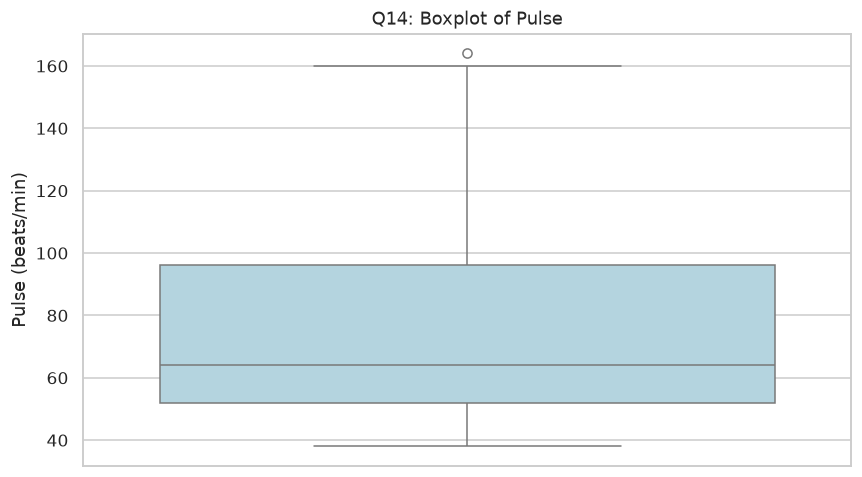

Q15: Pulse outliers using 1.5 × IQR


3    164.0
Name: pulse, dtype: float64

Q16: Extreme outliers removed using 3 × IQR: 0
Data without extreme pulse outliers


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,NaN,decreased,distend_large,45.0,8.4,NaN,NaN,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,NaN,normal,normal,33.0,6.7,NaN,NaN,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,NaN,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,NaN,NaN,NaN,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,NaN,decreased,firm,NaN,NaN,NaN,NaN,lived,no,0.0,0.0,0.0,no


In [15]:
sns.boxplot(y=data["pulse"], color="lightblue")
finish("Q14: Boxplot of Pulse", ylabel="Pulse (beats/min)")
q1, q3 = data["pulse"].quantile([.25, .75])
iqr_val = q3 - q1
outlier_mask = data["pulse"].lt(q1 - 1.5 * iqr_val) | data["pulse"].gt(q3 + 1.5 * iqr_val)
show("Q15: Pulse outliers using 1.5 × IQR", data.loc[outlier_mask, "pulse"])
keep = data["pulse"].isna() | data["pulse"].between(q1 - 3 * iqr_val, q3 + 3 * iqr_val)
data_no_outliers = data.loc[keep].copy()
print("Q16: Extreme outliers removed using 3 × IQR:", int((~keep).sum()))
show("Data without extreme pulse outliers", data_no_outliers.head(6))


### Q17–Q20 Histograms, density, violin, and dot plots


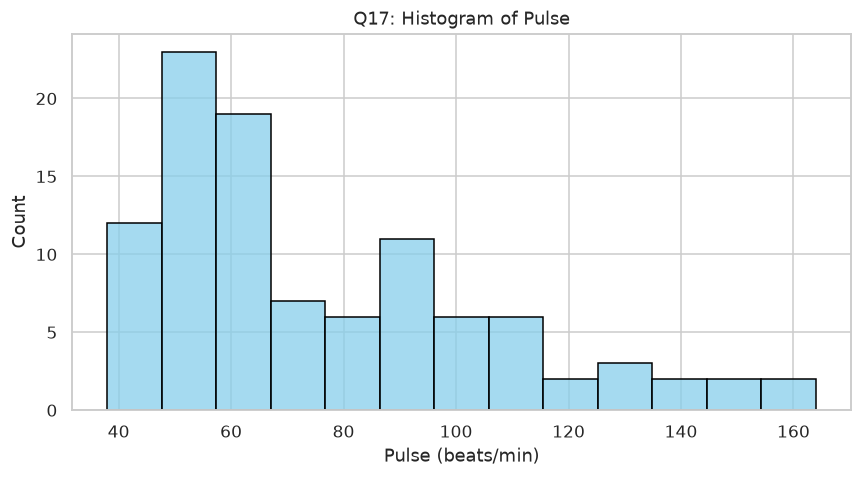

Pulse distribution: n=101, median=64.0, middle 50%=52.0–96.0; right-skewed (skewness=0.97).


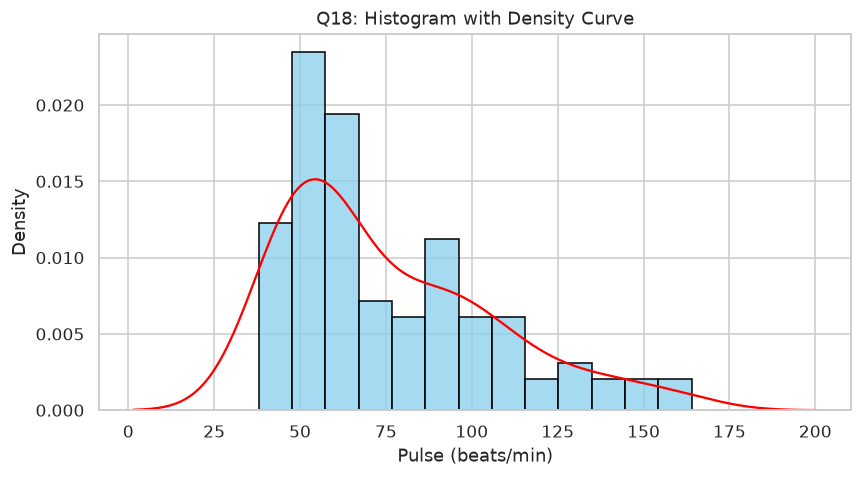

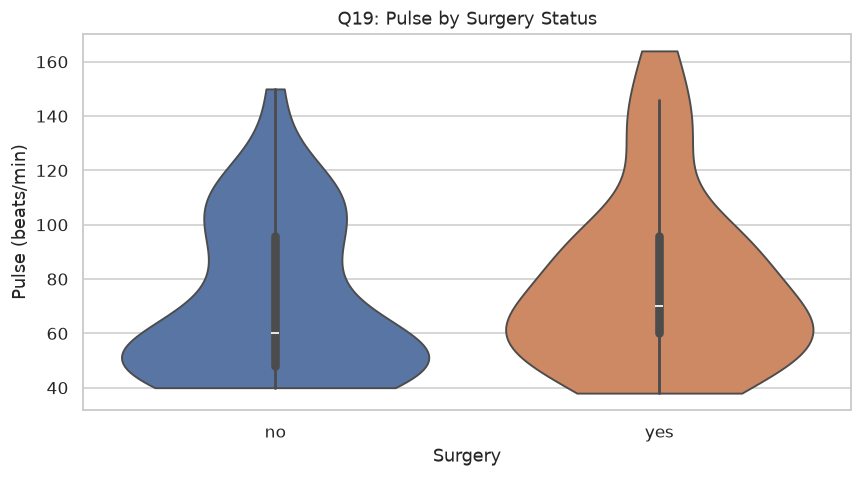

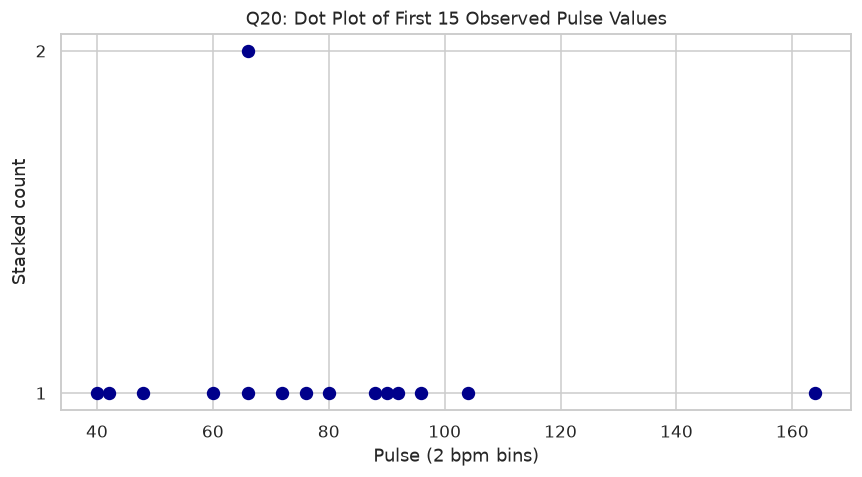

In [16]:
sns.histplot(data=data, x="pulse", binwidth=10, color="skyblue", edgecolor="black")
finish("Q17: Histogram of Pulse", "Pulse (beats/min)", "Count")
describe_distribution(data["pulse"], "Pulse distribution")
sns.histplot(data=data, x="pulse", binwidth=10, stat="density", color="skyblue", edgecolor="black")
sns.kdeplot(data=data, x="pulse", color="red")
finish("Q18: Histogram with Density Curve", "Pulse (beats/min)", "Density")
sns.violinplot(data=data.dropna(subset=["surgery", "pulse"]), x="surgery", y="pulse", hue="surgery", legend=False, cut=0)
finish("Q19: Pulse by Surgery Status", "Surgery", "Pulse (beats/min)")
small_data = data["pulse"].dropna().head(15)
small_bins = (small_data / 2).round() * 2
stack_positions = small_bins.groupby(small_bins).cumcount() + 1
plt.scatter(small_bins, stack_positions, color="darkblue", s=60)
plt.yticks(range(1, int(stack_positions.max()) + 1))
finish("Q20: Dot Plot of First 15 Observed Pulse Values", "Pulse (2 bpm bins)", "Stacked count")


### Q21–Q26 Categorical frequencies and charts


Q21–Q22: Outcome distribution


,Frequency,Proportion,Percentage
outcome,,,
died,30,0.275229,27.522936
euthanized,15,0.137615,13.761468
lived,64,0.587156,58.715596


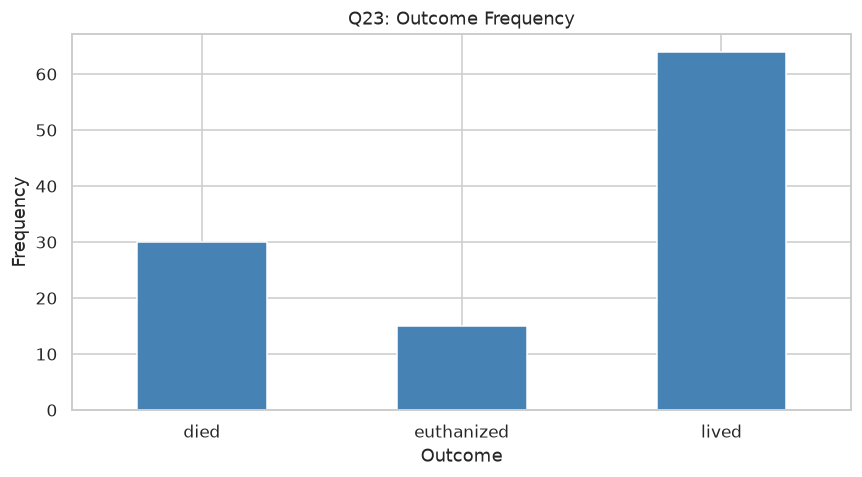

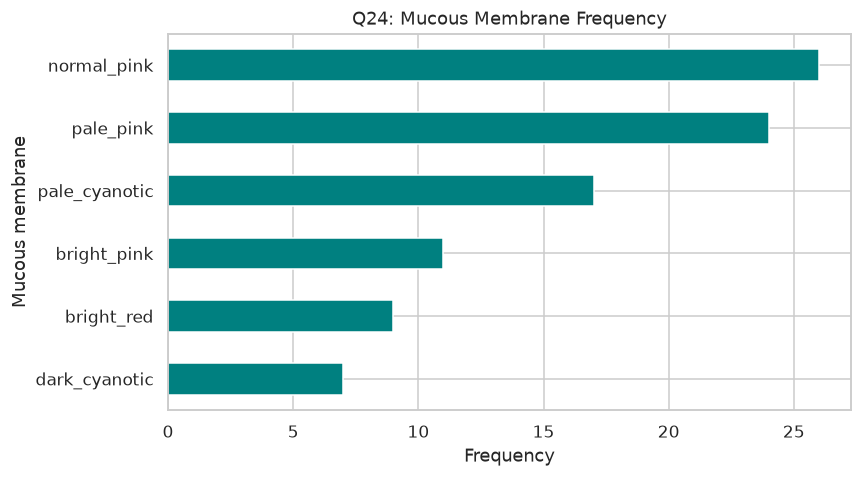

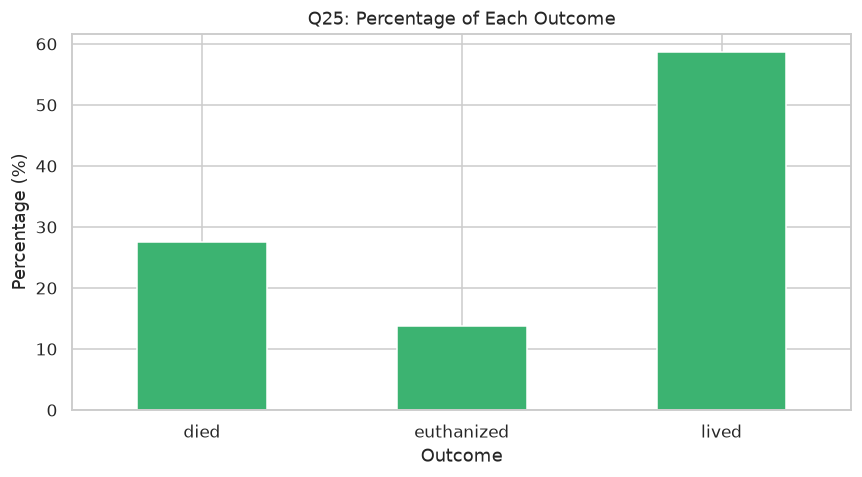

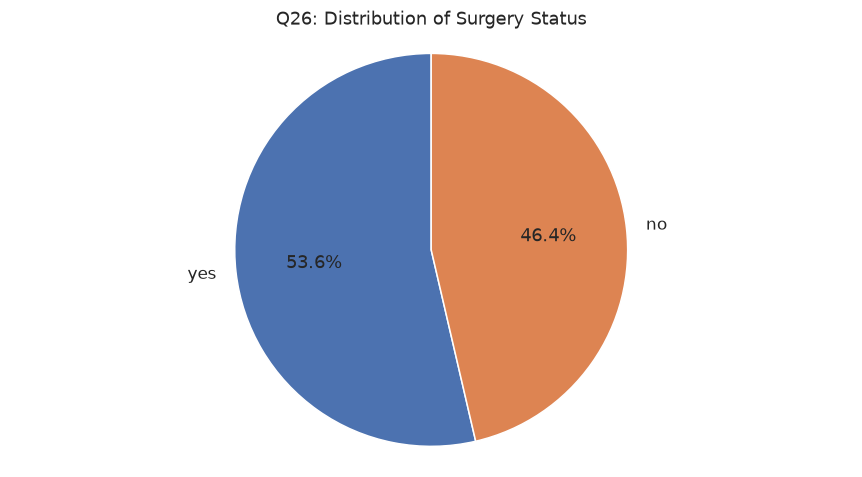

In [17]:
freq_table = data["outcome"].value_counts().sort_index()
prop_table = freq_table / freq_table.sum()
perc_table = prop_table * 100
show("Q21–Q22: Outcome distribution", pd.DataFrame({"Frequency": freq_table, "Proportion": prop_table, "Percentage": perc_table}))
freq_table.plot.bar(color="steelblue", rot=0)
finish("Q23: Outcome Frequency", "Outcome", "Frequency")
data["mucous_membrane"].value_counts().sort_values().plot.barh(color="teal")
finish("Q24: Mucous Membrane Frequency", "Frequency", "Mucous membrane")
perc_table.plot.bar(color="mediumseagreen", rot=0)
finish("Q25: Percentage of Each Outcome", "Outcome", "Percentage (%)")
surgery_counts = data["surgery"].value_counts()
plt.pie(surgery_counts, labels=surgery_counts.index, autopct="%1.1f%%", startangle=90)
plt.axis("equal")
finish("Q26: Distribution of Surgery Status")


### Q27–Q30 Lollipop, dot, density, and faceted charts


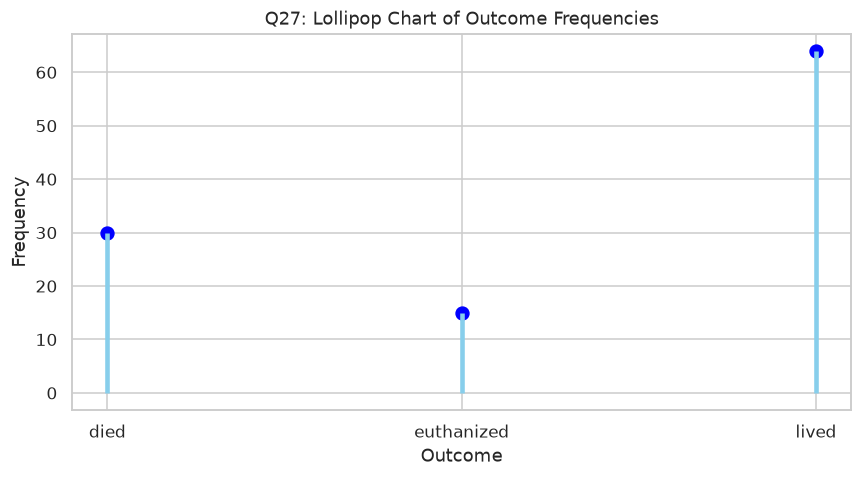

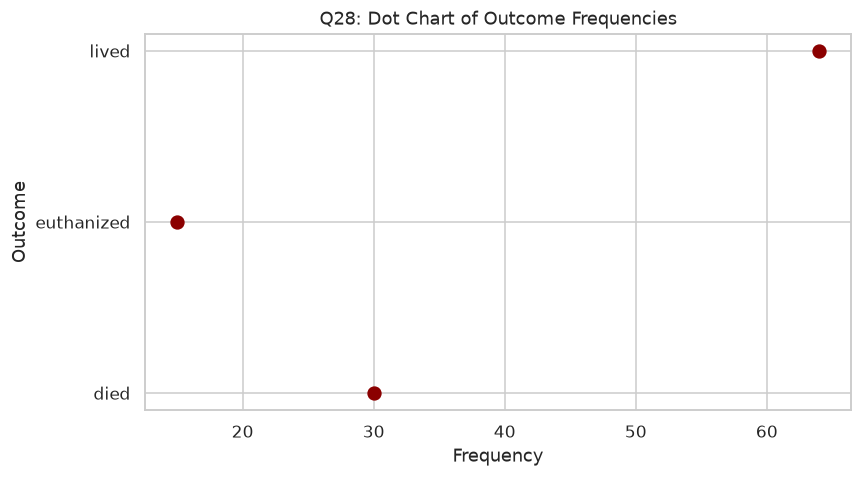

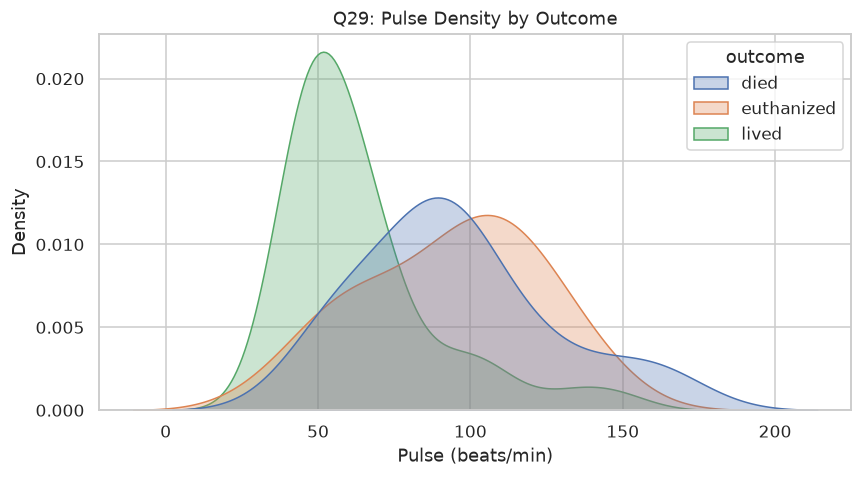

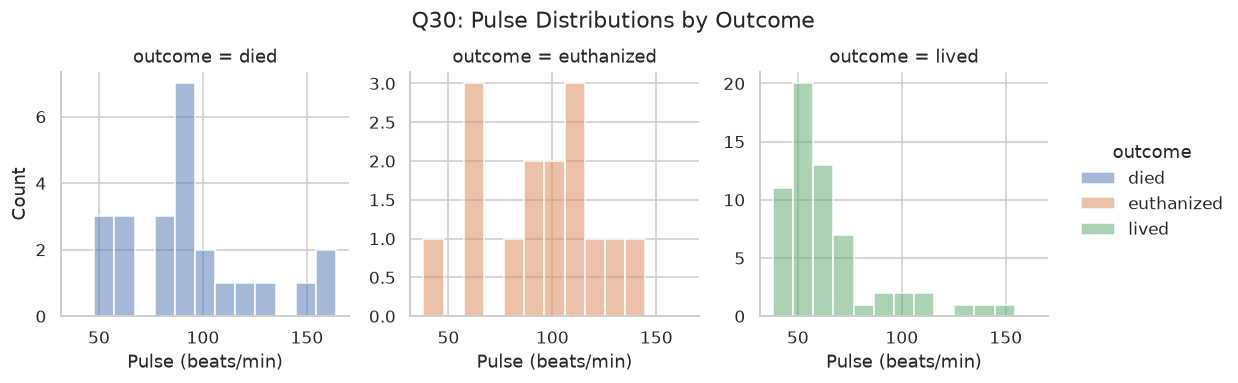

died: n=24, median=90.0, middle 50%=76.5–106.5; right-skewed (skewness=0.74).
euthanized: n=15, median=100.0, middle 50%=70.0–113.0; approximately symmetric (skewness=-0.29).
lived: n=61, median=54.0, middle 50%=48.0–72.0; right-skewed (skewness=1.79).


In [18]:
plt.vlines(freq_table.index, 0, freq_table.values, color="skyblue", linewidth=3)
plt.scatter(freq_table.index, freq_table.values, color="blue", s=70)
finish("Q27: Lollipop Chart of Outcome Frequencies", "Outcome", "Frequency")
plt.scatter(freq_table.values, freq_table.index, color="darkred", s=70)
finish("Q28: Dot Chart of Outcome Frequencies", "Frequency", "Outcome")
sns.kdeplot(data=data.dropna(subset=["pulse", "outcome"]), x="pulse", hue="outcome", fill=True, common_norm=False, alpha=.3)
finish("Q29: Pulse Density by Outcome", "Pulse (beats/min)", "Density")
g = sns.displot(data=data.dropna(subset=["pulse", "outcome"]), x="pulse", col="outcome", hue="outcome", binwidth=10, height=3.3, facet_kws={"sharey": False})
g.set_axis_labels("Pulse (beats/min)", "Count")
g.figure.suptitle("Q30: Pulse Distributions by Outcome", y=1.05)
plt.show()
for outcome, group in data.dropna(subset=["outcome"]).groupby("outcome"):
    describe_distribution(group["pulse"], str(outcome))


## Assignment 4 — Bivariate Analysis

This assignment examines relationships between two variables using contingency tables, bar charts, scatter and line plots, density plots, and grouped box and violin plots. It summarizes relationships among five clinical measurements with a correlation heatmap and a correlogram.

### Questions

1. Load the dataset shared in your mail into the R programming
environment and perform the following bivariate analysis and
visualization tasks.

2. Select two suitable categorical variables, create a contingency table,
and display their relationship using: a simple stacked bar plot using
Base R, and a stacked bar plot using ggplot2.

3. Select two suitable categorical variables and create a grouped/side-
by-side bar plot to compare their frequency distributions.

4. Select two suitable numerical variables and generate a scatter plot
to analyze the relationship between them.

5. Select two appropriate variables and construct a line plot to
visualize their relationship or trend.

6. Select suitable numerical variables and generate a heatmap to
represent the relationship among the variables.

7. Select suitable variables and construct a bar chart to compare the
values or frequencies between two variables.

8. Select one numerical variable and one categorical variable and
generate a density plot to compare the distribution of the numerical
variable across different categories.

9. Select one categorical variable and one numerical variable and
create a box plot to compare the distribution of the numerical
variable across different groups.

10. Select one categorical variable and one numerical variable and
construct a violin plot to visualize the distribution and density of the
numerical variable across categories.

11. Select suitable categorical and numerical variables and visualize
their distribution by combining a violin plot and box plot in a single
graphical representation.


12. Select suitable numerical variables, compute their correlation
matrix, and generate a correlogram to study the strength and
direction of relationships among the variables.

13. Provide suitable titles, axis labels, legends, and graphical
parameters for all the plots generated.


### Q1–Q3 Load, cross-tabulate, and compare categories


Dataset preview


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,NaN,decreased,distend_large,45.0,8.4,NaN,NaN,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,NaN,normal,normal,33.0,6.7,NaN,NaN,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,NaN,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,NaN,NaN,NaN,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,NaN,decreased,firm,NaN,NaN,NaN,NaN,lived,no,0.0,0.0,0.0,no


Outcome × Surgery contingency table


surgery,no,yes
outcome,,
died,9,21
euthanized,8,7
lived,34,30


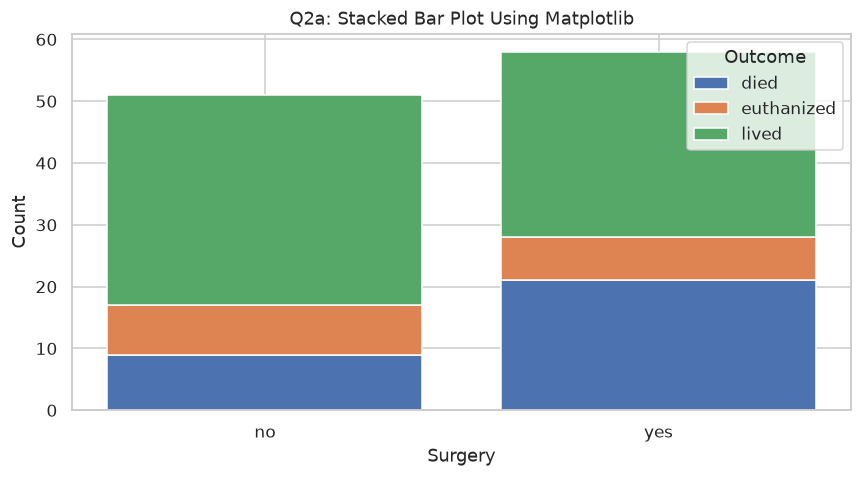

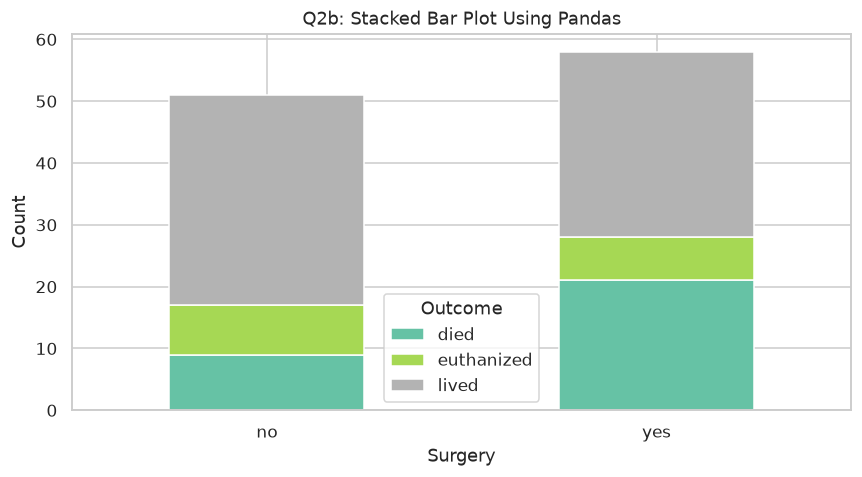

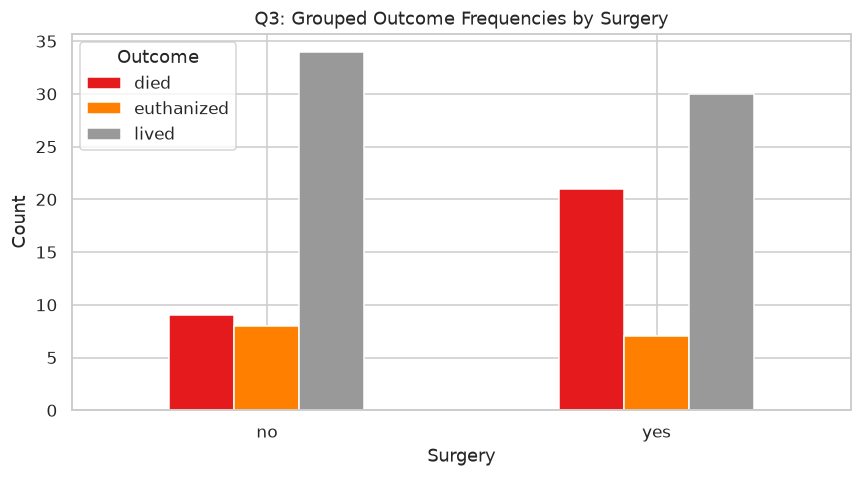

In [19]:
data = load_horse()
show("Dataset preview", data.head(6))
cat_tab = pd.crosstab(data["outcome"], data["surgery"])
show("Outcome × Surgery contingency table", cat_tab)
fig, ax = plt.subplots()
bottom = np.zeros(len(cat_tab.columns))
for outcome, row in cat_tab.iterrows():
    ax.bar(cat_tab.columns, row.to_numpy(), bottom=bottom, label=outcome)
    bottom += row.to_numpy()
ax.legend(title="Outcome")
finish("Q2a: Stacked Bar Plot Using Matplotlib", "Surgery", "Count")
cat_tab.T.plot.bar(stacked=True, colormap="Set2", rot=0)
plt.legend(title="Outcome")
finish("Q2b: Stacked Bar Plot Using Pandas", "Surgery", "Count")
cat_tab.T.plot.bar(stacked=False, colormap="Set1", rot=0)
plt.legend(title="Outcome")
finish("Q3: Grouped Outcome Frequencies by Surgery", "Surgery", "Count")


### Q4–Q7 Numerical relationships and group means


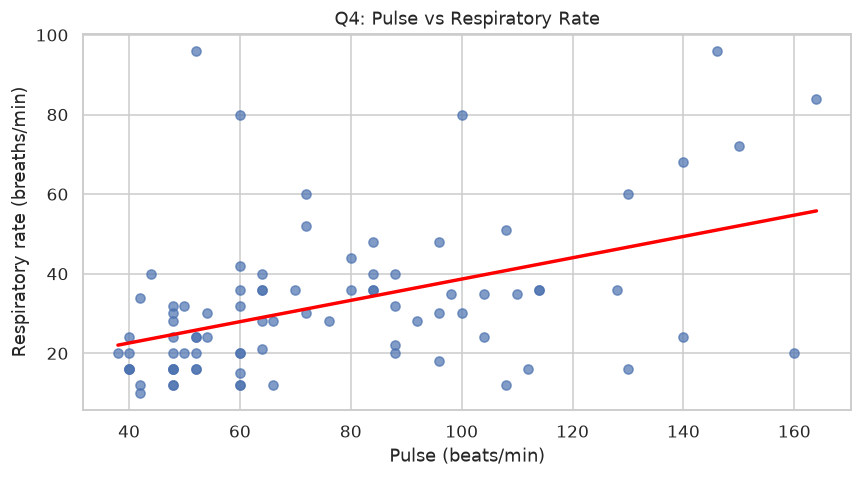

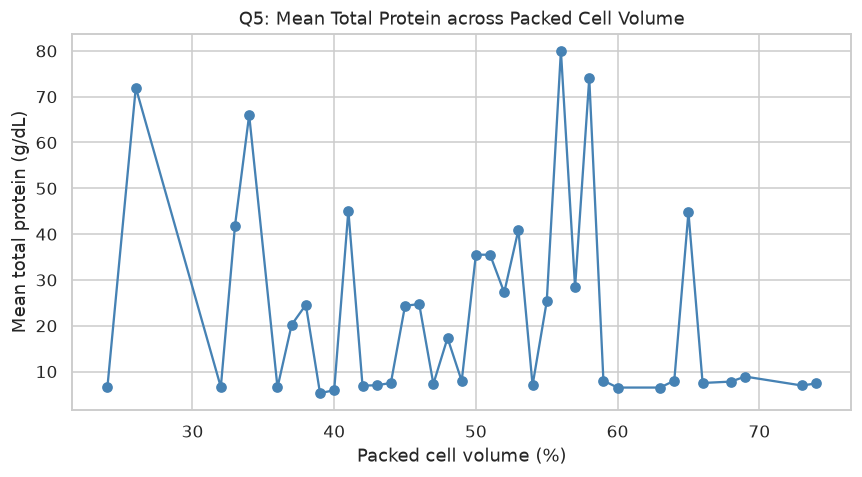

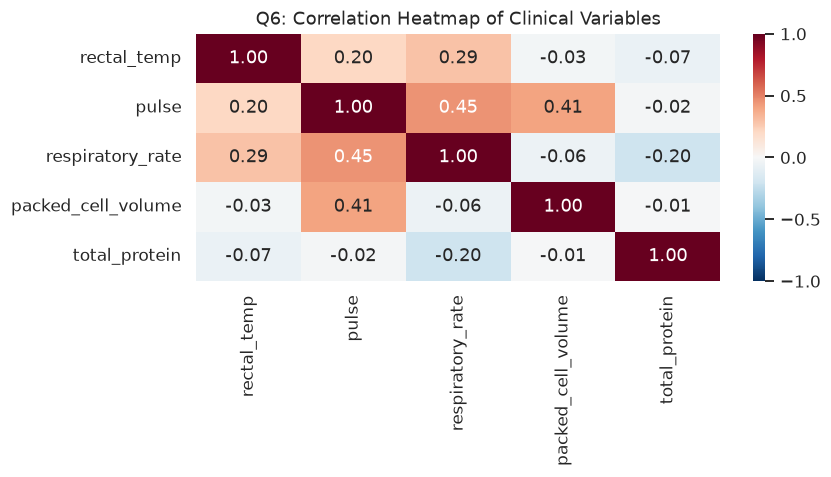

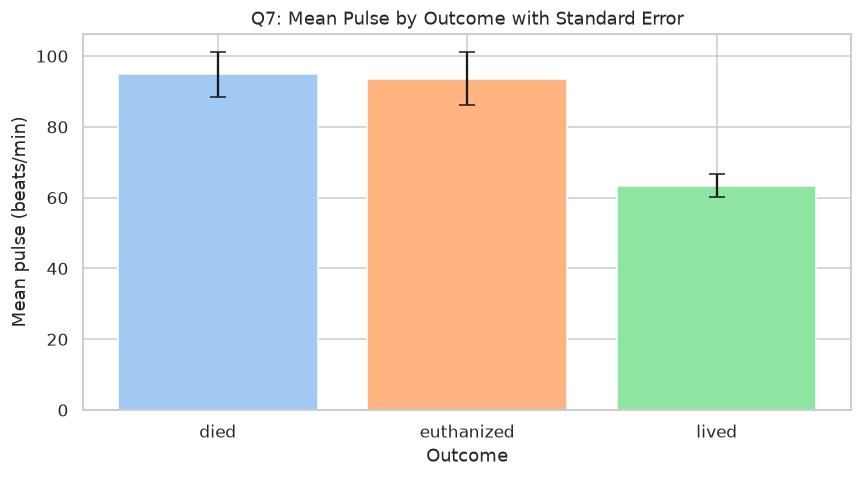

In [20]:
sns.regplot(data=data, x="pulse", y="respiratory_rate", ci=None, scatter_kws={"alpha": .7}, line_kws={"color": "red"})
finish("Q4: Pulse vs Respiratory Rate", "Pulse (beats/min)", "Respiratory rate (breaths/min)")
mean_trend = data.dropna(subset=["packed_cell_volume", "total_protein"]).groupby("packed_cell_volume")["total_protein"].mean().sort_index()
plt.plot(mean_trend.index, mean_trend, marker="o", color="steelblue")
finish("Q5: Mean Total Protein across Packed Cell Volume", "Packed cell volume (%)", "Mean total protein (g/dL)")
cor_matrix = data[clinical_columns].corr()
sns.heatmap(cor_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0)
finish("Q6: Correlation Heatmap of Clinical Variables")
grouped = data.groupby("outcome")["pulse"].agg(["mean", "sem"])
plt.bar(grouped.index, grouped["mean"], yerr=grouped["sem"], capsize=5, color=sns.color_palette("pastel", len(grouped)))
finish("Q7: Mean Pulse by Outcome with Standard Error", "Outcome", "Mean pulse (beats/min)")


### Q8–Q11 Grouped distributions


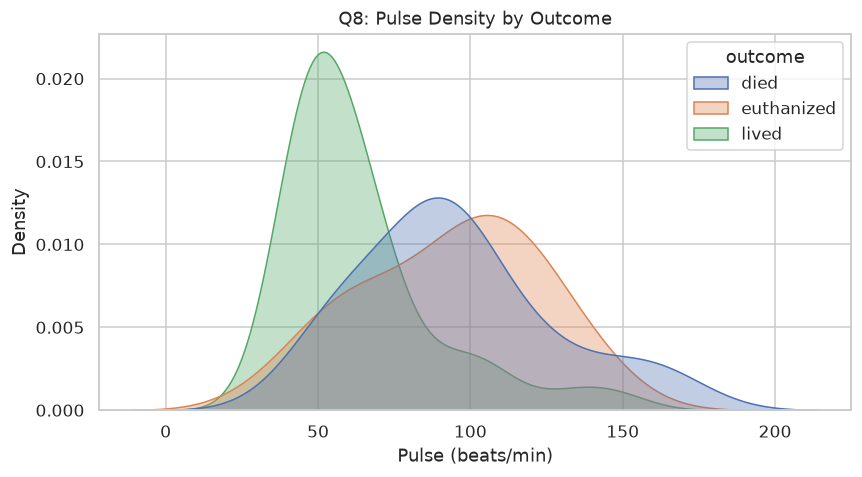

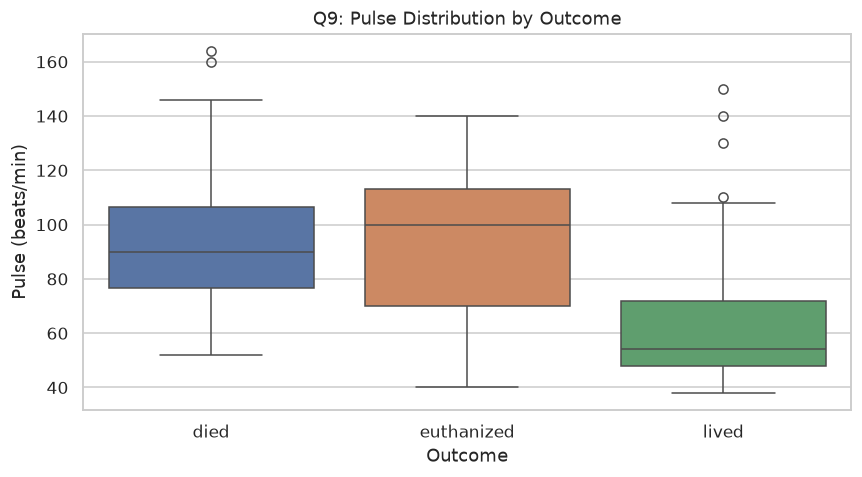

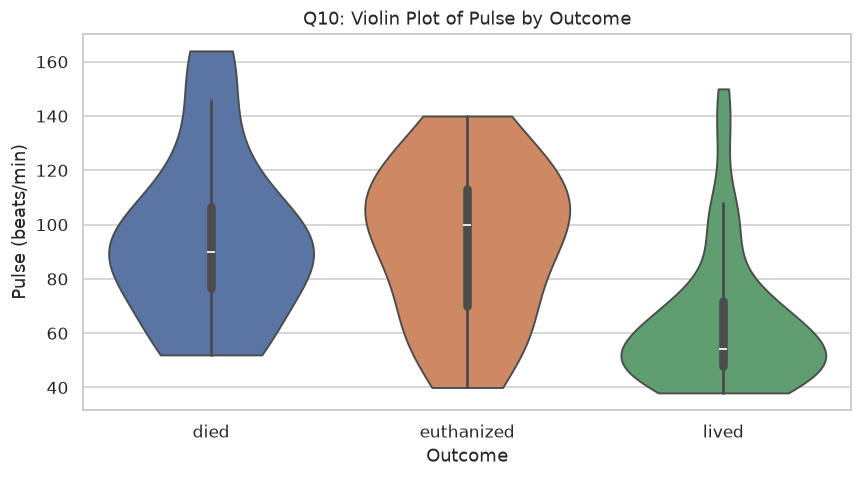

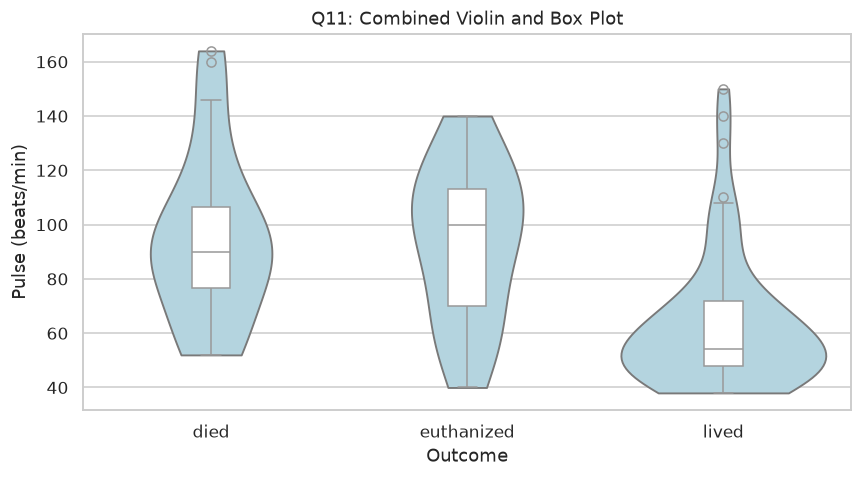

In [21]:
plot_data = data.dropna(subset=["outcome", "pulse"])
sns.kdeplot(data=plot_data, x="pulse", hue="outcome", fill=True, alpha=.35, common_norm=False)
finish("Q8: Pulse Density by Outcome", "Pulse (beats/min)", "Density")
sns.boxplot(data=plot_data, x="outcome", y="pulse", hue="outcome", legend=False)
finish("Q9: Pulse Distribution by Outcome", "Outcome", "Pulse (beats/min)")
sns.violinplot(data=plot_data, x="outcome", y="pulse", hue="outcome", legend=False, cut=0)
finish("Q10: Violin Plot of Pulse by Outcome", "Outcome", "Pulse (beats/min)")
sns.violinplot(data=plot_data, x="outcome", y="pulse", color="lightblue", inner=None, cut=0)
sns.boxplot(data=plot_data, x="outcome", y="pulse", width=.15, color="white")
finish("Q11: Combined Violin and Box Plot", "Outcome", "Pulse (beats/min)")


### Q12–Q13 Correlation matrix and correlogram


Correlation matrix


,rectal_temp,pulse,respiratory_rate,packed_cell_volume,total_protein
rectal_temp,1.000,0.204,0.290,-0.028,-0.070
pulse,0.204,1.000,0.446,0.406,-0.022
respiratory_rate,0.290,0.446,1.000,-0.058,-0.204
packed_cell_volume,-0.028,0.406,-0.058,1.000,-0.012
total_protein,-0.070,-0.022,-0.204,-0.012,1.000


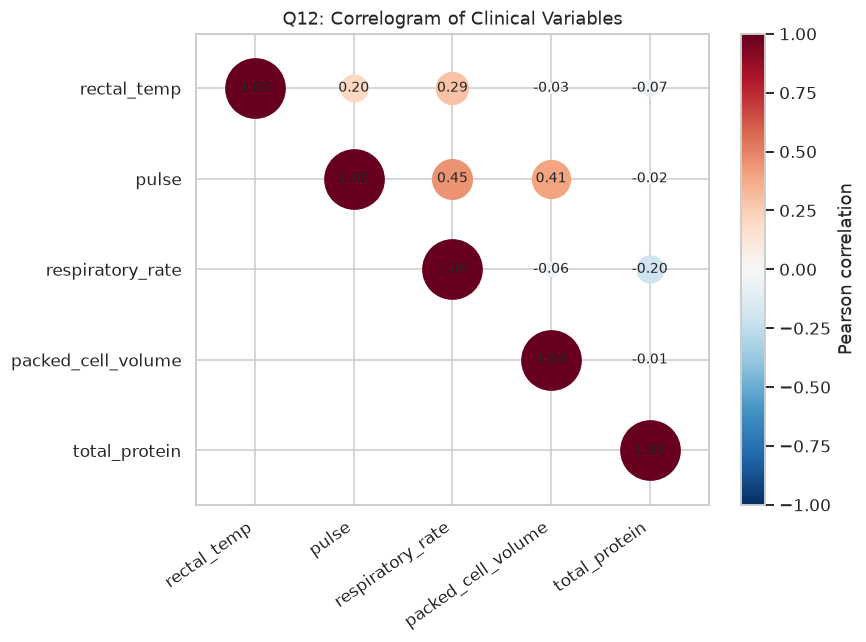

Q13: Titles, axis labels, legends, readable sizes, and consistent styling are applied throughout.


In [22]:
show("Correlation matrix", cor_matrix.round(3))
order = linkage(pdist(cor_matrix.to_numpy()), method="complete")
ordered_idx = dendrogram(order, no_plot=True)["leaves"]
ordered_cor = cor_matrix.iloc[ordered_idx, ordered_idx]
fig, ax = plt.subplots(figsize=(8, 6))
for i in range(len(ordered_cor)):
    for j in range(i, len(ordered_cor)):
        value = ordered_cor.iloc[i, j]
        ax.scatter(j, i, s=abs(value) * 1500, c=[value], cmap="RdBu_r", vmin=-1, vmax=1)
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(len(ordered_cor)), ordered_cor.columns, rotation=35, ha="right")
ax.set_yticks(range(len(ordered_cor)), ordered_cor.index)
ax.set_xlim(-.6, len(ordered_cor) - .4)
ax.set_ylim(len(ordered_cor) - .4, -.6)
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(-1, 1), cmap="RdBu_r"), ax=ax, label="Pearson correlation")
finish("Q12: Correlogram of Clinical Variables")
print("Q13: Titles, axis labels, legends, readable sizes, and consistent styling are applied throughout.")


## Assignment 5 — Multivariate Analysis

This assignment maps several clinical variables to position, color, shape, and point size. Faceted scatter plots compare groups, while a pairs plot and parallel coordinate plot show relationships across multiple measurements.

### Questions

1. Load the dataset shared through e-mail into the R environment. Examine the dataset and identify the numerical and categorical variables.
2. Create a scatter plot involving three variables, where two numerical variables arerepresented on the X- and Y-axes, and the third variable is represented using color.
3. Create a scatter plot involving four variables, where two numerical variables arerepresented on the X- and Y-axes, the third variable is represented using color, and the fourth variable is represented using shape.
4. Create a scatter plot involving four variables, where two numerical variables arerepresented on the X- and Y-axes, the third variable is represented using color, and the fourthnumerical variable is represented using point size.
5. Construct a bubble plot using three numerical variables, where two variables arerepresented on the X- and Y-axes, and the third variable determines the size of the bubbles.
6. Generate subplots using facet_wrap() by selecting an appropriate categorical variablefrom the dataset.
7. Generate subplots using facet_grid() by selecting two appropriate categoricalvariables from the dataset. Arrange the plots in rows and columns and compare the patterns observed across the different groups.
8. Construct a pairs plot using at least four numerical variables from the dataset. Use the plot to identify possible relationships and correlations among the selected variables.
9. Create a parallel coordinate plot using at least four numerical variables from thedataset. Differentiate the observations using an appropriate categorical variable.


### Q1 Identify numerical and categorical variables


In [23]:
data = load_horse()
print("Numerical variables:", data.select_dtypes(include="number").columns.tolist())
print("Categorical variables:", data.select_dtypes(exclude="number").columns.tolist())


Numerical variables: ['hospital_number', 'rectal_temp', 'pulse', 'respiratory_rate', 'nasogastric_reflux_ph', 'packed_cell_volume', 'total_protein', 'abdomo_protein', 'lesion_1', 'lesion_2', 'lesion_3']
Categorical variables: ['surgery', 'age', 'temp_of_extremities', 'peripheral_pulse', 'mucous_membrane', 'capillary_refill_time', 'pain', 'peristalsis', 'abdominal_distention', 'nasogastric_tube', 'nasogastric_reflux', 'rectal_exam_feces', 'abdomen', 'abdomo_appearance', 'outcome', 'surgical_lesion', 'cp_data']


### Q2–Q5 Scatter and bubble plots


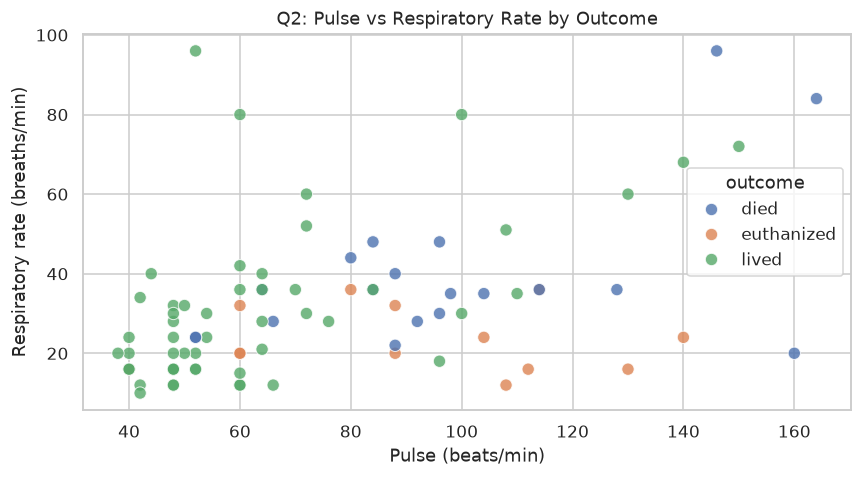

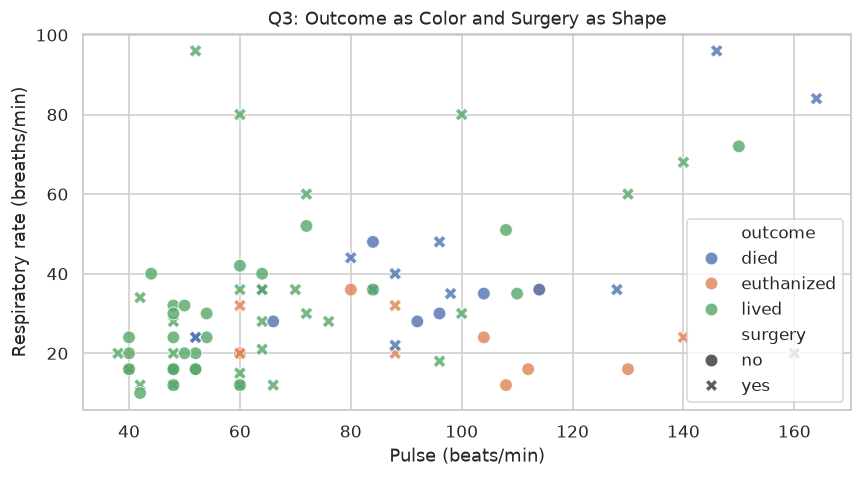

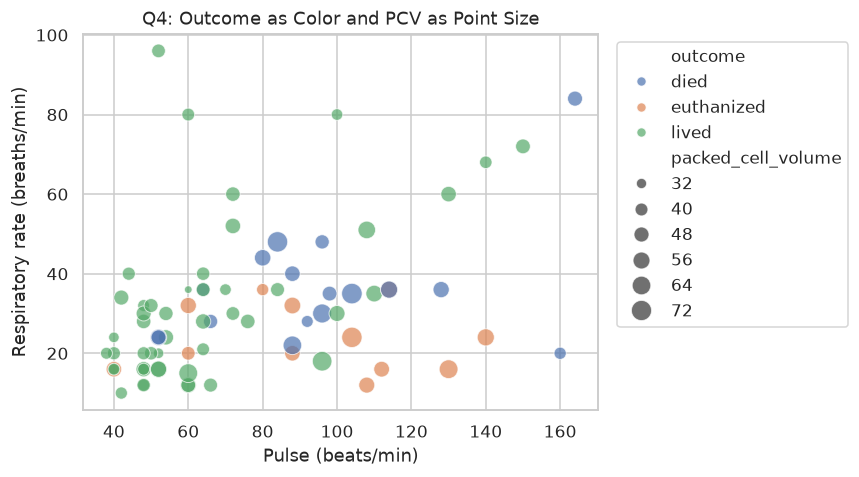

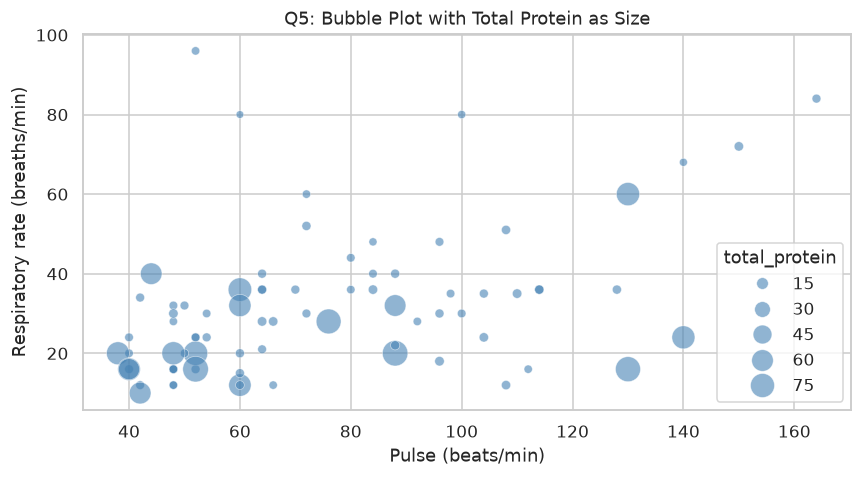

In [24]:
sns.scatterplot(data=data.dropna(subset=["pulse", "respiratory_rate", "outcome"]), x="pulse", y="respiratory_rate", hue="outcome", s=65, alpha=.8)
finish("Q2: Pulse vs Respiratory Rate by Outcome", "Pulse (beats/min)", "Respiratory rate (breaths/min)")
sns.scatterplot(data=data.dropna(subset=["pulse", "respiratory_rate", "outcome", "surgery"]), x="pulse", y="respiratory_rate", hue="outcome", style="surgery", s=70, alpha=.8)
finish("Q3: Outcome as Color and Surgery as Shape", "Pulse (beats/min)", "Respiratory rate (breaths/min)")
sns.scatterplot(data=data.dropna(subset=["pulse", "respiratory_rate", "outcome", "packed_cell_volume"]), x="pulse", y="respiratory_rate", hue="outcome", size="packed_cell_volume", sizes=(25, 180), alpha=.7)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
finish("Q4: Outcome as Color and PCV as Point Size", "Pulse (beats/min)", "Respiratory rate (breaths/min)")
sns.scatterplot(data=data.dropna(subset=["pulse", "respiratory_rate", "total_protein"]), x="pulse", y="respiratory_rate", size="total_protein", sizes=(25, 280), color="steelblue", alpha=.6)
finish("Q5: Bubble Plot with Total Protein as Size", "Pulse (beats/min)", "Respiratory rate (breaths/min)")


### Q6–Q7 Faceted scatter plots


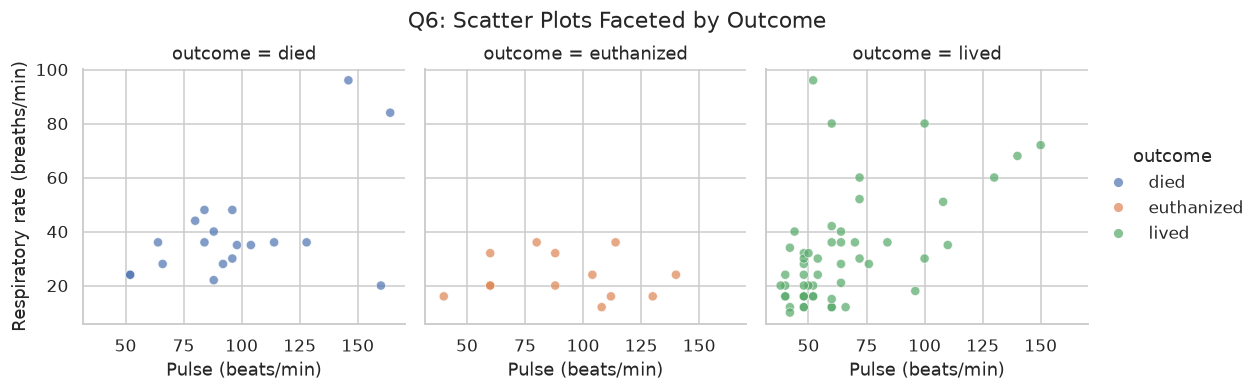

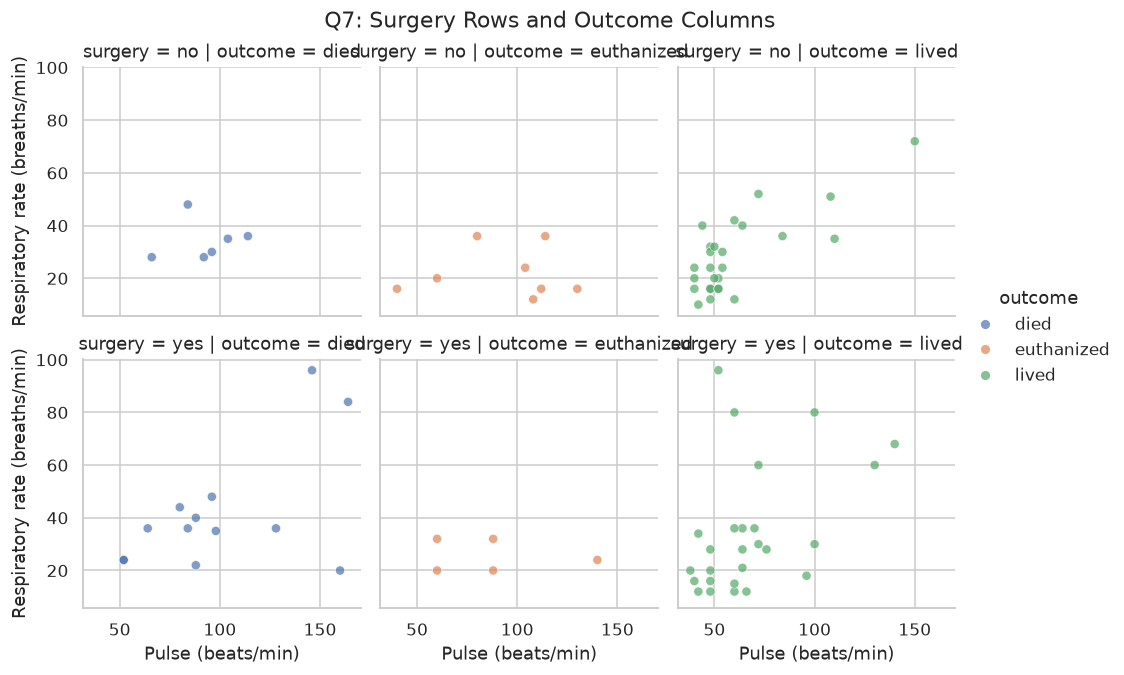

Group patterns: mean pulse and respiratory rate


pulse            respiratory_rate           
                   count       mean            count       mean
surgery outcome                                                
no      died           8  96.500000                6  34.166667
        euthanized     8  93.500000                8  22.000000
        lived         32  60.437500               26  28.384615
yes     died          16  94.000000               15  39.266667
        euthanized     7  93.714286                5  25.600000
        lived         29  66.620690               26  34.769231

In [25]:
g = sns.relplot(data=data.dropna(subset=["pulse", "respiratory_rate", "outcome"]), x="pulse", y="respiratory_rate", col="outcome", hue="outcome", height=3.4, alpha=.7)
g.set_axis_labels("Pulse (beats/min)", "Respiratory rate (breaths/min)")
g.figure.suptitle("Q6: Scatter Plots Faceted by Outcome", y=1.04)
plt.show()
g = sns.relplot(data=data.dropna(subset=["pulse", "respiratory_rate", "surgery", "outcome"]), x="pulse", y="respiratory_rate", row="surgery", col="outcome", hue="outcome", height=3, alpha=.7)
g.set_axis_labels("Pulse (beats/min)", "Respiratory rate (breaths/min)")
g.figure.suptitle("Q7: Surgery Rows and Outcome Columns", y=1.02)
plt.show()
show("Group patterns: mean pulse and respiratory rate", data.groupby(["surgery", "outcome"])[["pulse", "respiratory_rate"]].agg(["count", "mean"]))


### Q8 Pairs plot


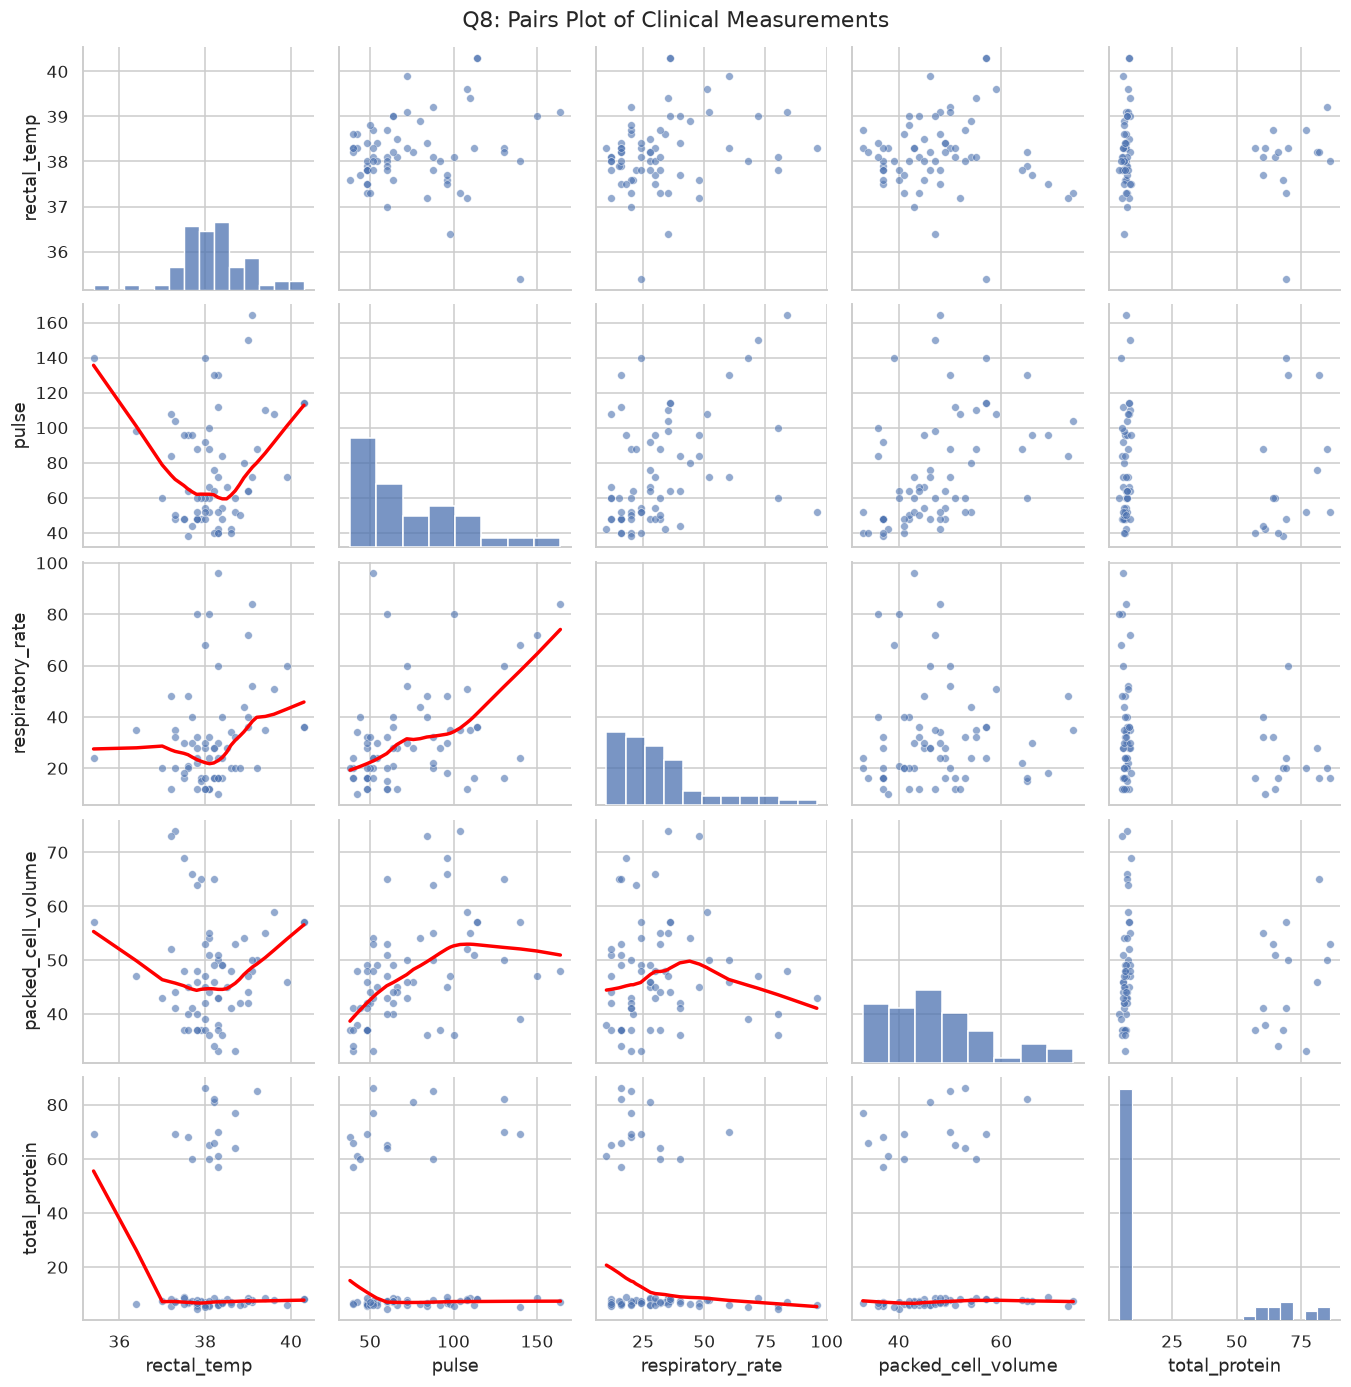

Largest absolute Pearson correlation: pulse vs packed_cell_volume = 0.449


In [26]:
num_subset = data[clinical_columns].dropna()
g = sns.pairplot(num_subset, diag_kind="hist", plot_kws={"alpha": .6, "s": 25})
g.map_lower(sns.regplot, scatter=False, ci=None, lowess=True, line_kws={"color": "red"})
g.figure.suptitle("Q8: Pairs Plot of Clinical Measurements", y=1.01)
plt.show()
pair_correlations = num_subset.corr()
upper = pair_correlations.where(np.triu(np.ones(pair_correlations.shape), k=1).astype(bool)).stack()
strongest = upper.abs().idxmax()
print(f"Largest absolute Pearson correlation: {strongest[0]} vs {strongest[1]} = {upper.loc[strongest]:.3f}")


### Q9 Parallel coordinate plot


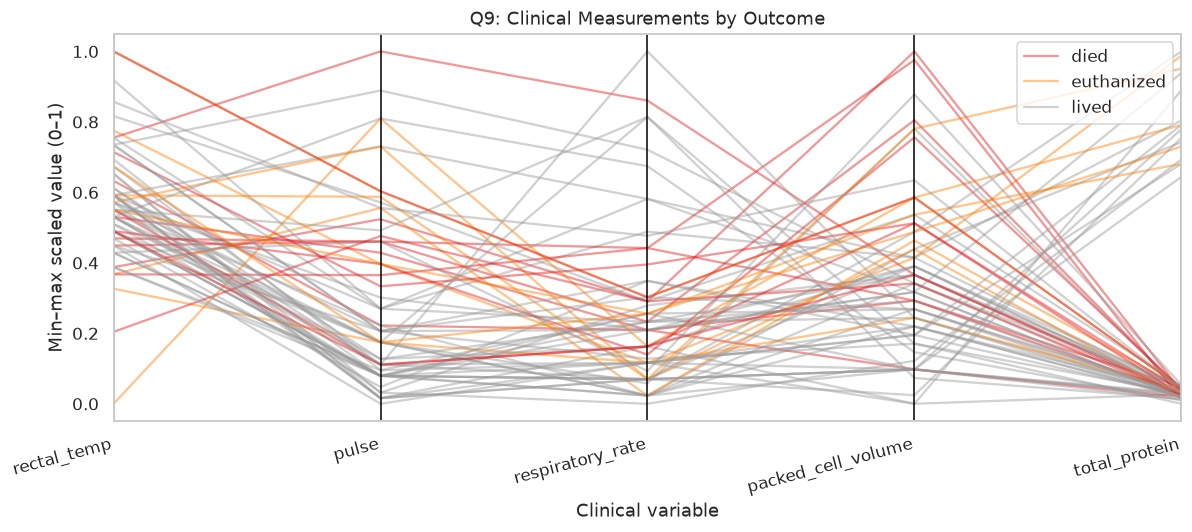

In [27]:
parcoord_data = data[clinical_columns + ["outcome"]].dropna().copy()
span = parcoord_data[clinical_columns].max() - parcoord_data[clinical_columns].min()
parcoord_data[clinical_columns] = (parcoord_data[clinical_columns] - parcoord_data[clinical_columns].min()) / span.replace(0, 1)
plt.figure(figsize=(11, 5))
pd.plotting.parallel_coordinates(parcoord_data, "outcome", cols=clinical_columns, alpha=.45, colormap="Set1")
plt.xticks(rotation=15, ha="right")
finish("Q9: Clinical Measurements by Outcome", "Clinical variable", "Min–max scaled value (0–1)")


## Assignment 6 — Time Series Analysis

This assignment explores the monthly AirPassengers series, decomposes its multiplicative components, and inspects autocorrelation. It fits the same seasonal ARIMA specification as the R solution and forecasts the next 12 months with prediction intervals.

### Questions

Perform the following steps using the built-in AirPassengers dataset in R:

1. Load the built-in AirPassengers dataset in R.
2. Explore the first five and last five observations of the dataset.
3. Identify the starting and ending time periods of the dataset. (start, end)
4. Determine the frequency and time-series characteristics of the dataset. (frequency, class)
5. Visualize the monthly passenger trend over the entire period. (plot)
6. Decompose the time series into trend, seasonal, and random components. (decompose)
7. Plot the decomposed components to examine the underlying patterns.
8. Analyze the autocorrelation and partial autocorrelation of the time series. (acf, pacf)
9. Fit an ARIMA model to the AirPassengers time series. (arima)
10. Display and interpret the fitted ARIMA model parameters and model summary.(summary)
11. Forecast the number of passengers for the next 12 months using the fitted ARIMA model.(predict)
12. Visualize the actual and forecasted passenger values with appropriate labels and title.(plot, lines)


### Q1–Q4 Load and inspect AirPassengers


In [28]:
air_passenger_values = [
    112,118,132,129,121,135,148,148,136,119,104,118,
    115,126,141,135,125,149,170,170,158,133,114,140,
    145,150,178,163,172,178,199,199,184,162,146,166,
    171,180,193,181,183,218,230,242,209,191,172,194,
    196,196,236,235,229,243,264,272,237,211,180,201,
    204,188,235,227,234,264,302,293,259,229,203,229,
    242,233,267,269,270,315,364,347,312,274,237,278,
    284,277,317,313,318,374,413,405,355,306,271,306,
    315,301,356,348,355,422,465,467,404,347,305,336,
    340,318,362,348,363,435,491,505,404,359,310,337,
    360,342,406,396,420,472,548,559,463,407,362,405,
    417,391,419,461,472,535,622,606,508,461,390,432
]
AirPassengers = pd.Series(air_passenger_values, index=pd.date_range("1949-01-01", periods=144, freq="MS"), name="Passengers (thousands)")
show("First five observations", AirPassengers.head(5))
show("Last five observations", AirPassengers.tail(5))
print("Start:", AirPassengers.index[0].strftime("%Y-%m"))
print("End:", AirPassengers.index[-1].strftime("%Y-%m"))
print("Frequency: 12 observations per year; index frequency:", AirPassengers.index.freqstr)
print("Class:", type(AirPassengers).__name__, "with", type(AirPassengers.index).__name__)


First five observations


1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers (thousands), dtype: int64

Last five observations


1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: Passengers (thousands), dtype: int64

Start: 1949-01
End: 1960-12
Frequency: 12 observations per year; index frequency: MS
Class: Series with DatetimeIndex


### Q5–Q8 Trend, decomposition, ACF, and PACF


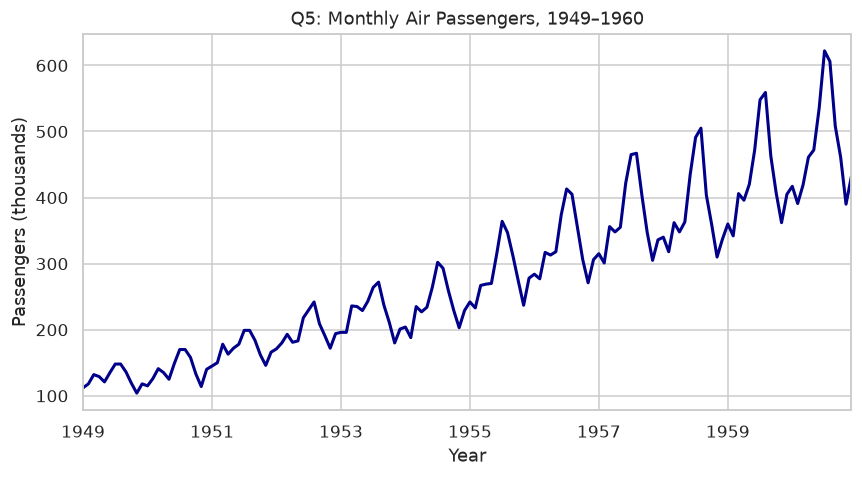

Q6: Decomposed components


,Observed,Trend,Seasonal,Random
1949-01-01,112,NaN,0.910230,NaN
1949-02-01,118,NaN,0.883625,NaN
1949-03-01,132,NaN,1.007366,NaN
1949-04-01,129,NaN,0.975906,NaN
1949-05-01,121,NaN,0.981378,NaN
1949-06-01,135,NaN,1.112776,NaN
1949-07-01,148,126.791667,1.226556,0.951664
1949-08-01,148,127.250000,1.219911,0.953401
1949-09-01,136,127.958333,1.060492,1.002220
1949-10-01,119,128.583333,0.921757,1.004028


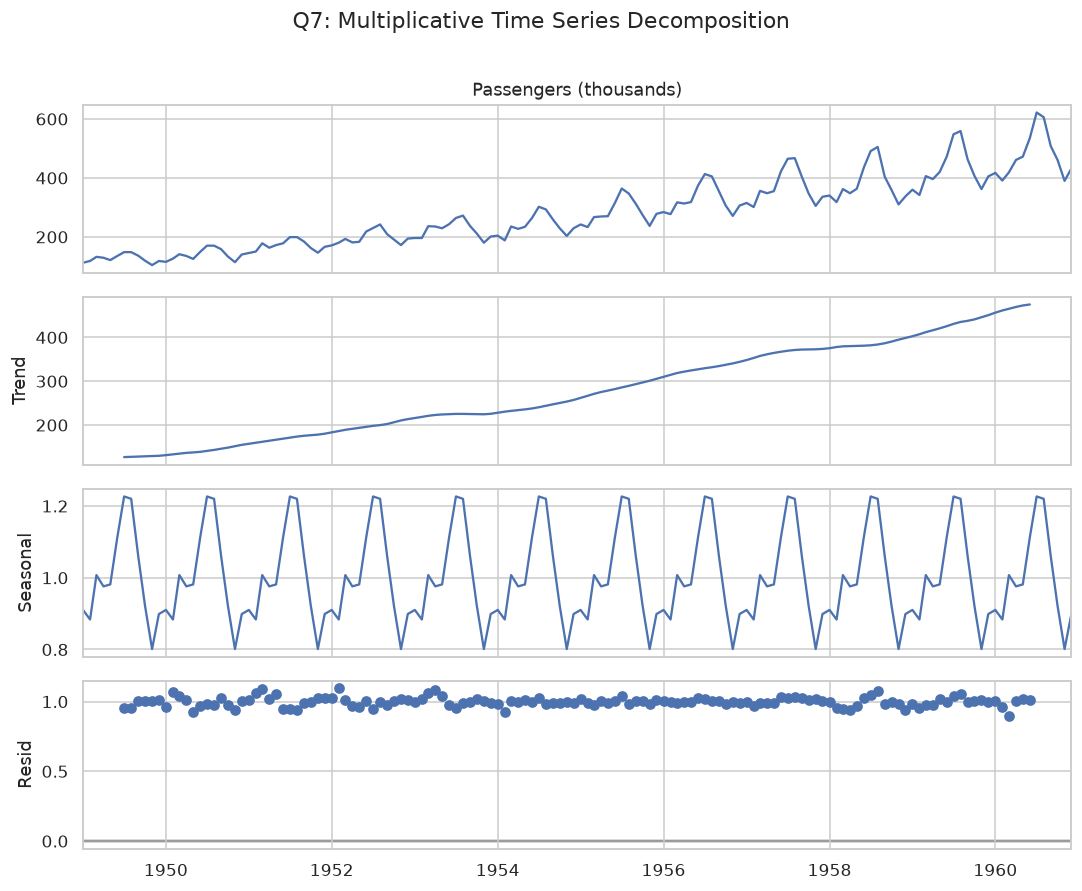

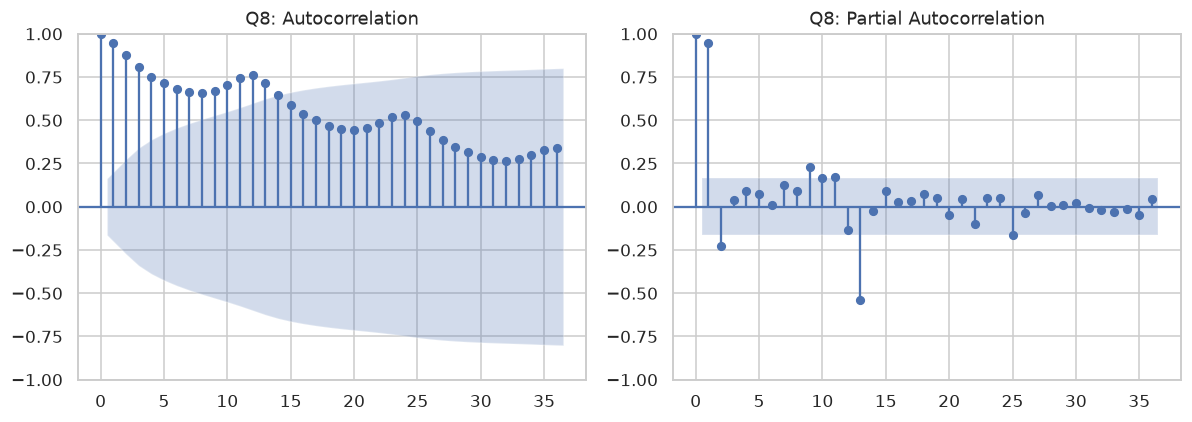

In [29]:
AirPassengers.plot(color="darkblue", linewidth=2)
finish("Q5: Monthly Air Passengers, 1949–1960", "Year", "Passengers (thousands)")
decomp = seasonal_decompose(AirPassengers, model="multiplicative", period=12)
show("Q6: Decomposed components", pd.DataFrame({"Observed": AirPassengers, "Trend": decomp.trend, "Seasonal": decomp.seasonal, "Random": decomp.resid}).head(14))
fig = decomp.plot()
fig.set_size_inches(10, 8)
fig.suptitle("Q7: Multiplicative Time Series Decomposition", y=1.01)
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_acf(AirPassengers, lags=36, ax=axes[0], title="Q8: Autocorrelation")
plot_pacf(AirPassengers, lags=36, method="ywmle", ax=axes[1], title="Q8: Partial Autocorrelation")
fig.tight_layout()
plt.show()


### Q9–Q10 Fit and interpret the seasonal ARIMA model


In [30]:
model = SARIMAX(AirPassengers, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12), trend="n")
fit = model.fit(disp=False, maxiter=500)
print(fit.summary())
print("SARIMA(0,1,1)(0,1,1)[12] uses first and annual seasonal differences.")
print("ma.L1 describes short-term shocks; ma.S.L12 describes shocks recurring after 12 months.")
parameter_table = pd.DataFrame({"Estimate": fit.params, "Standard error": fit.bse, "p-value": fit.pvalues})
show("Estimated parameters", parameter_table)
print(f"AIC = {fit.aic:.2f}; compare AIC only with models fitted to the same series.")
print("Coefficient uncertainty is assessed using confidence intervals and p-values; small standard errors alone do not establish significance.")


                                     SARIMAX Results                                      
Dep. Variable:             Passengers (thousands)   No. Observations:                  144
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -507.501
Date:                            Mon, 19 Oct 2026   AIC                           1021.003
Time:                                    14:35:51   BIC                           1029.628
Sample:                                01-01-1949   HQIC                          1024.507
                                     - 12-01-1960                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3087      0.068     -4.507      0.000      -0.443      -0.174
ma.S.L12      -0.1075      0.091   

,Estimate,Standard error,p-value
ma.L1,-0.308682,0.068497,6.589410e-06
ma.S.L12,-0.107451,0.090743,2.363641e-01
sigma2,135.423644,15.442921,1.797767e-18


AIC = 1021.00; compare AIC only with models fitted to the same series.
Coefficient uncertainty is assessed using confidence intervals and p-values; small standard errors alone do not establish significance.


### Q11–Q12 Forecast the next 12 months


Q11: Forecasts for 1961 (thousands of passengers)


,Forecast,Lower 95%,Upper 95%
1961-01-01,447.053344,424.244917,469.861771
1961-02-01,421.877590,394.149446,449.605734
1961-03-01,453.526489,421.628596,485.424382
1961-04-01,489.900906,454.318590,525.483222
1961-05-01,502.183615,463.264123,541.103107
1961-06-01,564.224717,522.232426,606.217007
1961-07-01,649.795305,604.940226,694.650384
1961-08-01,636.714783,589.168977,684.260590
1961-09-01,538.921049,488.828840,589.013257
1961-10-01,491.067343,438.552060,543.582626


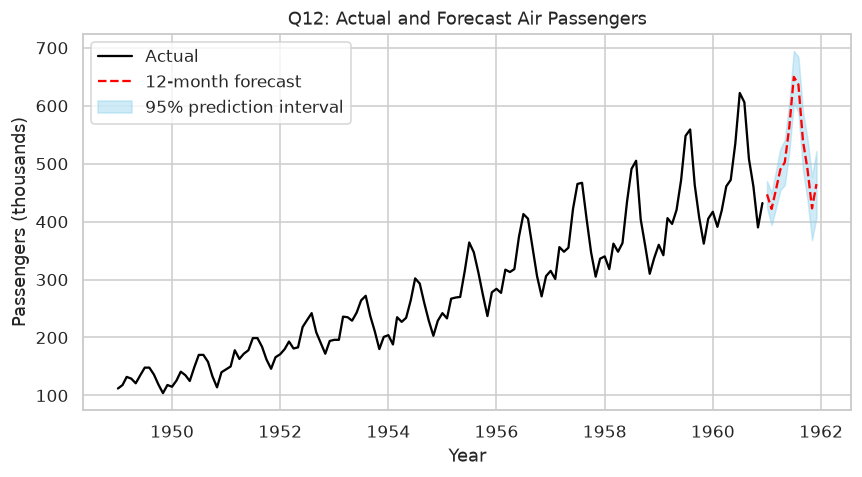

In [31]:
forecast_result = fit.get_forecast(steps=12)
forecast_vals = forecast_result.predicted_mean
intervals = forecast_result.conf_int(alpha=.05)
forecast_table = pd.DataFrame({"Forecast": forecast_vals,
                               "Lower 95%": intervals.iloc[:, 0], "Upper 95%": intervals.iloc[:, 1]})
show("Q11: Forecasts for 1961 (thousands of passengers)", forecast_table)
plt.plot(AirPassengers.index, AirPassengers, color="black", label="Actual")
plt.plot(forecast_vals.index, forecast_vals, color="red", linestyle="--", label="12-month forecast")
plt.fill_between(forecast_vals.index, intervals.iloc[:, 0], intervals.iloc[:, 1], color="skyblue", alpha=.4, label="95% prediction interval")
plt.legend()
finish("Q12: Actual and Forecast Air Passengers", "Year", "Passengers (thousands)")


## Assignment 7 — One, Two and Multiple Variable Analysis

This assignment combines univariate summaries, binned frequencies, categorical cross-tabulations, and grouped statistics. It then explores numerical relationships with correlations, regression, faceted box plots, grouped error bars, a heatmap, and a scatterplot matrix.

### Questions

1. Load the dataset shared via email
2. Compute summary statistics: Mean, Median, Minimum, Maximum, Range, Variance, Standard Deviation, Interquartile Range (IQR), Skewness (using e1071::skewness), and Kurtosis (using e1071::kurtosis).
3. Store these values in a single structured data.frame or named vector and print it.
4. Create a frequency distribution table and a relative frequency distribution table for a categorical variable. Generate a Pie Chart and a Bar Plot to represent the distribution.
5. Create a frequency distribution table with bin intervals for a numerical variable. Plot its Histogram and a Box Plot to check for outliers.
6. Choose two categorical variables: Construct a Contingency Table (Cross-tabulation) and compute the row/column percentages using prop.table()
7. Create a Stacked Bar Plot or Grouped Bar Plot to visualize the relationship.
8. Select one categorical variable and one numerical variable: Compute the mean, median, and standard deviation of the numerical variable grouped by each category using aggregate()
9. Generate Side-by-Side Box Plots and a Violin Plot to visualize the numerical distribution across categories.
10. Select two numerical variables: Calculate the Pearson and Spearman Correlation Coefficients (cor()) and Construct a Scatter Plot with a fitted linear regression trend line.
11. Select two categorical features and one numerical feature: Calculate summary statistics(Mean and Standard Deviation) for the numerical variable across all combinations of the two categorical variables and Create a Faceted Box Plot and a Grouped Bar Chart with Error Bars.
12. Select one categorical variable and two numerical variables: Construct a Scatter Plot ofthe two numerical features where points are colored/shaped by the categorical feature. Compute a correlation matrix between the two numerical variables separately for each category level.
13. Select at least 3 numerical features from the dataset: Generate a full Correlation Matrixand plot it as a Heatmap
14. Produce a Pairs Plot / Scatterplot Matrix to examine pairwise relationships and distributions simultaneously


### Q1–Q3 Numerical summary statistics


In [32]:
df = load_horse()
pulse_clean = df["pulse"].dropna()
n = len(pulse_clean)
centered = pulse_clean - pulse_clean.mean()
sample_sd = pulse_clean.std(ddof=1)
summary_df = pd.DataFrame({"Statistic": ["Mean", "Median", "Minimum", "Maximum", "Range", "Variance", "SD", "IQR", "Skewness", "Kurtosis"],
    "Value": [pulse_clean.mean(), pulse_clean.median(), pulse_clean.min(), pulse_clean.max(),
              np.ptp(pulse_clean), pulse_clean.var(ddof=1), sample_sd,
              pulse_clean.quantile(.75) - pulse_clean.quantile(.25),
              (centered**3).mean() / sample_sd**3,
              (centered**4).mean() / sample_sd**4 - 3]})
show("Pulse statistics (e1071 default type 3 skewness and excess kurtosis)", summary_df)


Pulse statistics (e1071 default type 3 skewness and excess kurtosis)


,Statistic,Value
0,Mean,75.544554
1,Median,64.000000
2,Minimum,38.000000
3,Maximum,164.000000
4,Range,126.000000
5,Variance,940.790495
6,SD,30.672308
7,IQR,44.000000
8,Skewness,0.937582
9,Kurtosis,0.089239


### Q4–Q5 Frequency distributions


Outcome frequencies


,Frequency,Relative frequency
outcome,,
died,30,0.275229
euthanized,15,0.137615
lived,64,0.587156


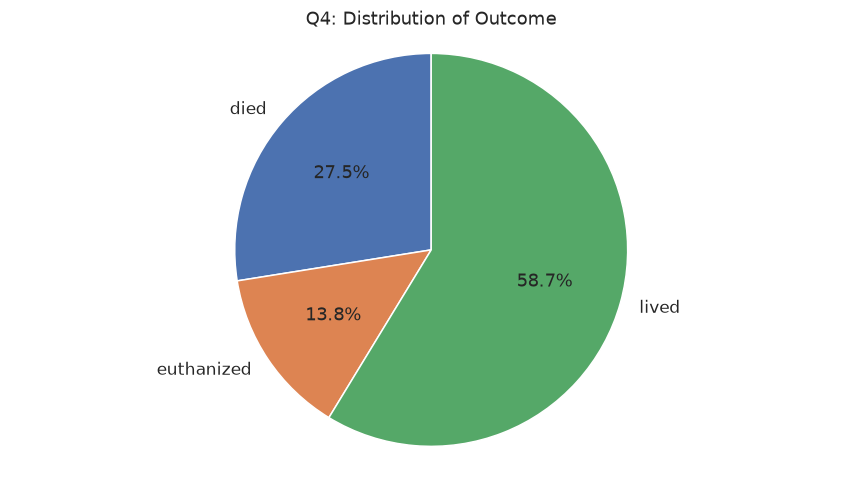

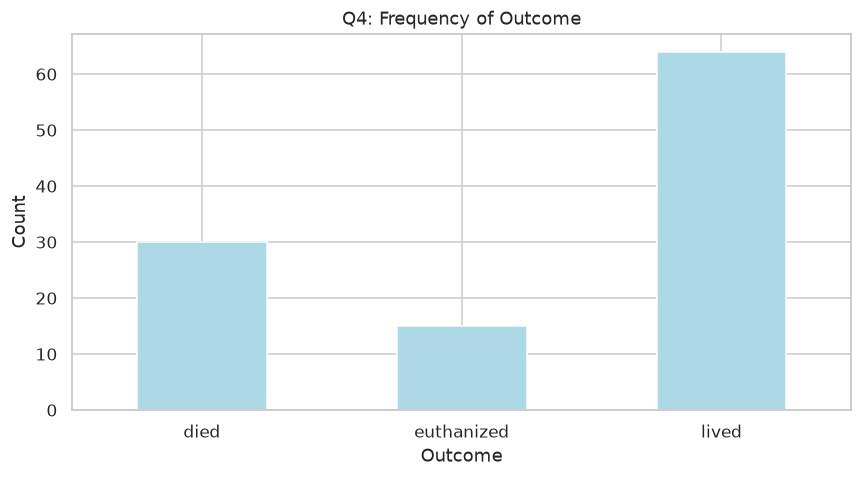

Q5: Pulse frequency by interval


pulse
[30, 50)      23
[50, 70)      31
[70, 90)      18
[90, 110)     14
[110, 130)     7
[130, 150)     5
[150, 170)     3
[170, 190)     0
Name: count, dtype: int64

Non-missing pulse values outside [30,190): 0


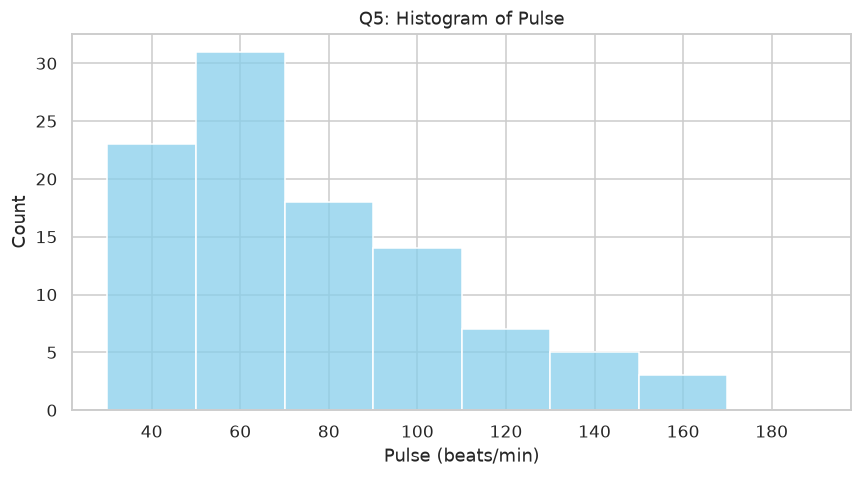

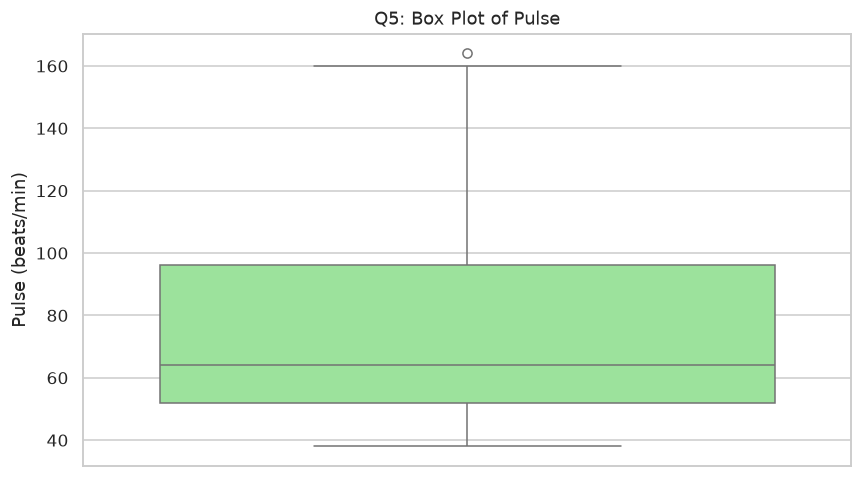

In [33]:
freq_table = df["outcome"].value_counts().sort_index()
rel_freq_table = freq_table / freq_table.sum()
show("Outcome frequencies", pd.DataFrame({"Frequency": freq_table, "Relative frequency": rel_freq_table}))
plt.pie(freq_table, labels=freq_table.index, autopct="%1.1f%%", startangle=90)
plt.axis("equal")
finish("Q4: Distribution of Outcome")
freq_table.plot.bar(rot=0, color="lightblue")
finish("Q4: Frequency of Outcome", "Outcome", "Count")
pulse_bins = pd.cut(df["pulse"], bins=np.arange(30, 191, 20), right=False)
pulse_freq = pulse_bins.value_counts(sort=False)
show("Q5: Pulse frequency by interval", pulse_freq)
print("Non-missing pulse values outside [30,190):", int((df["pulse"].notna() & pulse_bins.isna()).sum()))
sns.histplot(data=df, x="pulse", bins=np.arange(30, 191, 20), color="skyblue")
finish("Q5: Histogram of Pulse", "Pulse (beats/min)", "Count")
sns.boxplot(y=df["pulse"], color="lightgreen")
finish("Q5: Box Plot of Pulse", ylabel="Pulse (beats/min)")


### Q6–Q9 Cross-tabulations and grouped distributions


Surgery × Outcome


outcome,died,euthanized,lived
surgery,,,
no,9,8,34
yes,21,7,30


Row percentages


outcome,died,euthanized,lived
surgery,,,
no,17.647059,15.686275,66.666667
yes,36.206897,12.068966,51.724138


Column percentages


outcome,died,euthanized,lived
surgery,,,
no,30.0,53.333333,53.125
yes,70.0,46.666667,46.875


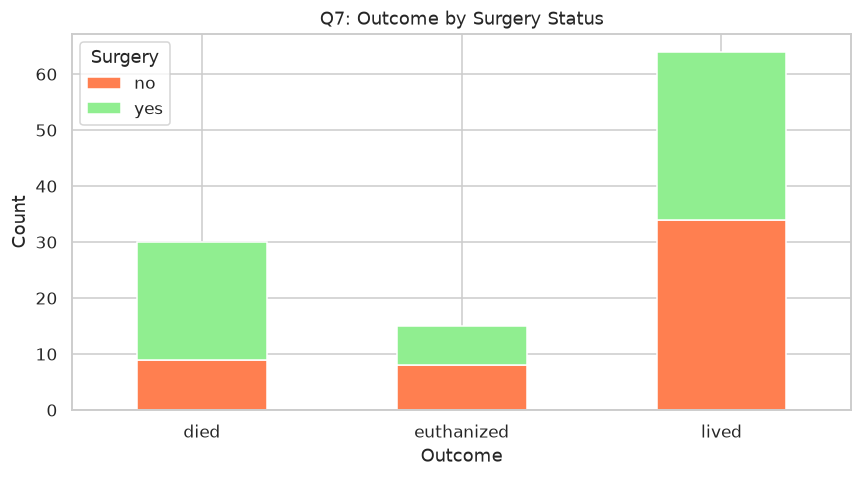

Q8: Packed cell volume by outcome


,Mean,Median,SD
outcome,,,
died,52.461538,51.5,10.955294
euthanized,53.142857,52.0,8.565199
lived,43.950000,43.5,8.387693


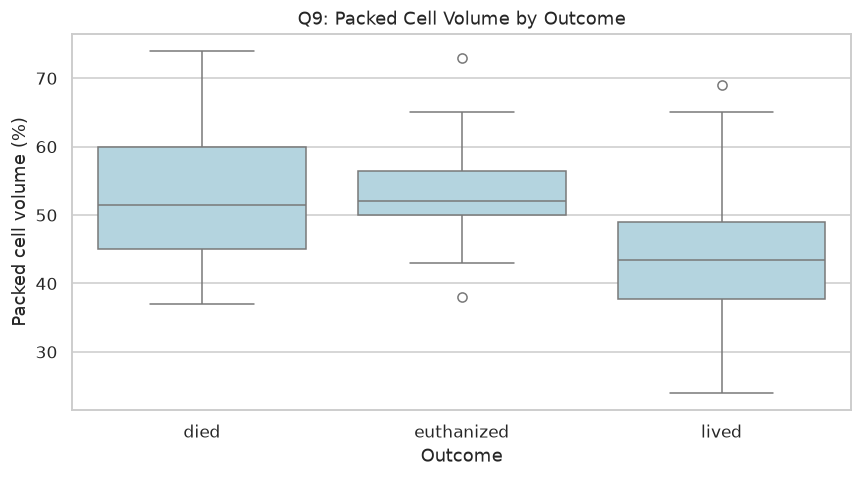

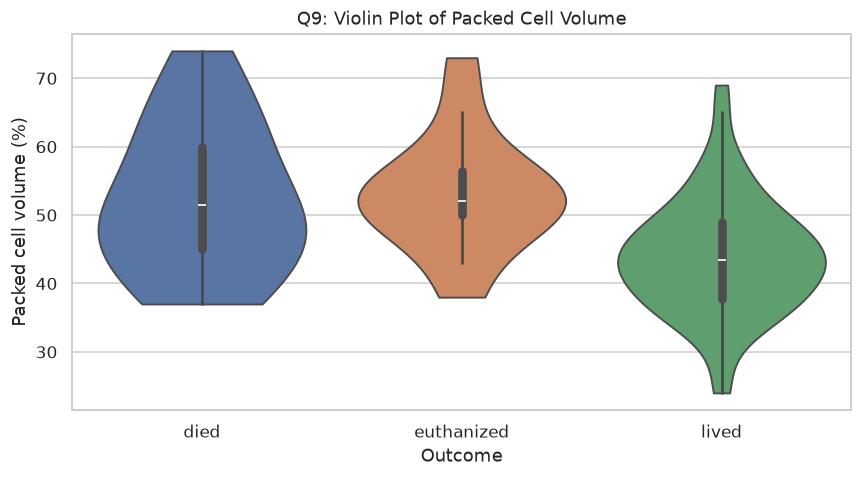

In [34]:
ctable = pd.crosstab(df["surgery"], df["outcome"])
show("Surgery × Outcome", ctable)
row_pct = ctable.div(ctable.sum(axis=1), axis=0) * 100
col_pct = ctable.div(ctable.sum(axis=0), axis=1) * 100
show("Row percentages", row_pct)
show("Column percentages", col_pct)
ctable.T.plot.bar(stacked=True, rot=0, color=["coral", "lightgreen"])
plt.legend(title="Surgery")
finish("Q7: Outcome by Surgery Status", "Outcome", "Count")
grouped_stats = df.groupby("outcome")["packed_cell_volume"].agg(Mean="mean", Median="median", SD="std")
show("Q8: Packed cell volume by outcome", grouped_stats)
sns.boxplot(data=df, x="outcome", y="packed_cell_volume", color="lightblue")
finish("Q9: Packed Cell Volume by Outcome", "Outcome", "Packed cell volume (%)")
sns.violinplot(data=df, x="outcome", y="packed_cell_volume", hue="outcome", cut=0, legend=False)
finish("Q9: Violin Plot of Packed Cell Volume", "Outcome", "Packed cell volume (%)")


### Q10 Correlation and fitted regression


Pearson correlation: 0.4061701397352422
Spearman correlation: 0.4888465753691219


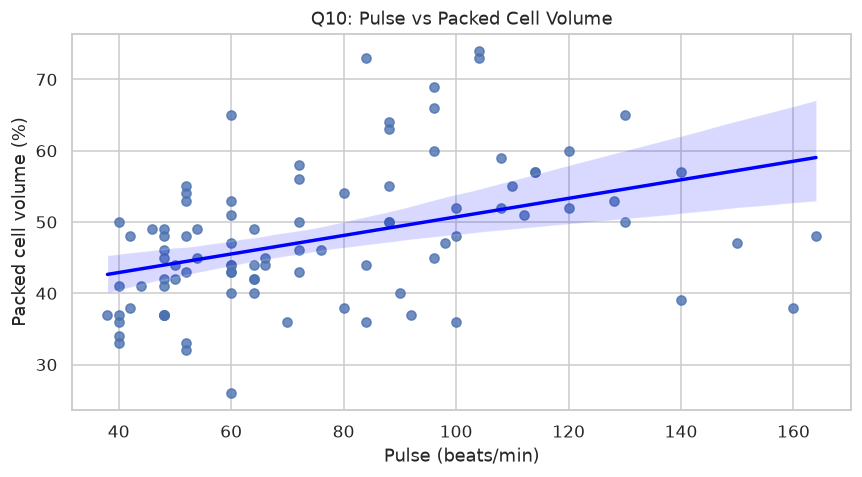

In [35]:
num_pair = df[["pulse", "packed_cell_volume"]].dropna()
print("Pearson correlation:", num_pair.corr(method="pearson").iloc[0, 1])
print("Spearman correlation:", num_pair.corr(method="spearman").iloc[0, 1])
sns.regplot(data=num_pair, x="pulse", y="packed_cell_volume", line_kws={"color": "blue"})
finish("Q10: Pulse vs Packed Cell Volume", "Pulse (beats/min)", "Packed cell volume (%)")


### Q11 Two categorical variables and one numerical variable


Total protein by surgery and outcome


,surgery,outcome,Mean,SD
0,no,died,7.000000,1.009950
1,no,euthanized,16.687500,26.405705
2,no,lived,21.487097,27.160360
3,yes,died,6.968750,0.935036
4,yes,euthanized,67.000000,9.859006
5,yes,lived,24.517241,29.601135


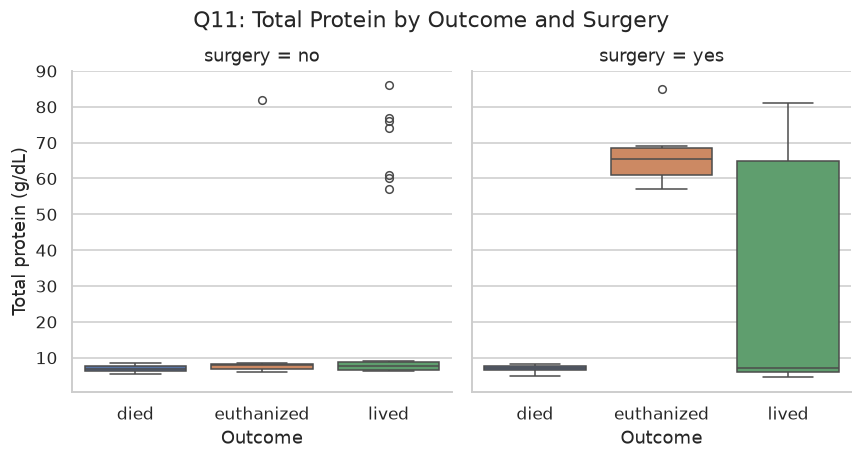

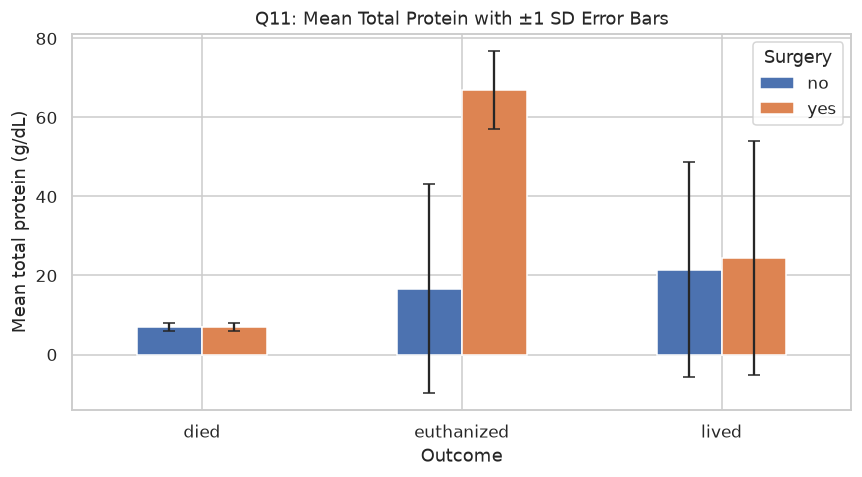

In [36]:
cat_stats_df = df.groupby(["surgery", "outcome"])["total_protein"].agg(Mean="mean", SD="std").reset_index()
show("Total protein by surgery and outcome", cat_stats_df)
g = sns.catplot(data=df.dropna(subset=["surgery", "outcome", "total_protein"]), x="outcome", y="total_protein", col="surgery", hue="outcome", kind="box", height=4)
g.set_axis_labels("Outcome", "Total protein (g/dL)")
g.figure.suptitle("Q11: Total Protein by Outcome and Surgery", y=1.04)
plt.show()
means = cat_stats_df.pivot(index="outcome", columns="surgery", values="Mean")
errors = cat_stats_df.pivot(index="outcome", columns="surgery", values="SD").reindex(index=means.index, columns=means.columns)
means.plot.bar(yerr=errors, capsize=4, rot=0)
plt.legend(title="Surgery")
finish("Q11: Mean Total Protein with ±1 SD Error Bars", "Outcome", "Mean total protein (g/dL)")


### Q12–Q14 Group-specific correlations and multiple variables


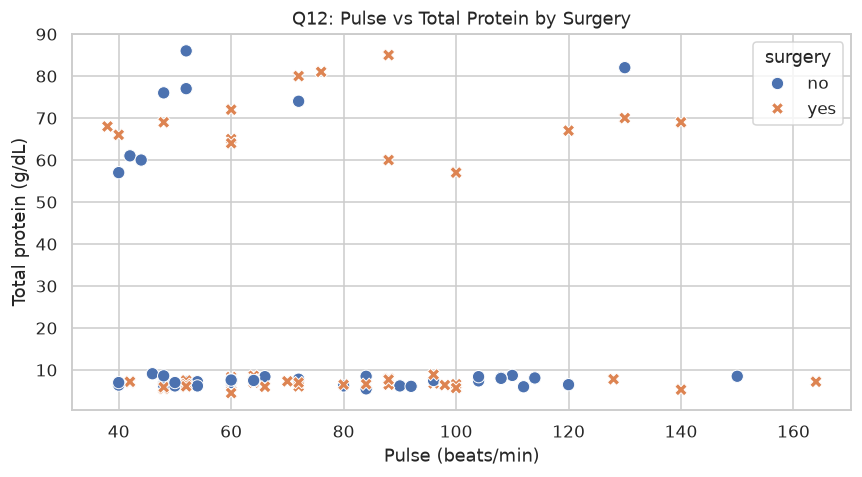

Q12: Correlation matrix for surgery=no


,pulse,total_protein
pulse,1.000000,-0.146503
total_protein,-0.146503,1.000000


Q12: Correlation matrix for surgery=yes


,pulse,total_protein
pulse,1.000000,0.060133
total_protein,0.060133,1.000000


Q13: Full correlation matrix


,rectal_temp,pulse,respiratory_rate,packed_cell_volume,total_protein
rectal_temp,1.000000,0.110048,0.251167,-0.022367,-0.086338
pulse,0.110048,1.000000,0.436753,0.448625,-0.034349
respiratory_rate,0.251167,0.436753,1.000000,-0.015595,-0.246463
packed_cell_volume,-0.022367,0.448625,-0.015595,1.000000,-0.033432
total_protein,-0.086338,-0.034349,-0.246463,-0.033432,1.000000


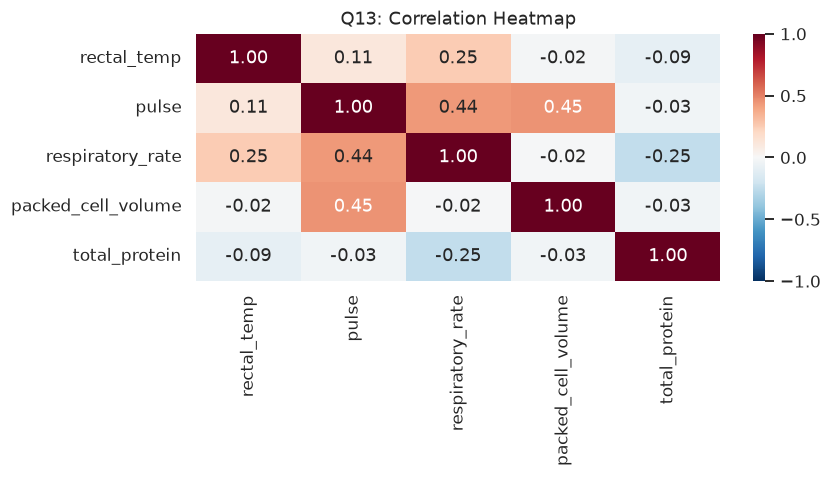

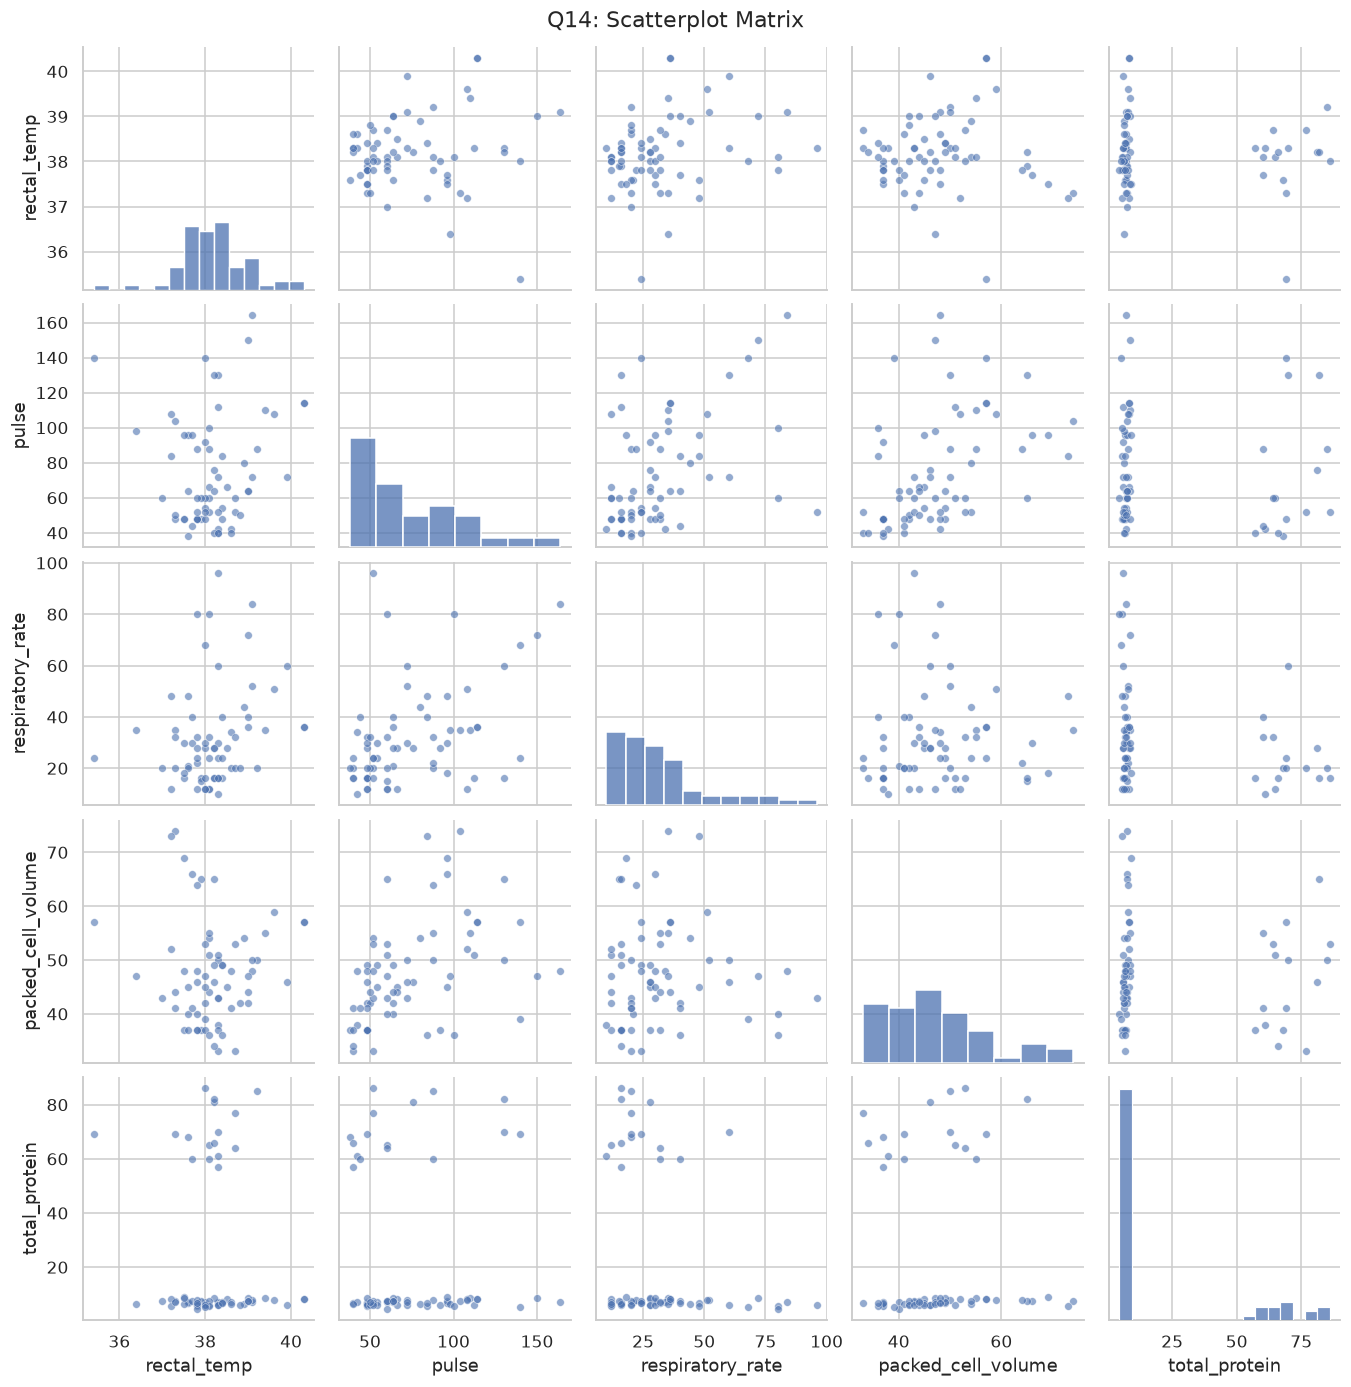

In [37]:
df_sub12 = df[["surgery", "pulse", "total_protein"]].dropna()
sns.scatterplot(data=df_sub12, x="pulse", y="total_protein", hue="surgery", style="surgery", s=65)
finish("Q12: Pulse vs Total Protein by Surgery", "Pulse (beats/min)", "Total protein (g/dL)")
for surgery, group in df_sub12.groupby("surgery"):
    show(f"Q12: Correlation matrix for surgery={surgery}", group[["pulse", "total_protein"]].corr())
num_df = df[clinical_columns].dropna()
cor_mat = num_df.corr()
show("Q13: Full correlation matrix", cor_mat)
sns.heatmap(cor_mat, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f")
finish("Q13: Correlation Heatmap")
g = sns.pairplot(num_df, diag_kind="hist", plot_kws={"s": 25, "alpha": .6})
g.figure.suptitle("Q14: Scatterplot Matrix", y=1.01)
plt.show()


## Assignment 8 — K-Means and Hierarchical Clustering

This assignment prepares numeric data by removing the hospital identifier, imputing column means, and removing constant columns before standardization. It runs K-means, plots the WCSS elbow curve, and performs Euclidean Ward hierarchical clustering with three final clusters. The source solution’s K=3 is retained as a choice to inspect against the elbow curve; outcome counts do not determine the unsupervised optimum.

### Questions

**K-Means Clustering**

1. Load the dataset shared through e-mail.
2. View the dataset
3. Check missing values
4. Check for the dependent variable distribution. (table)
5. Select only numerical features for K-Means clustering (Others remove it).
6. Standardize the data. (scale)
7. Apply K-Means Clustering (kmeans) for center as 2.
8. Display K-Means results
9. Display cluster centers
10. Calculate WCSS for K = 1 to 10
11. Display the elbow plot.
12. Apply K-means clustering based on the elbow recommendation.

**Hierarchical Clustering**

1. Load the dataset shared through e-mail.
2. View the dataset
3. Check missing values
4. Select only numerical attributes
5. Standardize the data (scale)
6. Calculate Euclidean distance (dist)
7. Perform Hierarchical Clustering using Ward's method (hclust)
8. Plot the dendrogram. (plot)
9. Divide the data into 3 clusters and Display cluster assignments(cutree)
10. Display number of samples in each cluster. (table)


### K-Means Q1–Q6 Load and prepare the data


In [38]:
data = load_horse()
show("Dataset preview", data.head(6))
data.info()
show("Missing values", data.isna().sum())
show("Outcome distribution", data["outcome"].value_counts())
num_data, scaled_data = prepare_clusters(data)
show("Numerical features used", num_data.head(6))
show("Standardized data (sample standard deviation, as in R scale)", scaled_data.head(6))


Dataset preview


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,NaN,decreased,distend_large,45.0,8.4,NaN,NaN,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,NaN,normal,normal,33.0,6.7,NaN,NaN,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,NaN,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,NaN,NaN,NaN,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,NaN,decreased,firm,NaN,NaN,NaN,NaN,lived,no,0.0,0.0,0.0,no


<class 'pandas.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   surgery                110 non-null    str    
 1   age                    110 non-null    str    
 2   hospital_number        110 non-null    int64  
 3   rectal_temp            85 non-null     float64
 4   pulse                  101 non-null    float64
 5   respiratory_rate       87 non-null     float64
 6   temp_of_extremities    90 non-null     str    
 7   peripheral_pulse       83 non-null     str    
 8   mucous_membrane        94 non-null     str    
 9   capillary_refill_time  99 non-null     str    
 10  pain                   90 non-null     str    
 11  peristalsis            91 non-null     str    
 12  abdominal_distention   86 non-null     str    
 13  nasogastric_tube       73 non-null     str    
 14  nasogastric_reflux     72 non-null     str    
 15  nasogastric_reflu

surgery                   0
age                       0
hospital_number           0
rectal_temp              25
pulse                     9
respiratory_rate         23
temp_of_extremities      20
peripheral_pulse         27
mucous_membrane          16
capillary_refill_time    11
pain                     20
peristalsis              19
abdominal_distention     24
nasogastric_tube         37
nasogastric_reflux       38
nasogastric_reflux_ph    89
rectal_exam_feces        30
abdomen                  36
packed_cell_volume        9
total_protein            11
abdomo_appearance        61
abdomo_protein           72
outcome                   1
surgical_lesion           1
lesion_1                  1
lesion_2                  1
lesion_3                  1
cp_data                   1
dtype: int64

Outcome distribution


outcome
lived         64
died          30
euthanized    15
Name: count, dtype: int64

Numerical features used


,rectal_temp,pulse,respiratory_rate,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdomo_protein,lesion_1,lesion_2
0,38.500000,66.000000,28.000000,4.87619,45.000000,8.400000,3.184211,11300.0,0.0
1,39.200000,88.000000,20.000000,4.87619,50.000000,85.000000,2.000000,2208.0,0.0
2,38.300000,40.000000,24.000000,4.87619,33.000000,6.700000,3.184211,0.0,0.0
3,39.100000,164.000000,84.000000,5.00000,48.000000,7.200000,5.300000,2208.0,0.0
4,37.300000,104.000000,35.000000,4.87619,74.000000,7.400000,3.184211,4300.0,0.0
5,38.149412,75.544554,31.954023,4.87619,47.336634,21.077778,3.184211,0.0,0.0


Standardized data (sample standard deviation, as in R scale)


,rectal_temp,pulse,respiratory_rate,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdomo_protein,lesion_1,lesion_2
0,5.098825e-01,-3.248796e-01,-2.362446e-01,3.067223e-15,-0.243023,-0.499604,1.279204e-15,2.345588,-0.096225
1,1.527936e+00,4.239611e-01,-7.142279e-01,3.067223e-15,0.277005,2.519038,-1.137044e+00,-0.259830,-0.096225
2,2.190099e-01,-1.209873e+00,-4.752362e-01,3.067223e-15,-1.491092,-0.566597,1.279204e-15,-0.892558,-0.096225
3,1.382500e+00,3.010866e+00,3.109638e+00,1.425207e-01,0.068994,-0.546894,2.031519e+00,-0.259830,-0.096225
4,-1.235353e+00,9.685726e-01,1.819908e-01,3.067223e-15,2.773143,-0.539012,1.279204e-15,0.339657,-0.096225
5,1.033387e-14,4.837121e-16,-2.122672e-16,3.067223e-15,0.000000,0.000000,1.279204e-15,-0.892558,-0.096225


### K-Means Q7–Q9 Fit two clusters and inspect centers


In [39]:
kmeans_k2 = KMeans(n_clusters=2, n_init=25, random_state=42).fit(scaled_data)
print(kmeans_k2)
print("Iterations:", kmeans_k2.n_iter_)
print("Total within-cluster sum of squares:", kmeans_k2.inertia_)
show("Cluster assignments (1-based labels)", pd.Series(kmeans_k2.labels_ + 1, index=data.index, name="Cluster"))
show("Cluster sizes", pd.Series(kmeans_k2.labels_ + 1).value_counts().sort_index())
show("Standardized cluster centers", pd.DataFrame(kmeans_k2.cluster_centers_, columns=scaled_data.columns, index=["Cluster 1", "Cluster 2"]))


KMeans(n_clusters=2, n_init=25, random_state=42)
Iterations: 7
Total within-cluster sum of squares: 844.450618140584
Cluster assignments (1-based labels)


0      2
1      1
2      2
3      2
4      2
      ..
105    2
106    2
107    2
108    1
109    2
Name: Cluster, Length: 110, dtype: int32

Cluster sizes


1    22
2    88
Name: count, dtype: int64

Standardized cluster centers


,rectal_temp,pulse,respiratory_rate,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdomo_protein,lesion_1,lesion_2
Cluster 1,-0.104994,-0.095895,-0.340070,-0.706624,-0.072832,1.938668,-0.560482,-0.327979,0.380526
Cluster 2,0.026249,0.023974,0.085017,0.176656,0.018208,-0.484667,0.140121,0.081995,-0.095132


### K-Means Q10–Q12 Elbow curve and three-cluster solution


WCSS for K=1 to 10


,K,WCSS
0,1,981.000000
1,2,844.450618
2,3,728.934083
3,4,619.333438
4,5,549.445005
5,6,494.692080
6,7,429.794520
7,8,388.657149
8,9,349.890482
9,10,321.053288


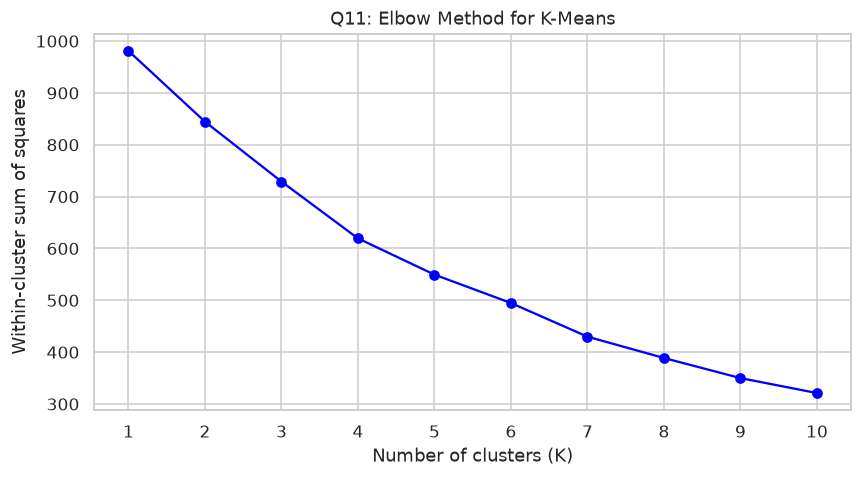

Q12: K=3 retained from the submitted R solution; inspect the elbow plot to assess this choice.
KMeans(n_clusters=3, n_init=25, random_state=42)
WCSS: 728.9340825083096
Cluster sizes


1    34
2    75
3     1
Name: count, dtype: int64

Cluster centers


,rectal_temp,pulse,respiratory_rate,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdomo_protein,lesion_1,lesion_2
Cluster 1,0.422017,0.851986,0.763412,3.127717e-01,0.620642,-0.423184,0.445454,0.486613,-0.096225
Cluster 2,-0.192295,-0.410948,-0.333370,-1.417898e-01,-0.305852,0.159832,-0.186778,-0.217137,-0.094942
Cluster 3,0.073574,1.853566,-0.953220,3.067223e-15,1.837091,2.400814,-1.137044,-0.259543,10.392305


In [40]:
wcss = [KMeans(n_clusters=k, n_init=25, random_state=42).fit(scaled_data).inertia_ for k in range(1, 11)]
wcss_results = pd.DataFrame({"K": range(1, 11), "WCSS": wcss})
show("WCSS for K=1 to 10", wcss_results)
plt.plot(wcss_results["K"], wcss_results["WCSS"], "o-", color="blue")
plt.xticks(range(1, 11))
finish("Q11: Elbow Method for K-Means", "Number of clusters (K)", "Within-cluster sum of squares")
chosen_k = 3
kmeans_optimal = KMeans(n_clusters=chosen_k, n_init=25, random_state=42).fit(scaled_data)
print("Q12: K=3 retained from the submitted R solution; inspect the elbow plot to assess this choice.")
print(kmeans_optimal)
print("WCSS:", kmeans_optimal.inertia_)
show("Cluster sizes", pd.Series(kmeans_optimal.labels_ + 1).value_counts().sort_index())
show("Cluster centers", pd.DataFrame(kmeans_optimal.cluster_centers_, columns=scaled_data.columns, index=[f"Cluster {i}" for i in range(1, chosen_k + 1)]))


### Hierarchical Clustering Q1–Q7 Prepare distances and apply Ward linkage


In [41]:
hc_data = load_horse()
show("Dataset preview", hc_data.head(6))
hc_data.info()
show("Missing values", hc_data.isna().sum())
num_hc, scaled_hc = prepare_clusters(hc_data)
show("Numerical attributes", num_hc.head(6))
show("Standardized attributes", scaled_hc.head(6))
dist_matrix = pdist(scaled_hc.to_numpy(), metric="euclidean")
print("Number of pairwise Euclidean distances:", len(dist_matrix))
show("First 10 pairwise distances", pd.Series(dist_matrix).head(10))
hc_ward = linkage(dist_matrix, method="ward")
show("Ward linkage matrix (first six merges)", pd.DataFrame(hc_ward, columns=["Left", "Right", "Distance", "Samples"]).head(6))


Dataset preview


,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,capillary_refill_time,pain,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,no,adult,530101,38.5,66.0,28.0,cool,reduced,NaN,more_3_sec,extreme_pain,absent,severe,NaN,NaN,NaN,decreased,distend_large,45.0,8.4,NaN,NaN,died,no,11300.0,0.0,0.0,no
1,yes,adult,534817,39.2,88.0,20.0,NaN,NaN,pale_cyanotic,less_3_sec,mild_pain,absent,slight,NaN,NaN,NaN,absent,other,50.0,85.0,cloudy,2.0,euthanized,no,2208.0,0.0,0.0,no
2,no,adult,530334,38.3,40.0,24.0,normal,normal,pale_pink,less_3_sec,mild_pain,hypomotile,none,NaN,NaN,NaN,normal,normal,33.0,6.7,NaN,NaN,lived,no,0.0,0.0,0.0,yes
3,yes,young,5290409,39.1,164.0,84.0,cold,normal,dark_cyanotic,more_3_sec,depressed,absent,severe,none,less_1_liter,5.0,decreased,NaN,48.0,7.2,serosanguious,5.3,died,yes,2208.0,0.0,0.0,yes
4,no,adult,530255,37.3,104.0,35.0,NaN,NaN,dark_cyanotic,more_3_sec,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,died,no,4300.0,0.0,0.0,no
5,no,adult,528355,NaN,NaN,NaN,warm,normal,pale_pink,less_3_sec,depressed,hypomotile,slight,slight,none,NaN,decreased,firm,NaN,NaN,NaN,NaN,lived,no,0.0,0.0,0.0,no


<class 'pandas.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   surgery                110 non-null    str    
 1   age                    110 non-null    str    
 2   hospital_number        110 non-null    int64  
 3   rectal_temp            85 non-null     float64
 4   pulse                  101 non-null    float64
 5   respiratory_rate       87 non-null     float64
 6   temp_of_extremities    90 non-null     str    
 7   peripheral_pulse       83 non-null     str    
 8   mucous_membrane        94 non-null     str    
 9   capillary_refill_time  99 non-null     str    
 10  pain                   90 non-null     str    
 11  peristalsis            91 non-null     str    
 12  abdominal_distention   86 non-null     str    
 13  nasogastric_tube       73 non-null     str    
 14  nasogastric_reflux     72 non-null     str    
 15  nasogastric_reflu

surgery                   0
age                       0
hospital_number           0
rectal_temp              25
pulse                     9
respiratory_rate         23
temp_of_extremities      20
peripheral_pulse         27
mucous_membrane          16
capillary_refill_time    11
pain                     20
peristalsis              19
abdominal_distention     24
nasogastric_tube         37
nasogastric_reflux       38
nasogastric_reflux_ph    89
rectal_exam_feces        30
abdomen                  36
packed_cell_volume        9
total_protein            11
abdomo_appearance        61
abdomo_protein           72
outcome                   1
surgical_lesion           1
lesion_1                  1
lesion_2                  1
lesion_3                  1
cp_data                   1
dtype: int64

Numerical attributes


...

,rectal_temp,pulse,respiratory_rate,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdomo_protein,lesion_1,lesion_2
0,5.098825e-01,-3.248796e-01,-2.362446e-01,3.067223e-15,-0.243023,-0.499604,1.279204e-15,2.345588,-0.096225
1,1.527936e+00,4.239611e-01,-7.142279e-01,3.067223e-15,0.277005,2.519038,-1.137044e+00,-0.259830,-0.096225
2,2.190099e-01,-1.209873e+00,-4.752362e-01,3.067223e-15,-1.491092,-0.566597,1.279204e-15,-0.892558,-0.096225
3,1.382500e+00,3.010866e+00,3.109638e+00,1.425207e-01,0.068994,-0.546894,2.031519e+00,-0.259830,-0.096225
4,-1.235353e+00,9.685726e-01,1.819908e-01,3.067223e-15,2.773143,-0.539012,1.279204e-15,0.339657,-0.096225
5,1.033387e-14,4.837121e-16,-2.122672e-16,3.067223e-15,0.000000,0.000000,1.279204e-15,-0.892558,-0.096225


Number of pairwise Euclidean distances: 5995
First 10 pairwise distances


0    4.391966
1    3.601763
2    5.841127
3    4.244568
4    3.348969
5    2.799206
6    2.675171
7    2.575690
8    3.530489
9    3.606955
dtype: float64

Ward linkage matrix (first six merges)


,Left,Right,Distance,Samples
0,8.0,93.0,0.285616,2.0
1,52.0,78.0,0.320926,2.0
2,89.0,102.0,0.410868,2.0
3,96.0,111.0,0.445145,3.0
4,7.0,57.0,0.450649,2.0
5,94.0,107.0,0.529690,2.0


### Hierarchical Clustering Q8–Q10 Dendrogram and cluster membership


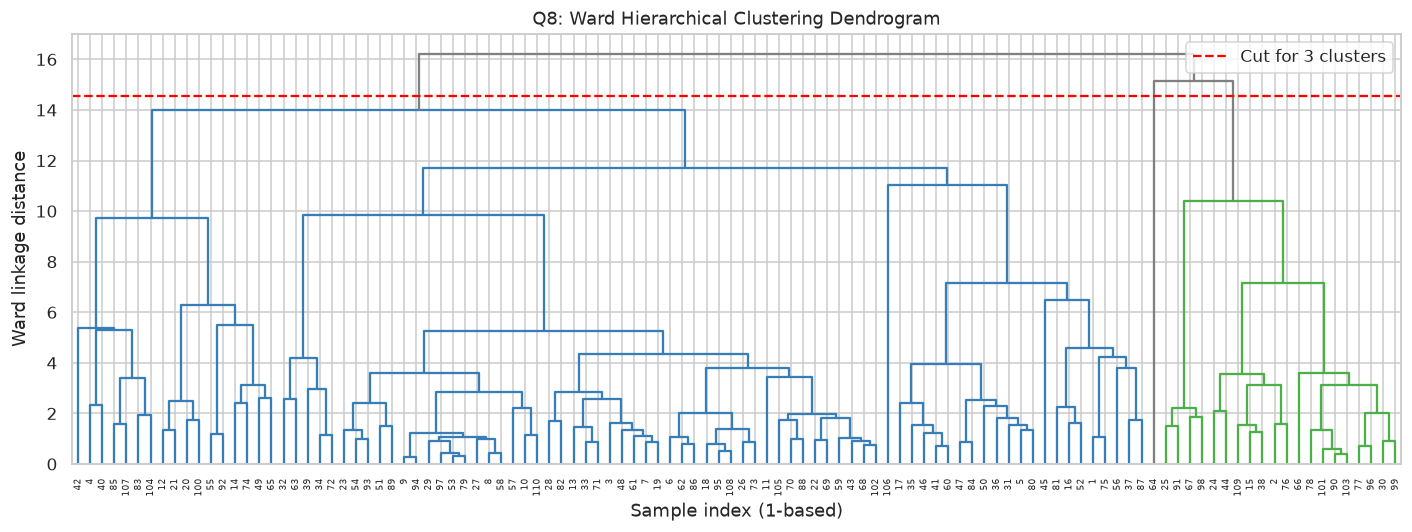

Q9: All cluster assignments:
     Cluster
0          1
1          2
2          1
3          1
4          1
5          1
6          1
7          1
8          1
9          1
10         1
11         1
12         1
13         1
14         2
15         1
16         1
17         1
18         1
19         1
20         1
21         1
22         1
23         2
24         2
25         1
26         1
27         1
28         1
29         2
30         1
31         1
32         1
33         1
34         1
35         1
36         1
37         2
38         1
39         1
40         1
41         1
42         1
43         2
44         1
45         1
46         1
47         1
48         1
49         1
50         1
51         1
52         1
53         1
54         1
55         1
56         1
57         1
58         1
59         1
60         1
61         1
62         1
63         3
64         1
65         2
66         2
67         1
68         1
69         1
70         1
71         1
72         1
73       

Cluster
1    89
2    20
3     1
Name: count, dtype: int64

In [42]:
threshold = (hc_ward[-3, 2] + hc_ward[-2, 2]) / 2
plt.figure(figsize=(13, 5))
set_link_color_palette(["#377eb8", "#4daf4a", "#e41a1c"])
dendrogram(hc_ward, labels=(hc_data.index + 1).astype(str).tolist(), color_threshold=threshold, leaf_rotation=90, leaf_font_size=6, above_threshold_color="gray")
plt.axhline(threshold, color="red", linestyle="--", label="Cut for 3 clusters")
plt.legend()
finish("Q8: Ward Hierarchical Clustering Dendrogram", "Sample index (1-based)", "Ward linkage distance")
cluster_assignments = pd.Series(cut_tree(hc_ward, n_clusters=3).ravel() + 1, index=hc_data.index, name="Cluster")
print("Q9: All cluster assignments:")
print(cluster_assignments.to_frame().to_string())
show("Q10: Samples per cluster", cluster_assignments.value_counts().sort_index())


## Assignment 9 — Principal Component Analysis

This assignment selects numeric columns, removes incomplete records and constant columns, and standardizes each feature before PCA. It reports explained variance, creates a labeled scree plot and biplot, and displays component scores with the registration number in the final plot title.

### Questions

Principal Component Analysis

1. Load the dataset sent to your email into R, and verify that the packages ggplot2, ggfortify, FactoMineR, and factoextra are loaded.
2. Display the total number of rows and columns in the dataset.
3. Extract only the numeric columns, clean the data, and normalize it using the scale() function into an object named data_scaled.
4. Perform Principal Component Analysis on data_scaled using either the PCA() or prcomp() function, and print its summary.
5. Plot a scree plot showing the percentage of variance for each component with data labels, setting the y-axis limit from 0 to 60.
6. Create a PCA biplot with non-overlapping labels and a proper title.
7. Extract the PCA scores into a data frame named pca_scores and display the first six rows.
8. Draw a scatter plot of the first two principal components (PC1 vs. PC2) with blue circular points and your registration number in the title


### Q1–Q3 Load, clean, and standardize


In [43]:
data = load_horse()
print("Python equivalents loaded: pandas, matplotlib, scikit-learn PCA, and adjustText.")
print("Rows:", data.shape[0], "Columns:", data.shape[1])
numeric_data = data.select_dtypes(include="number")
numeric_clean = numeric_data.dropna().copy()
numeric_clean = numeric_clean.loc[:, numeric_clean.std(ddof=1).gt(0)]
data_scaled = (numeric_clean - numeric_clean.mean()) / numeric_clean.std(ddof=1)
print("Complete numeric records:", len(numeric_clean))
print("Retained numeric features:", numeric_clean.columns.tolist())
show("Standardized data", data_scaled.head(6))


Python equivalents loaded: pandas, matplotlib, scikit-learn PCA, and adjustText.
Rows: 110 Columns: 28
Complete numeric records: 8
Retained numeric features: ['hospital_number', 'rectal_temp', 'pulse', 'respiratory_rate', 'nasogastric_reflux_ph', 'packed_cell_volume', 'total_protein', 'abdomo_protein', 'lesion_1']
Standardized data


,hospital_number,rectal_temp,pulse,respiratory_rate,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdomo_protein,lesion_1
3,2.474873,0.317259,1.817030,2.226732,-0.678684,-0.472456,-0.255774,0.506981,-0.571081
10,-0.353857,-0.557938,-0.647592,-0.916889,-2.088937,-1.228385,-1.790421,-0.681802,-0.613230
31,-0.352850,-1.345615,0.408675,-0.916889,0.026442,0.283473,1.023098,1.975476,-0.571583
54,-0.353314,1.367495,0.559570,0.130984,0.731569,1.228385,0.895211,-0.052446,2.034128
64,-0.353192,0.229739,-0.697890,0.130984,0.731569,-1.228385,0.127887,0.297196,-0.618750
73,-0.353904,-0.557938,-0.999681,-0.392953,0.731569,0.661438,0.127887,-1.381085,-0.619251


### Q4 PCA and summary


In [44]:
pca_res = PCA(svd_solver="full")
scores_array = pca_res.fit_transform(data_scaled)
pc_names = [f"PC{i}" for i in range(1, len(pca_res.explained_variance_) + 1)]
pca_var = pca_res.explained_variance_
pca_var_pct = pca_res.explained_variance_ratio_ * 100
pca_summary = pd.DataFrame({"Standard deviation": np.sqrt(pca_var),
                            "Proportion of variance": pca_res.explained_variance_ratio_,
                            "Cumulative proportion": np.cumsum(pca_res.explained_variance_ratio_)}, index=pc_names)
show("PCA summary", pca_summary)


PCA summary


,Standard deviation,Proportion of variance,Cumulative proportion
PC1,1.822424e+00,3.690255e-01,0.369026
PC2,1.633711e+00,2.965568e-01,0.665582
PC3,1.203072e+00,1.608203e-01,0.826403
PC4,8.626836e-01,8.269143e-02,0.909094
PC5,6.559803e-01,4.781224e-02,0.956906
PC6,6.151883e-01,4.205073e-02,0.998957
PC7,9.688417e-02,1.042949e-03,1.000000
PC8,5.046324e-17,2.829488e-34,1.000000


### Q5 Scree plot


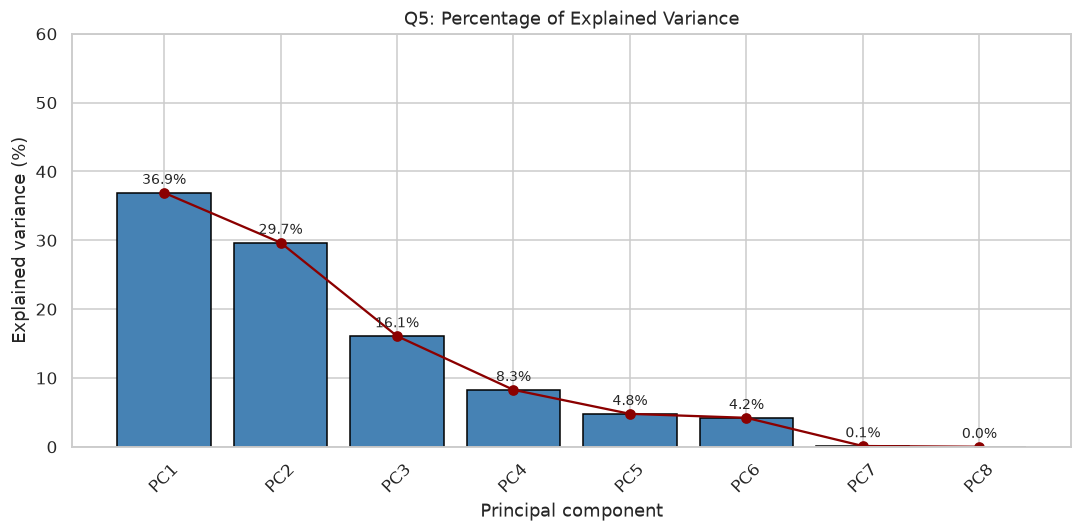

In [45]:
x = np.arange(len(pc_names))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, pca_var_pct, color="steelblue", edgecolor="black")
ax.plot(x, pca_var_pct, "o-", color="darkred")
for pos, value in zip(x, pca_var_pct):
    ax.text(pos, min(value + .8, 58), f"{value:.1f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, pc_names, rotation=45)
ax.set_ylim(0, 60)
finish("Q5: Percentage of Explained Variance", "Principal component", "Explained variance (%)")


The biplot uses scores divided by the component singular values and loading vectors multiplied by those singular values. This gives both elements a shared PCA biplot scaling; arrow directions and relative lengths describe the features. Component signs may be reversed relative to R without changing the PCA result.


### Q6 PCA biplot with non-overlapping feature labels


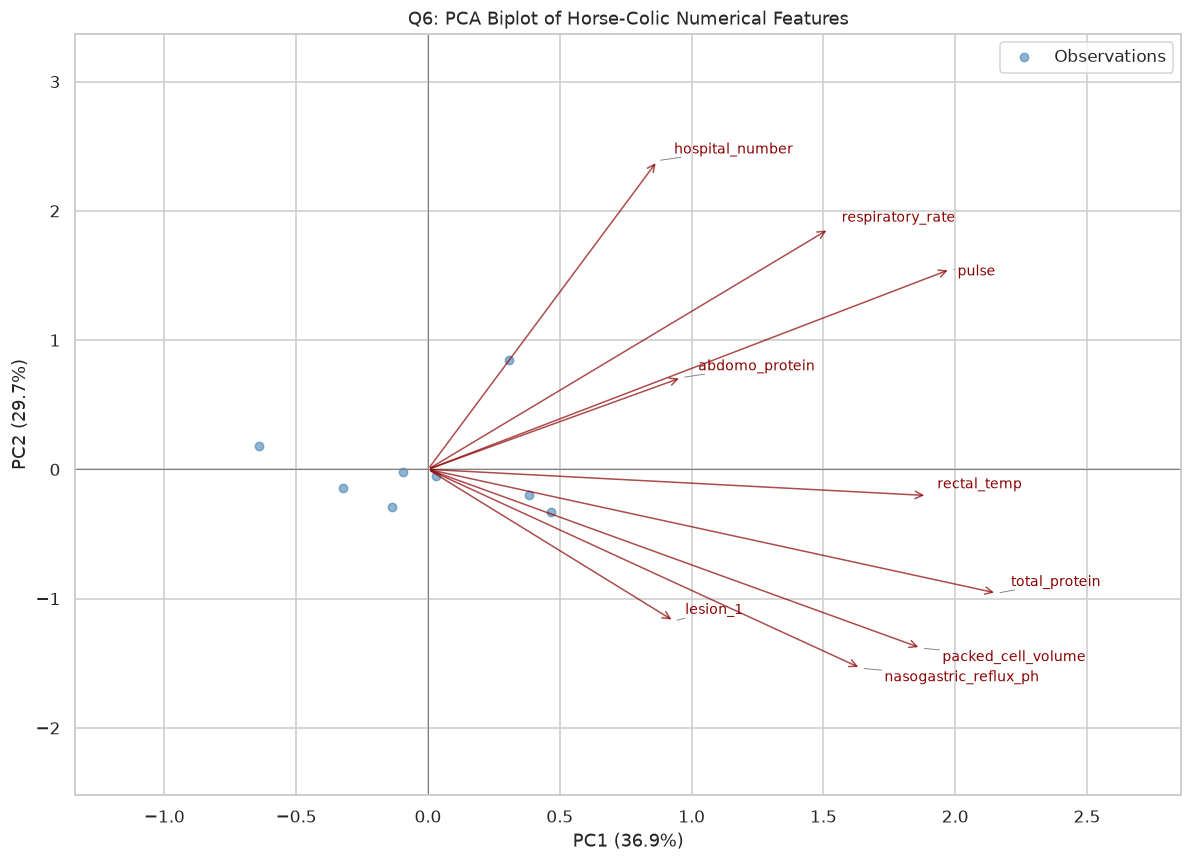

In [46]:
score_plot = scores_array[:, :2] / pca_res.singular_values_[:2]
loading_plot = pca_res.components_[:2].T * pca_res.singular_values_[:2]
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(score_plot[:, 0], score_plot[:, 1], color="steelblue", s=30, alpha=.6, label="Observations")
texts = []
for label, (vx, vy) in zip(numeric_clean.columns, loading_plot):
    ax.annotate("", xy=(vx, vy), xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": "darkred", "alpha": .7})
    texts.append(ax.text(vx, vy, label, color="darkred", fontsize=9))
all_x = np.r_[score_plot[:, 0], loading_plot[:, 0]]
all_y = np.r_[score_plot[:, 1], loading_plot[:, 1]]
margin_x = max(np.ptp(all_x) * .25, .2)
margin_y = max(np.ptp(all_y) * .25, .2)
ax.set_xlim(all_x.min() - margin_x, all_x.max() + margin_x)
ax.set_ylim(all_y.min() - margin_y, all_y.max() + margin_y)
adjust_text(texts, ax=ax, expand=(1.15, 1.25), force_text=(.7, .9), arrowprops={"arrowstyle": "-", "color": "gray", "lw": .6})
ax.axhline(0, color="gray", lw=.7)
ax.axvline(0, color="gray", lw=.7)
ax.legend()
finish("Q6: PCA Biplot of Horse-Colic Numerical Features", f"PC1 ({pca_var_pct[0]:.1f}%)", f"PC2 ({pca_var_pct[1]:.1f}%)")


### Q7–Q8 Component scores and PC1 vs PC2


First six PCA score rows


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
3,1.482824,3.649595,-0.381759,-0.168099,0.057109,-0.349848,0.005201,4.720404e-17
10,-3.083504,0.792074,-0.522422,0.610685,0.541179,0.734424,0.046631,4.720404e-17
31,0.147188,-0.226930,2.785832,0.613142,0.191490,-0.230632,0.007676,4.720404e-17
54,2.254878,-1.415369,-1.024308,1.060463,-0.186660,0.020045,0.119664,4.720404e-17
64,-0.449750,-0.078447,0.413217,-0.938836,-1.279174,0.561559,0.034069,4.720404e-17
73,-0.650567,-1.255936,-0.298436,-1.380162,0.655935,-0.663024,0.076539,4.720404e-17


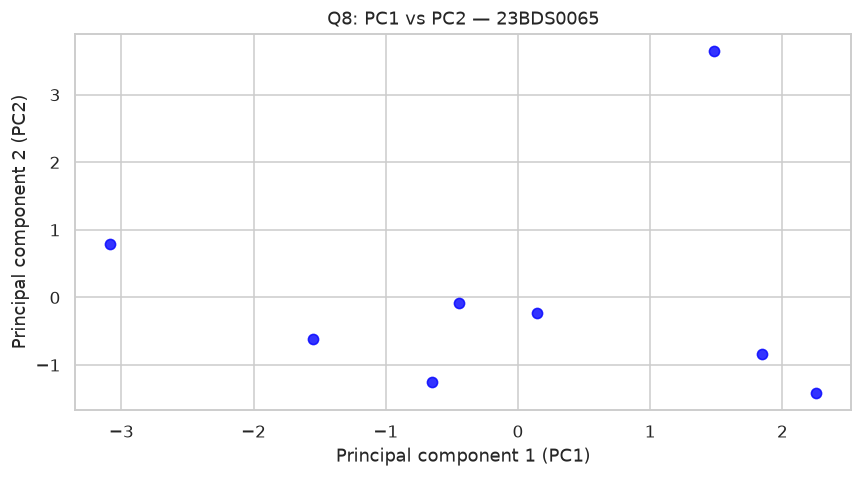

In [47]:
pca_scores = pd.DataFrame(scores_array, columns=pc_names, index=numeric_clean.index)
show("First six PCA score rows", pca_scores.head(6))
plt.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o", s=45, alpha=.8)
finish("Q8: PC1 vs PC2 — 23BDS0065", "Principal component 1 (PC1)", "Principal component 2 (PC2)")
